In [2]:
import os
import os, sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Sequential
import torch.optim as optim
import voxelmorph as vxm
import neurite as ne
import scipy.ndimage

os.environ['VXM_BACKEND'] = 'pytorch'

backend:pytorch
Pytorch


In [3]:
# === Training path settings ===
from pathlib import Path

# このノートブックを起動したフォルダー（通常: .../Saito/yamatoCode）
PROJECT_DIR = Path.cwd()

# 入力データ
TRAIN_DATA_PATH = PROJECT_DIR.parent / 'Data' / 'TrainData_NoBed.npz'

# 学習結果はすべてこのフォルダーへ保存
TRAINING_OUTPUT_DIR = PROJECT_DIR / 'training_outputs_256_128'
RUN_NAME = "pretraining_80k_rerun"

PRETRAIN_OUTPUT_DIR = (
    TRAINING_OUTPUT_DIR
    / RUN_NAME
)
FINETUNE_OUTPUT_DIR = TRAINING_OUTPUT_DIR / 'finetuning_other_patients'
FINETUNE_EVALUATION_DIR = FINETUNE_OUTPUT_DIR / 'evaluation_images'

# モデルファイル
PRETRAIN_CHECKPOINT_PATH = PRETRAIN_OUTPUT_DIR / 'pretrained_model_latest.pth'
FINETUNE_CHECKPOINT_PATH = FINETUNE_OUTPUT_DIR / 'finetuned_model_latest.pth'
FINETUNE_FINAL_MODEL_PATH = FINETUNE_OUTPUT_DIR / 'finetuned_model_final.pth'

for output_dir in [
    PRETRAIN_OUTPUT_DIR,
    FINETUNE_OUTPUT_DIR,
    FINETUNE_EVALUATION_DIR,
]:
    output_dir.mkdir(parents=True, exist_ok=True)

print('Training data           :', TRAIN_DATA_PATH)
print('Pretraining checkpoint  :', PRETRAIN_CHECKPOINT_PATH)
print('Fine-tuning checkpoint  :', FINETUNE_CHECKPOINT_PATH)
print('Fine-tuning evaluations :', FINETUNE_EVALUATION_DIR)


Training data           : d:\Saito\Data\TrainData_NoBed.npz
Pretraining checkpoint  : d:\Saito\yamatoCode\training_outputs_256_128\pretraining_80k_rerun\pretrained_model_latest.pth
Fine-tuning checkpoint  : d:\Saito\yamatoCode\training_outputs_256_128\finetuning_other_patients\finetuned_model_latest.pth
Fine-tuning evaluations : d:\Saito\yamatoCode\training_outputs_256_128\finetuning_other_patients\evaluation_images


In [4]:
os.environ.get('VXM_BACKEND')

'pytorch'

In [5]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [6]:
# 画像を読み込み
x_train = np.load(TRAIN_DATA_PATH)['Train']
x_train = np.transpose(x_train, (3, 0, 1, 2))

print('Resized train vol_shape:', x_train.shape[1:])
print('Resized train shape:', x_train.shape)

Resized train vol_shape: (128, 256, 256)
Resized train shape: (400, 128, 256, 256)


In [7]:
import torch

def vxm_data_generator(x_data, batch_size):
    vol_shape = x_data.shape[1:]  # データ形状を取得
    ndims = len(vol_shape)
    
    zero_phi = np.zeros([batch_size, *vol_shape, ndims])
    
    while True:
        idx1 = np.random.randint(0, x_data.shape[0], size=batch_size)
        moving_images = x_data[idx1, ..., np.newaxis]
        idx2 = np.random.randint(0, x_data.shape[0], size=batch_size)
        fixed_images = x_data[idx2, ..., np.newaxis]

        # TensorFlowからPyTorchのデータ形式に変換
        moving_images = torch.tensor(moving_images).permute(0, 4, 1, 2, 3).float()
        fixed_images = torch.tensor(fixed_images).permute(0, 4, 1, 2, 3).float()

        # チャンネルを最初の次元に追加
        moving_images = moving_images.permute(0, 1, 2, 3, 4)  # チャンネルを最初の次元に移動
        fixed_images = fixed_images.permute(0, 1, 2, 3, 4)  # チャンネルを最初の次元に移動

        inputs = [moving_images, fixed_images]
        outputs = [fixed_images, zero_phi]

        yield (inputs, outputs)

In [8]:
train_generator = vxm_data_generator(x_train, batch_size=2)
in_sample, out_sample = next(train_generator)

# in_sampleとout_sampleの内容を確認する
print("Input Sample Shapes:")
print("Moving Images Shape:", in_sample[0].shape)
print("Fixed Images Shape:", in_sample[1].shape)

print("\nOutput Sample Shapes:")
print("Moved Images (Fixed) Shape:", out_sample[0].shape)
print("Zero Gradient Shape:", out_sample[1].shape)

Input Sample Shapes:
Moving Images Shape: torch.Size([2, 1, 128, 256, 256])
Fixed Images Shape: torch.Size([2, 1, 128, 256, 256])

Output Sample Shapes:
Moved Images (Fixed) Shape: torch.Size([2, 1, 128, 256, 256])
Zero Gradient Shape: (2, 128, 256, 256, 3)


In [9]:
mse_loss = vxm.losses.MSE().loss
grad_loss = vxm.losses.Grad('l2').loss

def total_loss(y_true, y_pred):
    mse = mse_loss(y_true, y_pred)
    grad = grad_loss(y_true, y_pred)
    return mse + 0.01 * grad, mse, grad
#     return mse_loss(y_true, y_pred)

def MSE_Loss(y_true, y_pred):
    y_true = y_true.to(device)
    y_pred = y_pred.to(device)
    mse = mse_loss(y_true, y_pred)
    return mse

def lncc_loss(I, J, window=9, eps=1e-5):
    # I, J: (B, 1, D, H, W)
    padding = window // 2
    weight = torch.ones(1, 1, window, window, window, device=I.device)

    I2 = I * I
    J2 = J * J
    IJ = I * J

    I_sum = F.conv3d(I, weight, padding=padding)
    J_sum = F.conv3d(J, weight, padding=padding)
    I2_sum = F.conv3d(I2, weight, padding=padding)
    J2_sum = F.conv3d(J2, weight, padding=padding)
    IJ_sum = F.conv3d(IJ, weight, padding=padding)

    win_size = window ** 3
    u_I = I_sum / win_size
    u_J = J_sum / win_size

    cross = IJ_sum - u_J * I_sum - u_I * J_sum + u_I * u_J * win_size
    I_var = I2_sum - 2 * u_I * I_sum + u_I * u_I * win_size
    J_var = J2_sum - 2 * u_J * J_sum + u_J * u_J * win_size

    lncc = cross * cross / (I_var * J_var + eps)
    return -torch.mean(lncc)  # maximize LNCC → minimize -LNCC

In [10]:
# configure unet input shape (concatenation of moving and fixed images)
ndim = 3
unet_input_features = 2
# inshape = (*x_train.shape[1:], unet_input_features)

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16]
]


In [11]:
model3D = vxm.networks.VxmDense_128_256_256((128, 256, 256), nb_features, int_steps=0)
model3D.to(device)
optimizer = optim.Adam(model3D.parameters(), lr=1e-4)

transformer = vxm.layers.SpatialTransformer((64, 128, 128)).to(device)
transformer256 = vxm.layers.SpatialTransformer((128, 256, 256)).to(device)

[64, 128, 128]


c:\Users\user\anaconda3\envs\nn\lib\site-packages\torch\functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3550.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [12]:
import torch

def haar_wavelet_3d(x):
    """
    x: torch.Tensor (B,1,D,H,W)
    return: torch.Tensor (B,8,D/2,H/2,W/2)
    """

    # 偶数・奇数インデックス
    x000 = x[:, :, 0::2, 0::2, 0::2]
    x001 = x[:, :, 0::2, 0::2, 1::2]
    x010 = x[:, :, 0::2, 1::2, 0::2]
    x011 = x[:, :, 0::2, 1::2, 1::2]
    x100 = x[:, :, 1::2, 0::2, 0::2]
    x101 = x[:, :, 1::2, 0::2, 1::2]
    x110 = x[:, :, 1::2, 1::2, 0::2]
    x111 = x[:, :, 1::2, 1::2, 1::2]

    # Haar 係数（正規化つき）
    LLL = (x000 + x001 + x010 + x011 + x100 + x101 + x110 + x111) / 8
    LLH = (x000 - x001 + x010 - x011 + x100 - x101 + x110 - x111) / 8
    LHL = (x000 + x001 - x010 - x011 + x100 + x101 - x110 - x111) / 8
    LHH = (x000 - x001 - x010 + x011 + x100 - x101 - x110 + x111) / 8
    HLL = (x000 + x001 + x010 + x011 - x100 - x101 - x110 - x111) / 8
    HLH = (x000 - x001 + x010 - x011 - x100 + x101 - x110 + x111) / 8
    HHL = (x000 + x001 - x010 - x011 - x100 - x101 + x110 + x111) / 8
    HHH = (x000 - x001 - x010 + x011 - x100 + x101 + x110 - x111) / 8

    return torch.cat(
        [LLL, LLH, LHL, LHH, HLL, HLH, HHL, HHH],
        dim=1
    )

def inverse_haar_wavelet_3d(x):
    """
    x: torch.Tensor (B,8,D/2,H/2,W/2)
    return: torch.Tensor (B,1,D,H,W)
    """

    B, _, D, H, W = x.shape
    device = x.device

    LLL, LLH, LHL, LHH, HLL, HLH, HHL, HHH = torch.chunk(x, 8, dim=1)

    out = torch.zeros(
        (B, 1, D * 2, H * 2, W * 2),
        device=device,
        dtype=x.dtype
    )

    out[:, :, 0::2, 0::2, 0::2] = (
        LLL + LLH + LHL + LHH + HLL + HLH + HHL + HHH
    )
    out[:, :, 0::2, 0::2, 1::2] = (
        LLL - LLH + LHL - LHH + HLL - HLH + HHL - HHH
    )
    out[:, :, 0::2, 1::2, 0::2] = (
        LLL + LLH - LHL - LHH + HLL + HLH - HHL - HHH
    )
    out[:, :, 0::2, 1::2, 1::2] = (
        LLL - LLH - LHL + LHH + HLL - HLH - HHL + HHH
    )
    out[:, :, 1::2, 0::2, 0::2] = (
        LLL + LLH + LHL + LHH - HLL - HLH - HHL - HHH
    )
    out[:, :, 1::2, 0::2, 1::2] = (
        LLL - LLH + LHL - LHH - HLL + HLH - HHL + HHH
    )
    out[:, :, 1::2, 1::2, 0::2] = (
        LLL + LLH - LHL - LHH - HLL - HLH + HHL + HHH
    )
    out[:, :, 1::2, 1::2, 1::2] = (
        LLL - LLH - LHL + LHH - HLL + HLH + HHL - HHH
    )

    return out


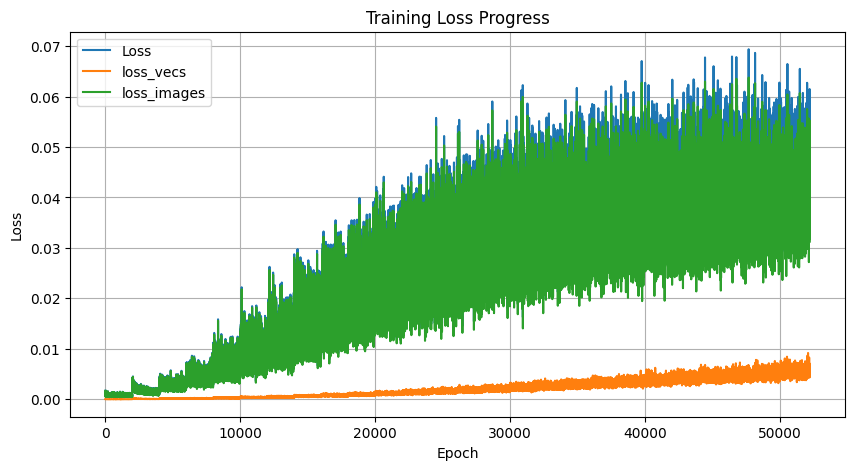

Pretraining epoch 52200/80000, Loss: 0.0375, loss_vec: 0.0062, loss_image: 0.0312, Shift Range: ±27 pixels


KeyboardInterrupt: 

In [12]:
# NotdecoderHight
from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt

# 3D ガウシアンフィルタを適用する関数
def gaussian_smooth_3d(tensor, kernel_size=5, sigma=1.0):
    """ 3D ガウシアンフィルタで displacement field をスムージング """
    # 3D Gaussian Kernel の作成
    from scipy.ndimage import gaussian_filter
    tensor_np = tensor.cpu().numpy()
    smoothed_np = gaussian_filter(tensor_np, sigma=[0, 0, sigma, sigma, sigma])  # チャネル方向にはフィルタ適用しない
    return torch.tensor(smoothed_np, dtype=torch.float32, device=tensor.device)


# エポック数と最小ロスの設定
PRETRAIN_EPOCHS = 80_000
# Recovery setting for the interrupted run.  Set this back to 0 before a new run.
RESUME_PRETRAIN_FROM_EPOCH = 0
# Fine-tuning continues from this global epoch.
epochs = PRETRAIN_EPOCHS

if not 0 <= RESUME_PRETRAIN_FROM_EPOCH < PRETRAIN_EPOCHS:
    raise ValueError('RESUME_PRETRAIN_FROM_EPOCH must be between 0 and 79,999.')
if RESUME_PRETRAIN_FROM_EPOCH:
    resume_checkpoint = torch.load(PRETRAIN_CHECKPOINT_PATH, map_location=device)
    if not isinstance(resume_checkpoint, dict) or 'model_state_dict' not in resume_checkpoint:
        raise RuntimeError(
            'A model-and-optimizer recovery checkpoint is required. '
            'Save the current in-memory state before running this cell.'
        )
    saved_epoch = int(resume_checkpoint.get('global_epoch', -1))
    if saved_epoch != RESUME_PRETRAIN_FROM_EPOCH:
        raise RuntimeError(
            f'Recovery checkpoint is epoch {saved_epoch}, but '
            f'RESUME_PRETRAIN_FROM_EPOCH is {RESUME_PRETRAIN_FROM_EPOCH}.'
        )
    model3D.load_state_dict(resume_checkpoint['model_state_dict'])
    optimizer.load_state_dict(resume_checkpoint['optimizer_state_dict'])
    print(f'Resuming pretraining from global epoch {saved_epoch}.')

best_loss = float('inf')
# The original curriculum increases the shift range after every 2,000 epochs.
shift_range = 1 + RESUME_PRETRAIN_FROM_EPOCH // 2000
print(f'Initial shift range for this run: ±{shift_range} pixels.')

# ロスや他のメトリクスを記録するリスト
losses = []
loss_vecs = []
loss_images = []
loss_hightVecs = []
for epoch in tqdm(
    range(RESUME_PRETRAIN_FROM_EPOCH + 1, PRETRAIN_EPOCHS + 1),
    desc='Pretraining',
):
    # 100エポックごとにshift_rangeを増やす
    if epoch % 2000 == 0 and epoch > 0:
        shift_range += 1
        print(f"Epoch {epoch}: Increasing shift range to ±{shift_range} pixels.")

    # 学習データのバッチを取得
    train_batch, _ = next(train_generator)
    moving_images = torch.tensor(train_batch[0], dtype=torch.float32).to(device)

    # 画像サイズを設定
    B, D, H, W = 2, 8, 16, 16  # バッチサイズと画像の次元

    # displacement_field をボクセルごとにランダムに作成
    displacement_field = (torch.rand((B, 3, D, H, W), dtype=torch.float32) * 2 - 1) * shift_range
    displacement_field = displacement_field.to(device)

    # 3D Gaussian Smoothing を適用
    displacement_field = gaussian_smooth_3d(displacement_field, sigma=2.0)
    displacement_field = torch.nn.functional.interpolate(displacement_field, size=(128,256,256), mode='trilinear', align_corners=False)
    displacement_field128 = torch.nn.functional.interpolate(displacement_field, size=(64,128,128), mode='trilinear', align_corners=False)

    # 位置をずらした画像を生成
    moving_images2 = transformer256(moving_images, displacement_field)

    # Wavelet 変換（前処理）
    moving_w = haar_wavelet_3d(moving_images)  # (B,8,D/2,H/2,W/2)
    moving_images2_w  = haar_wavelet_3d(moving_images2)   # (B,8,D/2,H/2,W/2)
    
    # device に戻す
    moving_w = moving_w.to(device)
    moving_images2_w  = moving_images2_w.to(device)

    # 勾配を初期化
    optimizer.zero_grad()

    # 順伝播
    Vec = model3D(moving_w, moving_images2_w)

    # --- 各 Wavelet 成分を変形 ---
    moving_LLL = transformer(moving_w[:, 0:1], Vec)
    moving_LLH = transformer(moving_w[:, 1:2], Vec)
    moving_LHL = transformer(moving_w[:, 2:3], Vec)
    moving_LHH = transformer(moving_w[:, 3:4], Vec)
    moving_HLL = transformer(moving_w[:, 4:5], Vec)
    moving_HLH = transformer(moving_w[:, 5:6], Vec)
    moving_HHL = transformer(moving_w[:, 6:7], Vec)
    moving_HHH = transformer(moving_w[:, 7:8], Vec)
    
    moving_warped = torch.cat(
        [
            moving_LLL, moving_LLH, moving_LHL, moving_LHH,
            moving_HLL, moving_HLH, moving_HHL, moving_HHH
        ],
        dim=1
    )  # (B,8,D/2,H/2,W/2)
    
    # 逆Wavelet
    transformed_image = inverse_haar_wavelet_3d(moving_warped)
    
    transformed_image = transformed_image.to(device) 

    # 損失を計算
    loss_vec = MSE_Loss(displacement_field128, Vec) * 0.01
    loss_image = MSE_Loss(moving_images2, transformed_image) * 100
    
    loss = loss_vec + loss_image

    # 逆伝播
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        checkpoint = {
            'phase': 'pretraining',
            'global_epoch': epoch,
            'phase_epoch': epoch,
            'model_state_dict': model3D.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
        }

        # 常に最新の再開地点を保存
        torch.save(checkpoint, PRETRAIN_CHECKPOINT_PATH)

        # 1,000 epochごとに世代別checkpointも保存
        if epoch % 1000 == 0:
            epoch_path = (
                PRETRAIN_OUTPUT_DIR
                / f'checkpoint_epoch_{epoch:05d}.pth'
            )
            torch.save(checkpoint, epoch_path)
            print(f'Saved recovery checkpoint: {epoch_path}')
        
    losses.append(loss.cpu().item())
    loss_vecs.append(loss_vec.cpu().item())
    loss_images.append(loss_image.cpu().item())

    # 100エポックごとにグラフを更新
    if epoch % 10 == 0:
        clear_output(wait=True)  # 出力をリフレッシュ
        plt.figure(figsize=(10,5))
        plt.plot(losses, label='Loss')
        plt.plot(loss_vecs, label='loss_vecs')
        plt.plot(loss_images, label='loss_images')
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training Loss Progress")
        plt.legend()
        plt.grid(True)
        plt.show()
    
    # エポックごとのロスの表示
    print(f"Pretraining epoch {epoch}/{PRETRAIN_EPOCHS}, Loss: {loss:.4f}, loss_vec: {loss_vec:.4f}, loss_image: {loss_image:.4f}, Shift Range: ±{shift_range} pixels")


In [12]:
checkpoint = torch.load(
    PRETRAIN_CHECKPOINT_PATH,
    map_location="cpu",
)

print("saved epoch :", checkpoint["global_epoch"])
print("has model   :", "model_state_dict" in checkpoint)
print("has optimizer:", "optimizer_state_dict" in checkpoint)

assert checkpoint["global_epoch"] == 52_200
assert "model_state_dict" in checkpoint
assert "optimizer_state_dict" in checkpoint

saved epoch : 52200
has model   : True
has optimizer: True


In [13]:
# ============================================================
# Pretraining resume用:
# artificial DVF smoothing function
# ============================================================

import numpy as np
import torch
from scipy.ndimage import gaussian_filter

def gaussian_smooth_3d(
    tensor,
    kernel_size=5,  # 互換性のため残す。計算には未使用。
    sigma=1.0,
):
    """
    tensor:
        (B, 3, D, H, W)

    人工DVF生成時だけに使うガウシアン平滑化。
    勾配を通す用途ではないため detach() してCPUで処理する。
    """
    original_device = tensor.device
    original_dtype = tensor.dtype

    tensor_np = (
        tensor.detach()
        .cpu()
        .numpy()
    )

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    ).astype(np.float32, copy=False)

    return torch.from_numpy(
        np.ascontiguousarray(smoothed_np)
    ).to(
        device=original_device,
        dtype=original_dtype,
    )

print("gaussian_smooth_3d: ready")

gaussian_smooth_3d: ready


In [14]:
# ============================================================
# Pretraining resume cell
# checkpoint epoch 52,200 -> epoch 80,000
#
# 前提:
#   x_train
#   vxm_data_generator
#   haar_wavelet_3d
#   inverse_haar_wavelet_3d
#   gaussian_smooth_3d
#   transformer / transformer256
#   MSE_Loss
# が上のセルで定義済みであること
# ============================================================

from pathlib import Path
import time
import torch
import torch.optim as optim
from tqdm.auto import tqdm

# ------------------------------------------------------------
# A. Path / resume setting
# ------------------------------------------------------------

PROJECT_DIR = Path.cwd()

RUN_NAME = "pretraining_80k_rerun"

PRETRAIN_OUTPUT_DIR = (
    PROJECT_DIR
    / "training_outputs_256_128"
    / RUN_NAME
)

PRETRAIN_CHECKPOINT_PATH = (
    PRETRAIN_OUTPUT_DIR
    / "pretrained_model_latest.pth"
)

PRETRAIN_EPOCHS = 80_000
RESUME_PRETRAIN_FROM_EPOCH = 52_200

BATCH_SIZE = 2
LEARNING_RATE = 1e-4
CHECKPOINT_EVERY = 100
EPOCH_CHECKPOINT_EVERY = 1_000
PRINT_EVERY = 100

assert PRETRAIN_CHECKPOINT_PATH.is_file(), (
    f"checkpointが見つかりません:\n{PRETRAIN_CHECKPOINT_PATH}"
)

assert "x_train" in globals(), (
    "x_train がありません。先にTrainData読込セルを実行してください。"
)

assert "haar_wavelet_3d" in globals()
assert "inverse_haar_wavelet_3d" in globals()
assert "gaussian_smooth_3d" in globals()
assert "transformer" in globals()
assert "transformer256" in globals()
assert "MSE_Loss" in globals()

print("Resume checkpoint:", PRETRAIN_CHECKPOINT_PATH)
print("Resume from      :", RESUME_PRETRAIN_FROM_EPOCH)
print("Resume to        :", PRETRAIN_EPOCHS)

# ------------------------------------------------------------
# B. checkpoint確認
# ------------------------------------------------------------

checkpoint = torch.load(
    PRETRAIN_CHECKPOINT_PATH,
    map_location=device,
)

saved_epoch = int(checkpoint.get("global_epoch", -1))

print("\n=== Checkpoint ===")
print("saved epoch :", saved_epoch)
print("has model   :", "model_state_dict" in checkpoint)
print("has optimizer:", "optimizer_state_dict" in checkpoint)

assert saved_epoch == RESUME_PRETRAIN_FROM_EPOCH, (
    f"設定epoch={RESUME_PRETRAIN_FROM_EPOCH} と "
    f"保存epoch={saved_epoch} が一致しません。"
)

assert "model_state_dict" in checkpoint
assert "optimizer_state_dict" in checkpoint

# ------------------------------------------------------------
# C. モデルとoptimizerを再構築して状態を復元
# ------------------------------------------------------------

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0,
).to(device)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=LEARNING_RATE,
)

model3D.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# optimizer内のtensorもGPUへ戻す
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

model3D.train()

print("\nModel / optimizer restored.")

# ------------------------------------------------------------
# D. 再開用generator
# ------------------------------------------------------------

train_generator = vxm_data_generator(
    x_train,
    batch_size=BATCH_SIZE,
)

# 元コードと同じカリキュラム:
# 2,000 epochごとにshiftを1増やす
shift_range = 1 + RESUME_PRETRAIN_FROM_EPOCH // 2000

print(
    f"Initial shift range: ±{shift_range} pixels\n"
    f"Next epoch: {RESUME_PRETRAIN_FROM_EPOCH + 1}"
)

# 再開後の履歴。停止前の可視化履歴は含まれない。
losses = []
loss_vecs = []
loss_images = []

resume_start_time = time.perf_counter()

# ------------------------------------------------------------
# E. Resume training
# ------------------------------------------------------------

for epoch in tqdm(
    range(
        RESUME_PRETRAIN_FROM_EPOCH + 1,
        PRETRAIN_EPOCHS + 1,
    ),
    desc="Resumed pretraining",
):
    # 元学習と同じshift curriculum
    if epoch % 2000 == 0:
        shift_range += 1
        print(
            f"\nEpoch {epoch}: "
            f"Increasing shift range to ±{shift_range} pixels."
        )

    # Moving CTを抽出
    train_batch, _ = next(train_generator)

    moving_images = torch.tensor(
        train_batch[0],
        dtype=torch.float32,
        device=device,
    )

    # --------------------------------------------------------
    # 人工的な直接DVF教師を作る
    # --------------------------------------------------------

    coarse_d, coarse_h, coarse_w = 8, 16, 16

    displacement_field = (
        torch.rand(
            (
                BATCH_SIZE,
                3,
                coarse_d,
                coarse_h,
                coarse_w,
            ),
            dtype=torch.float32,
            device=device,
        ) * 2.0 - 1.0
    ) * float(shift_range)

    displacement_field = gaussian_smooth_3d(
        displacement_field,
        sigma=2.0,
    )

    displacement_field = F.interpolate(
        displacement_field,
        size=(128, 256, 256),
        mode="trilinear",
        align_corners=False,
    )

    displacement_field128 = F.interpolate(
        displacement_field,
        size=(64, 128, 128),
        mode="trilinear",
        align_corners=False,
    )

    # 人工Fixed画像
    moving_images2 = transformer256(
        moving_images,
        displacement_field,
    )

    # --------------------------------------------------------
    # Haar入力
    # --------------------------------------------------------

    moving_w = haar_wavelet_3d(moving_images)
    fixed_w = haar_wavelet_3d(moving_images2)

    # --------------------------------------------------------
    # 従来の直接DVFモデル経路
    # --------------------------------------------------------

    optimizer.zero_grad(set_to_none=True)

    Vec = model3D(moving_w, fixed_w)

    moving_LLL = transformer(moving_w[:, 0:1], Vec)
    moving_LLH = transformer(moving_w[:, 1:2], Vec)
    moving_LHL = transformer(moving_w[:, 2:3], Vec)
    moving_LHH = transformer(moving_w[:, 3:4], Vec)
    moving_HLL = transformer(moving_w[:, 4:5], Vec)
    moving_HLH = transformer(moving_w[:, 5:6], Vec)
    moving_HHL = transformer(moving_w[:, 6:7], Vec)
    moving_HHH = transformer(moving_w[:, 7:8], Vec)

    moving_warped = torch.cat(
        [
            moving_LLL,
            moving_LLH,
            moving_LHL,
            moving_LHH,
            moving_HLL,
            moving_HLH,
            moving_HHL,
            moving_HHH,
        ],
        dim=1,
    )

    transformed_image = inverse_haar_wavelet_3d(
        moving_warped
    )

    # 元学習と同じ損失
    loss_vec = (
        MSE_Loss(displacement_field128, Vec) * 0.01
    )

    loss_image = (
        MSE_Loss(moving_images2, transformed_image) * 100.0
    )

    loss = loss_vec + loss_image

    loss.backward()
    optimizer.step()

    # --------------------------------------------------------
    # F. Log
    # --------------------------------------------------------

    losses.append(loss.detach().cpu().item())
    loss_vecs.append(loss_vec.detach().cpu().item())
    loss_images.append(loss_image.detach().cpu().item())

    if epoch % PRINT_EVERY == 0 or epoch == PRETRAIN_EPOCHS:
        elapsed = time.perf_counter() - resume_start_time

        print(
            f"Epoch {epoch}/{PRETRAIN_EPOCHS}, "
            f"Loss: {loss.item():.4f}, "
            f"loss_vec: {loss_vec.item():.4f}, "
            f"loss_image: {loss_image.item():.4f}, "
            f"Shift Range: ±{shift_range} pixels, "
            f"resumed elapsed: {elapsed / 60:.1f} min"
        )

    # --------------------------------------------------------
    # G. checkpoint保存
    # --------------------------------------------------------

    if epoch % CHECKPOINT_EVERY == 0:
        training_state = {
            "phase": "pretraining",
            "global_epoch": epoch,
            "phase_epoch": epoch,
            "model_state_dict": model3D.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
        }

        # 常に最新の再開地点
        torch.save(
            training_state,
            PRETRAIN_CHECKPOINT_PATH,
        )

        # 1000 epochごとの世代別保存
        if epoch % EPOCH_CHECKPOINT_EVERY == 0:
            epoch_path = (
                PRETRAIN_OUTPUT_DIR
                / f"checkpoint_epoch_{epoch:05d}.pth"
            )

            torch.save(training_state, epoch_path)

            print("Saved recovery checkpoint:", epoch_path)

# ------------------------------------------------------------
# H. Final save
# ------------------------------------------------------------

final_state = {
    "phase": "pretraining_complete",
    "global_epoch": PRETRAIN_EPOCHS,
    "phase_epoch": PRETRAIN_EPOCHS,
    "model_state_dict": model3D.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
}

torch.save(
    final_state,
    PRETRAIN_CHECKPOINT_PATH,
)

final_path = (
    PRETRAIN_OUTPUT_DIR
    / "pretrained_model_final_80000.pth"
)

torch.save(
    final_state,
    final_path,
)

print("\n=== Resume training completed ===")
print("Latest checkpoint:", PRETRAIN_CHECKPOINT_PATH)
print("Final model      :", final_path)

Resume checkpoint: d:\Saito\yamatoCode\training_outputs_256_128\pretraining_80k_rerun\pretrained_model_latest.pth
Resume from      : 52200
Resume to        : 80000

=== Checkpoint ===
saved epoch : 52200
has model   : True
has optimizer: True
[64, 128, 128]

Model / optimizer restored.
Initial shift range: ±27 pixels
Next epoch: 52201


Resumed pretraining:   0%|          | 0/27800 [00:00<?, ?it/s]

C:\Users\user\AppData\Local\Temp\ipykernel_6616\1714291924.py:179: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  moving_images = torch.tensor(


Epoch 52300/80000, Loss: 0.0442, loss_vec: 0.0051, loss_image: 0.0392, Shift Range: ±27 pixels, resumed elapsed: 5.0 min
Epoch 52400/80000, Loss: 0.0506, loss_vec: 0.0074, loss_image: 0.0432, Shift Range: ±27 pixels, resumed elapsed: 7.1 min
Epoch 52500/80000, Loss: 0.0344, loss_vec: 0.0051, loss_image: 0.0294, Shift Range: ±27 pixels, resumed elapsed: 9.2 min
Epoch 52600/80000, Loss: 0.0424, loss_vec: 0.0040, loss_image: 0.0384, Shift Range: ±27 pixels, resumed elapsed: 11.4 min
Epoch 52700/80000, Loss: 0.0442, loss_vec: 0.0048, loss_image: 0.0394, Shift Range: ±27 pixels, resumed elapsed: 13.5 min
Epoch 52800/80000, Loss: 0.0368, loss_vec: 0.0057, loss_image: 0.0310, Shift Range: ±27 pixels, resumed elapsed: 15.7 min
Epoch 52900/80000, Loss: 0.0367, loss_vec: 0.0061, loss_image: 0.0306, Shift Range: ±27 pixels, resumed elapsed: 17.8 min
Epoch 53000/80000, Loss: 0.0501, loss_vec: 0.0078, loss_image: 0.0423, Shift Range: ±27 pixels, resumed elapsed: 20.0 min
Saved recovery checkpoint: 

In [ ]:
# === Fine-tuning visualization and evaluation (added by Codex) ===
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

finetune_eval_every = 100
finetune_eval_dir = FINETUNE_EVALUATION_DIR
finetune_eval_dir.mkdir(parents=True, exist_ok=True)

def compute_registration_metrics(source, target):
    diff = source - target
    mse = torch.mean(diff ** 2).item()
    source_centered = source - torch.mean(source)
    target_centered = target - torch.mean(target)
    ncc = (
        torch.sum(source_centered * target_centered)
        / torch.sqrt(
            torch.sum(source_centered ** 2)
            * torch.sum(target_centered ** 2)
            + 1e-8
        )
    ).item()
    return {
        'MAE': torch.mean(torch.abs(diff)).item(),
        'MSE': mse,
        'RMSE': float(np.sqrt(mse)),
        'NCC': ncc,
    }

def save_finetune_evaluation(moving, fixed, warped, losses, epoch):
    before = compute_registration_metrics(moving, fixed)
    after = compute_registration_metrics(warped, fixed)
    slice_index = moving.shape[2] // 2

    print(f'\n--- Epoch {epoch} evaluation ---')
    # 変更後
    for label, key in [
        ('MSE', 'mse'),
        ('MAE', 'mae'),
        ('RMSE', 'rmse'),
        ('NCC', 'ncc'),
    ]:
        print(f'{label}: {before[key]:.6f} -> {after[key]:.6f}')

    moving_slice = moving[0, 0, slice_index].detach().cpu().numpy()
    fixed_slice = fixed[0, 0, slice_index].detach().cpu().numpy()
    warped_slice = warped[0, 0, slice_index].detach().cpu().numpy()
    before_diff = np.abs(moving_slice - fixed_slice)
    after_diff = np.abs(warped_slice - fixed_slice)
    shared_vmax = max(float(before_diff.max()), float(after_diff.max()), 1e-8)

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for axis, image, title in zip(
        axes[0],
        [moving_slice, fixed_slice, warped_slice],
        ['Moving', 'Fixed', 'Warped']
    ):
        axis.imshow(image, cmap='gray')
        axis.set_title(title)
        axis.axis('off')

    axes[1, 0].imshow(before_diff, cmap='inferno', vmin=0, vmax=shared_vmax)
    axes[1, 0].set_title('Abs Diff: Moving vs Fixed')
    axes[1, 0].axis('off')
    axes[1, 1].imshow(after_diff, cmap='inferno', vmin=0, vmax=shared_vmax)
    axes[1, 1].set_title('Abs Diff: Warped vs Fixed')
    axes[1, 1].axis('off')
    axes[1, 2].axis('off')
    axes[1, 2].text(
        0.0, 1.0,
        f"MSE: {before['MSE']:.6f} -> {after['MSE']:.6f}\n"
        f"MAE: {before['MAE']:.6f} -> {after['MAE']:.6f}\n"
        f"RMSE: {before['RMSE']:.6f} -> {after['RMSE']:.6f}\n"
        f"NCC: {before['NCC']:.6f} -> {after['NCC']:.6f}",
        va='top', fontsize=12
    )
    fig.suptitle(f'Fine-tuning evaluation: epoch {epoch}')
    fig.tight_layout()
    fig.savefig(
        finetune_eval_dir / f'epoch_{epoch:06d}_registration.png',
        dpi=200, bbox_inches='tight'
    )
    plt.show()
    plt.close(fig)

    loss_fig, loss_axis = plt.subplots(figsize=(10, 5))
    loss_axis.plot(losses, label='Fine-tuning loss')
    loss_axis.set_xlabel('Epoch')
    loss_axis.set_ylabel('Loss')
    loss_axis.set_title('Fine-tuning Loss Progress')
    loss_axis.grid(True)
    loss_axis.legend()
    loss_fig.tight_layout()
    loss_fig.savefig(
        finetune_eval_dir / 'loss_history.png', dpi=200, bbox_inches='tight'
    )
    plt.show()
    plt.close(loss_fig)


In [14]:
def save_finetune_evaluation(moving, fixed, warped, losses, epoch):
    before = compute_registration_metrics(moving, fixed)
    after = compute_registration_metrics(warped, fixed)

    slice_index = moving.shape[2] // 2

    print(f"\n--- Epoch {epoch} evaluation ---")
    for label, key in [
        ("MSE", "mse"),
        ("MAE", "mae"),
        ("RMSE", "rmse"),
        ("NCC", "ncc"),
    ]:
        print(f"{label}: {before[key]:.6f} -> {after[key]:.6f}")

    moving_slice = moving[0, 0, slice_index].detach().cpu().numpy()
    fixed_slice = fixed[0, 0, slice_index].detach().cpu().numpy()
    warped_slice = warped[0, 0, slice_index].detach().cpu().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(moving_slice, cmap="gray")
    axes[0].set_title("Moving")
    axes[0].axis("off")

    axes[1].imshow(fixed_slice, cmap="gray")
    axes[1].set_title("Fixed")
    axes[1].axis("off")

    axes[2].imshow(warped_slice, cmap="gray")
    axes[2].set_title("Warped")
    axes[2].axis("off")

    plt.suptitle(f"Fine-tuning evaluation | epoch={epoch}")
    plt.tight_layout()
    plt.show()

In [23]:
@torch.no_grad()
def compute_registration_metrics(source, target):
    # source側に target のdevice / dtypeを合わせる
    source = source.detach()
    target = target.detach().to(
        device=source.device,
        dtype=source.dtype,
    )

    diff = source - target
    mse = torch.mean(diff ** 2).item()
    mae = torch.mean(torch.abs(diff)).item()

    source_centered = source - torch.mean(source)
    target_centered = target - torch.mean(target)

    ncc = (
        torch.sum(source_centered * target_centered)
        / (
            torch.sqrt(torch.sum(source_centered ** 2))
            * torch.sqrt(torch.sum(target_centered ** 2))
            + 1e-8
        )
    ).item()

    return {
        'mse': mse,
        'mae': mae,
        'rmse': mse ** 0.5,
        'ncc': ncc,
    }

Reusing in-memory model and optimizer state from global epoch 80,000.
Fine-tuning resumes at global epoch 80001 and ends at 110000.


Fine-tuning:   0%|          | 0/30000 [00:00<?, ?it/s]

Global epoch 80001/110000 (fine-tuning 1/30000), Loss: 0.0037
Global epoch 80002/110000 (fine-tuning 2/30000), Loss: 0.0043
Global epoch 80003/110000 (fine-tuning 3/30000), Loss: 0.0038
Global epoch 80004/110000 (fine-tuning 4/30000), Loss: 0.0052
Global epoch 80005/110000 (fine-tuning 5/30000), Loss: 0.0035
Global epoch 80006/110000 (fine-tuning 6/30000), Loss: 0.0039
Global epoch 80007/110000 (fine-tuning 7/30000), Loss: 0.0053
Global epoch 80008/110000 (fine-tuning 8/30000), Loss: 0.0038
Global epoch 80009/110000 (fine-tuning 9/30000), Loss: 0.0044
Global epoch 80010/110000 (fine-tuning 10/30000), Loss: 0.0026
Global epoch 80011/110000 (fine-tuning 11/30000), Loss: 0.0057
Global epoch 80012/110000 (fine-tuning 12/30000), Loss: 0.0041
Global epoch 80013/110000 (fine-tuning 13/30000), Loss: 0.0039
Global epoch 80014/110000 (fine-tuning 14/30000), Loss: 0.0015
Global epoch 80015/110000 (fine-tuning 15/30000), Loss: 0.0036
Global epoch 80016/110000 (fine-tuning 16/30000), Loss: 0.0055
G

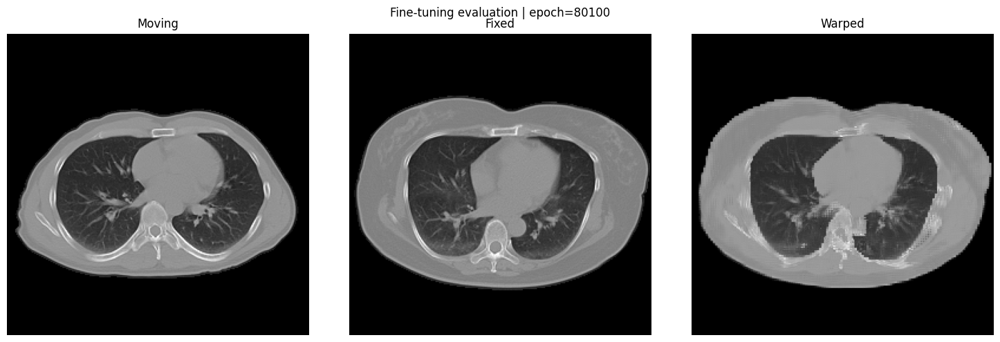

Global epoch 80101/110000 (fine-tuning 101/30000), Loss: 0.0066
Global epoch 80102/110000 (fine-tuning 102/30000), Loss: 0.0026
Global epoch 80103/110000 (fine-tuning 103/30000), Loss: 0.0031
Global epoch 80104/110000 (fine-tuning 104/30000), Loss: 0.0039
Global epoch 80105/110000 (fine-tuning 105/30000), Loss: 0.0040
Global epoch 80106/110000 (fine-tuning 106/30000), Loss: 0.0038
Global epoch 80107/110000 (fine-tuning 107/30000), Loss: 0.0043
Global epoch 80108/110000 (fine-tuning 108/30000), Loss: 0.0038
Global epoch 80109/110000 (fine-tuning 109/30000), Loss: 0.0030
Global epoch 80110/110000 (fine-tuning 110/30000), Loss: 0.0048
Global epoch 80111/110000 (fine-tuning 111/30000), Loss: 0.0038
Global epoch 80112/110000 (fine-tuning 112/30000), Loss: 0.0039
Global epoch 80113/110000 (fine-tuning 113/30000), Loss: 0.0032
Global epoch 80114/110000 (fine-tuning 114/30000), Loss: 0.0043
Global epoch 80115/110000 (fine-tuning 115/30000), Loss: 0.0029
Global epoch 80116/110000 (fine-tuning 1

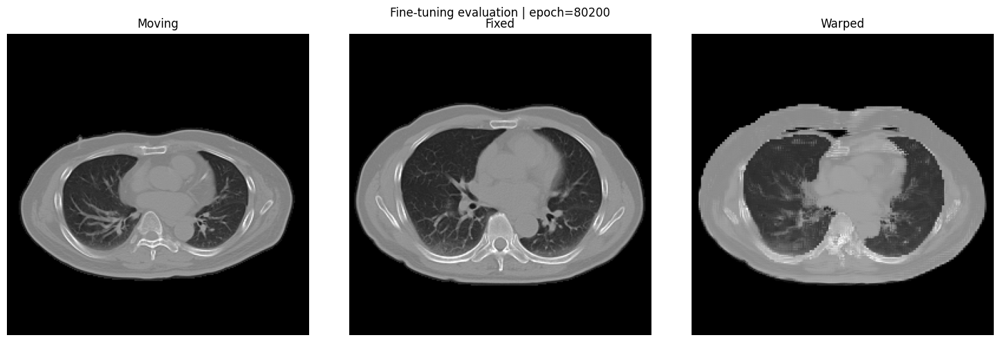

Global epoch 80201/110000 (fine-tuning 201/30000), Loss: 0.0039
Global epoch 80202/110000 (fine-tuning 202/30000), Loss: 0.0035
Global epoch 80203/110000 (fine-tuning 203/30000), Loss: 0.0036
Global epoch 80204/110000 (fine-tuning 204/30000), Loss: 0.0047
Global epoch 80205/110000 (fine-tuning 205/30000), Loss: 0.0037
Global epoch 80206/110000 (fine-tuning 206/30000), Loss: 0.0034
Global epoch 80207/110000 (fine-tuning 207/30000), Loss: 0.0027
Global epoch 80208/110000 (fine-tuning 208/30000), Loss: 0.0031
Global epoch 80209/110000 (fine-tuning 209/30000), Loss: 0.0035
Global epoch 80210/110000 (fine-tuning 210/30000), Loss: 0.0031
Global epoch 80211/110000 (fine-tuning 211/30000), Loss: 0.0035
Global epoch 80212/110000 (fine-tuning 212/30000), Loss: 0.0037
Global epoch 80213/110000 (fine-tuning 213/30000), Loss: 0.0031
Global epoch 80214/110000 (fine-tuning 214/30000), Loss: 0.0034
Global epoch 80215/110000 (fine-tuning 215/30000), Loss: 0.0055
Global epoch 80216/110000 (fine-tuning 2

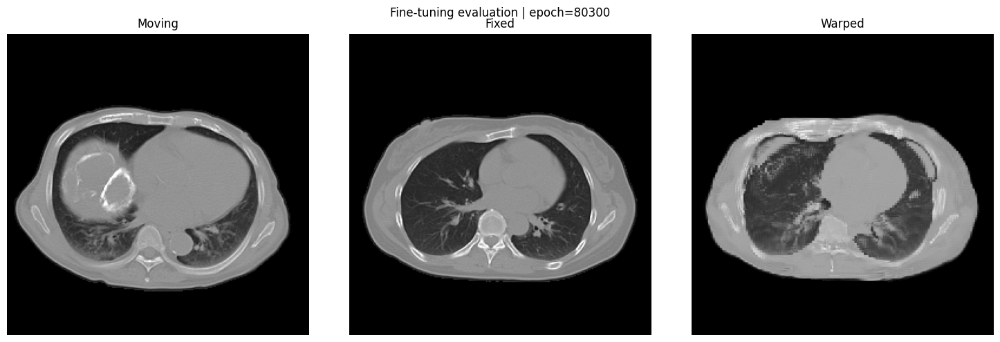

Global epoch 80301/110000 (fine-tuning 301/30000), Loss: 0.0042
Global epoch 80302/110000 (fine-tuning 302/30000), Loss: 0.0031
Global epoch 80303/110000 (fine-tuning 303/30000), Loss: 0.0030
Global epoch 80304/110000 (fine-tuning 304/30000), Loss: 0.0033
Global epoch 80305/110000 (fine-tuning 305/30000), Loss: 0.0025
Global epoch 80306/110000 (fine-tuning 306/30000), Loss: 0.0047
Global epoch 80307/110000 (fine-tuning 307/30000), Loss: 0.0034
Global epoch 80308/110000 (fine-tuning 308/30000), Loss: 0.0045
Global epoch 80309/110000 (fine-tuning 309/30000), Loss: 0.0056
Global epoch 80310/110000 (fine-tuning 310/30000), Loss: 0.0032
Global epoch 80311/110000 (fine-tuning 311/30000), Loss: 0.0038
Global epoch 80312/110000 (fine-tuning 312/30000), Loss: 0.0022
Global epoch 80313/110000 (fine-tuning 313/30000), Loss: 0.0040
Global epoch 80314/110000 (fine-tuning 314/30000), Loss: 0.0042
Global epoch 80315/110000 (fine-tuning 315/30000), Loss: 0.0042
Global epoch 80316/110000 (fine-tuning 3

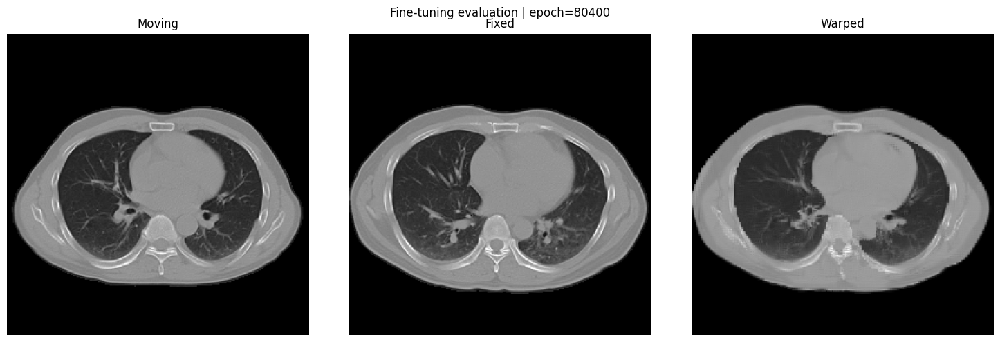

Global epoch 80401/110000 (fine-tuning 401/30000), Loss: 0.0044
Global epoch 80402/110000 (fine-tuning 402/30000), Loss: 0.0041
Global epoch 80403/110000 (fine-tuning 403/30000), Loss: 0.0033
Global epoch 80404/110000 (fine-tuning 404/30000), Loss: 0.0037
Global epoch 80405/110000 (fine-tuning 405/30000), Loss: 0.0030
Global epoch 80406/110000 (fine-tuning 406/30000), Loss: 0.0039
Global epoch 80407/110000 (fine-tuning 407/30000), Loss: 0.0037
Global epoch 80408/110000 (fine-tuning 408/30000), Loss: 0.0032
Global epoch 80409/110000 (fine-tuning 409/30000), Loss: 0.0045
Global epoch 80410/110000 (fine-tuning 410/30000), Loss: 0.0029
Global epoch 80411/110000 (fine-tuning 411/30000), Loss: 0.0030
Global epoch 80412/110000 (fine-tuning 412/30000), Loss: 0.0052
Global epoch 80413/110000 (fine-tuning 413/30000), Loss: 0.0036
Global epoch 80414/110000 (fine-tuning 414/30000), Loss: 0.0039
Global epoch 80415/110000 (fine-tuning 415/30000), Loss: 0.0030
Global epoch 80416/110000 (fine-tuning 4

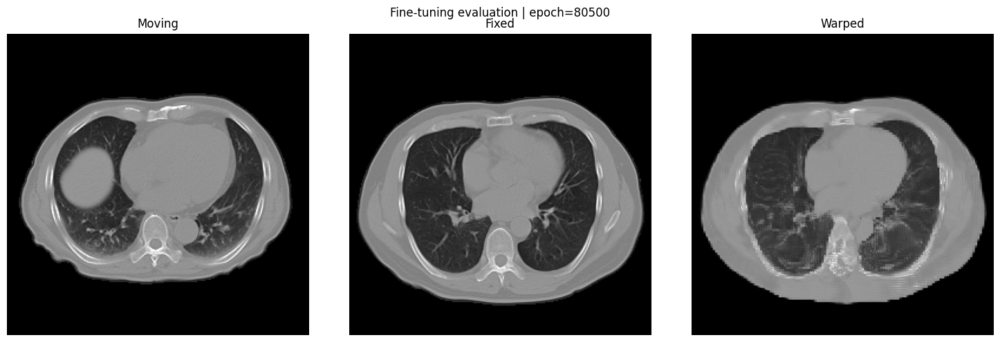

Global epoch 80501/110000 (fine-tuning 501/30000), Loss: 0.0029
Global epoch 80502/110000 (fine-tuning 502/30000), Loss: 0.0039
Global epoch 80503/110000 (fine-tuning 503/30000), Loss: 0.0042
Global epoch 80504/110000 (fine-tuning 504/30000), Loss: 0.0031
Global epoch 80505/110000 (fine-tuning 505/30000), Loss: 0.0032
Global epoch 80506/110000 (fine-tuning 506/30000), Loss: 0.0038
Global epoch 80507/110000 (fine-tuning 507/30000), Loss: 0.0034
Global epoch 80508/110000 (fine-tuning 508/30000), Loss: 0.0034
Global epoch 80509/110000 (fine-tuning 509/30000), Loss: 0.0023
Global epoch 80510/110000 (fine-tuning 510/30000), Loss: 0.0025
Global epoch 80511/110000 (fine-tuning 511/30000), Loss: 0.0059
Global epoch 80512/110000 (fine-tuning 512/30000), Loss: 0.0048
Global epoch 80513/110000 (fine-tuning 513/30000), Loss: 0.0034
Global epoch 80514/110000 (fine-tuning 514/30000), Loss: 0.0028
Global epoch 80515/110000 (fine-tuning 515/30000), Loss: 0.0030
Global epoch 80516/110000 (fine-tuning 5

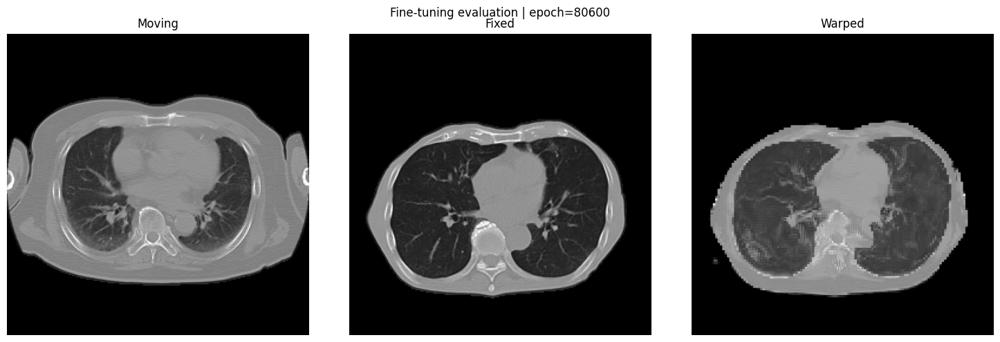

Global epoch 80601/110000 (fine-tuning 601/30000), Loss: 0.0027
Global epoch 80602/110000 (fine-tuning 602/30000), Loss: 0.0034
Global epoch 80603/110000 (fine-tuning 603/30000), Loss: 0.0032
Global epoch 80604/110000 (fine-tuning 604/30000), Loss: 0.0031
Global epoch 80605/110000 (fine-tuning 605/30000), Loss: 0.0031
Global epoch 80606/110000 (fine-tuning 606/30000), Loss: 0.0027
Global epoch 80607/110000 (fine-tuning 607/30000), Loss: 0.0029
Global epoch 80608/110000 (fine-tuning 608/30000), Loss: 0.0036
Global epoch 80609/110000 (fine-tuning 609/30000), Loss: 0.0028
Global epoch 80610/110000 (fine-tuning 610/30000), Loss: 0.0025
Global epoch 80611/110000 (fine-tuning 611/30000), Loss: 0.0033
Global epoch 80612/110000 (fine-tuning 612/30000), Loss: 0.0039
Global epoch 80613/110000 (fine-tuning 613/30000), Loss: 0.0030
Global epoch 80614/110000 (fine-tuning 614/30000), Loss: 0.0037
Global epoch 80615/110000 (fine-tuning 615/30000), Loss: 0.0031
Global epoch 80616/110000 (fine-tuning 6

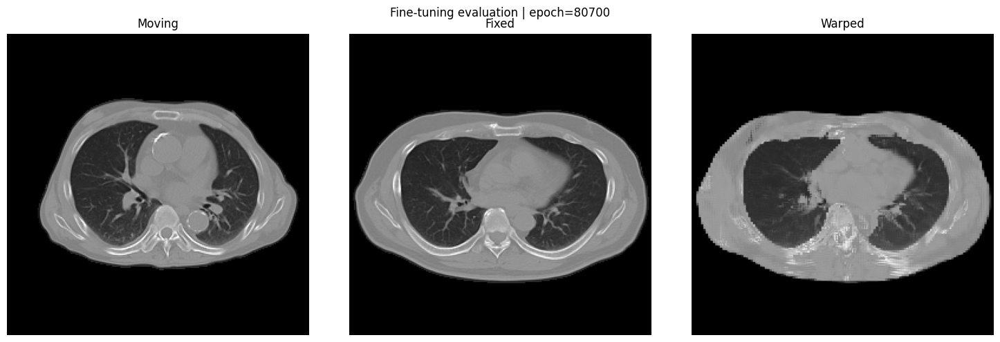

Global epoch 80701/110000 (fine-tuning 701/30000), Loss: 0.0032
Global epoch 80702/110000 (fine-tuning 702/30000), Loss: 0.0034
Global epoch 80703/110000 (fine-tuning 703/30000), Loss: 0.0030
Global epoch 80704/110000 (fine-tuning 704/30000), Loss: 0.0033
Global epoch 80705/110000 (fine-tuning 705/30000), Loss: 0.0036
Global epoch 80706/110000 (fine-tuning 706/30000), Loss: 0.0029
Global epoch 80707/110000 (fine-tuning 707/30000), Loss: 0.0029
Global epoch 80708/110000 (fine-tuning 708/30000), Loss: 0.0030
Global epoch 80709/110000 (fine-tuning 709/30000), Loss: 0.0033
Global epoch 80710/110000 (fine-tuning 710/30000), Loss: 0.0032
Global epoch 80711/110000 (fine-tuning 711/30000), Loss: 0.0021
Global epoch 80712/110000 (fine-tuning 712/30000), Loss: 0.0022
Global epoch 80713/110000 (fine-tuning 713/30000), Loss: 0.0032
Global epoch 80714/110000 (fine-tuning 714/30000), Loss: 0.0027
Global epoch 80715/110000 (fine-tuning 715/30000), Loss: 0.0030
Global epoch 80716/110000 (fine-tuning 7

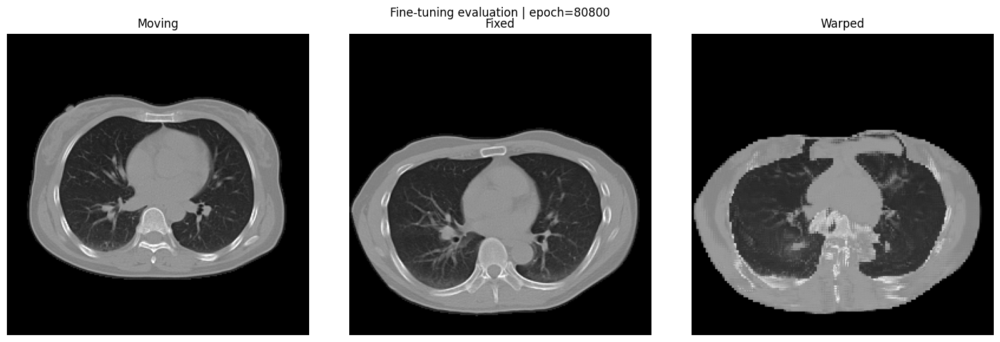

Global epoch 80801/110000 (fine-tuning 801/30000), Loss: 0.0026
Global epoch 80802/110000 (fine-tuning 802/30000), Loss: 0.0035
Global epoch 80803/110000 (fine-tuning 803/30000), Loss: 0.0036
Global epoch 80804/110000 (fine-tuning 804/30000), Loss: 0.0024
Global epoch 80805/110000 (fine-tuning 805/30000), Loss: 0.0030
Global epoch 80806/110000 (fine-tuning 806/30000), Loss: 0.0024
Global epoch 80807/110000 (fine-tuning 807/30000), Loss: 0.0035
Global epoch 80808/110000 (fine-tuning 808/30000), Loss: 0.0023
Global epoch 80809/110000 (fine-tuning 809/30000), Loss: 0.0032
Global epoch 80810/110000 (fine-tuning 810/30000), Loss: 0.0031
Global epoch 80811/110000 (fine-tuning 811/30000), Loss: 0.0029
Global epoch 80812/110000 (fine-tuning 812/30000), Loss: 0.0027
Global epoch 80813/110000 (fine-tuning 813/30000), Loss: 0.0029
Global epoch 80814/110000 (fine-tuning 814/30000), Loss: 0.0028
Global epoch 80815/110000 (fine-tuning 815/30000), Loss: 0.0027
Global epoch 80816/110000 (fine-tuning 8

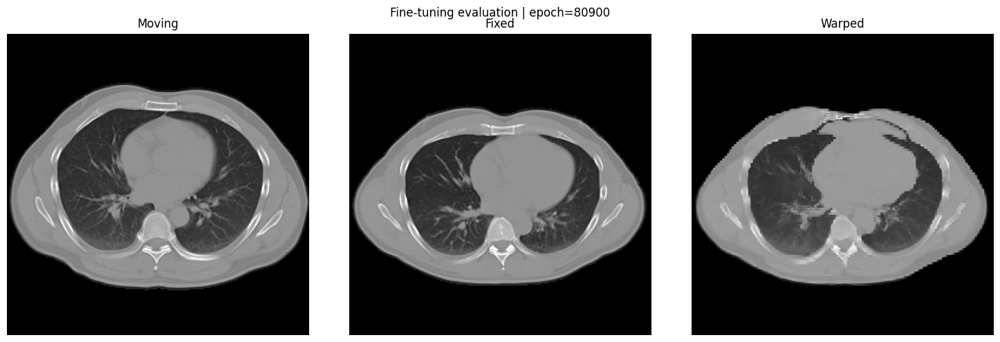

Global epoch 80901/110000 (fine-tuning 901/30000), Loss: 0.0034
Global epoch 80902/110000 (fine-tuning 902/30000), Loss: 0.0030
Global epoch 80903/110000 (fine-tuning 903/30000), Loss: 0.0025
Global epoch 80904/110000 (fine-tuning 904/30000), Loss: 0.0032
Global epoch 80905/110000 (fine-tuning 905/30000), Loss: 0.0028
Global epoch 80906/110000 (fine-tuning 906/30000), Loss: 0.0027
Global epoch 80907/110000 (fine-tuning 907/30000), Loss: 0.0028
Global epoch 80908/110000 (fine-tuning 908/30000), Loss: 0.0024
Global epoch 80909/110000 (fine-tuning 909/30000), Loss: 0.0031
Global epoch 80910/110000 (fine-tuning 910/30000), Loss: 0.0035
Global epoch 80911/110000 (fine-tuning 911/30000), Loss: 0.0032
Global epoch 80912/110000 (fine-tuning 912/30000), Loss: 0.0029
Global epoch 80913/110000 (fine-tuning 913/30000), Loss: 0.0035
Global epoch 80914/110000 (fine-tuning 914/30000), Loss: 0.0027
Global epoch 80915/110000 (fine-tuning 915/30000), Loss: 0.0025
Global epoch 80916/110000 (fine-tuning 9

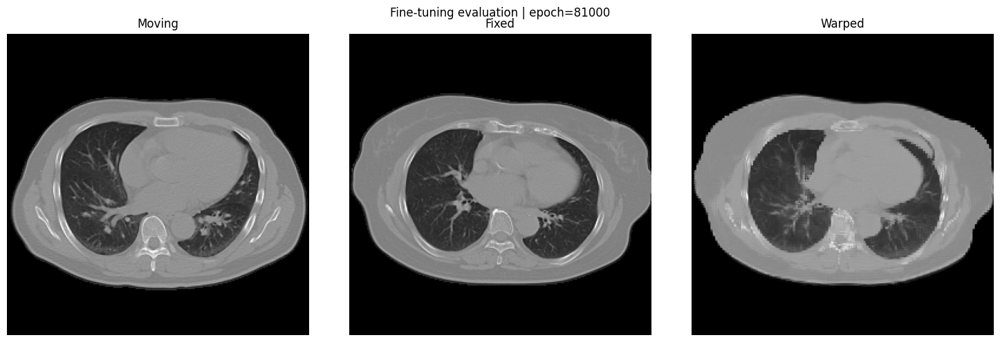

Global epoch 81001/110000 (fine-tuning 1001/30000), Loss: 0.0037
Global epoch 81002/110000 (fine-tuning 1002/30000), Loss: 0.0029
Global epoch 81003/110000 (fine-tuning 1003/30000), Loss: 0.0045
Global epoch 81004/110000 (fine-tuning 1004/30000), Loss: 0.0028
Global epoch 81005/110000 (fine-tuning 1005/30000), Loss: 0.0030
Global epoch 81006/110000 (fine-tuning 1006/30000), Loss: 0.0026
Global epoch 81007/110000 (fine-tuning 1007/30000), Loss: 0.0024
Global epoch 81008/110000 (fine-tuning 1008/30000), Loss: 0.0025
Global epoch 81009/110000 (fine-tuning 1009/30000), Loss: 0.0035
Global epoch 81010/110000 (fine-tuning 1010/30000), Loss: 0.0039
Global epoch 81011/110000 (fine-tuning 1011/30000), Loss: 0.0028
Global epoch 81012/110000 (fine-tuning 1012/30000), Loss: 0.0031
Global epoch 81013/110000 (fine-tuning 1013/30000), Loss: 0.0033
Global epoch 81014/110000 (fine-tuning 1014/30000), Loss: 0.0036
Global epoch 81015/110000 (fine-tuning 1015/30000), Loss: 0.0033
Global epoch 81016/110000

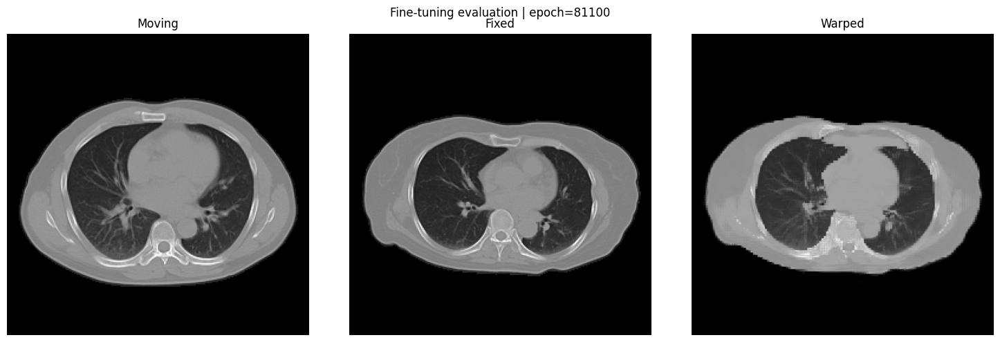

Global epoch 81101/110000 (fine-tuning 1101/30000), Loss: 0.0029
Global epoch 81102/110000 (fine-tuning 1102/30000), Loss: 0.0028
Global epoch 81103/110000 (fine-tuning 1103/30000), Loss: 0.0029
Global epoch 81104/110000 (fine-tuning 1104/30000), Loss: 0.0029
Global epoch 81105/110000 (fine-tuning 1105/30000), Loss: 0.0022
Global epoch 81106/110000 (fine-tuning 1106/30000), Loss: 0.0031
Global epoch 81107/110000 (fine-tuning 1107/30000), Loss: 0.0038
Global epoch 81108/110000 (fine-tuning 1108/30000), Loss: 0.0025
Global epoch 81109/110000 (fine-tuning 1109/30000), Loss: 0.0025
Global epoch 81110/110000 (fine-tuning 1110/30000), Loss: 0.0032
Global epoch 81111/110000 (fine-tuning 1111/30000), Loss: 0.0028
Global epoch 81112/110000 (fine-tuning 1112/30000), Loss: 0.0025
Global epoch 81113/110000 (fine-tuning 1113/30000), Loss: 0.0029
Global epoch 81114/110000 (fine-tuning 1114/30000), Loss: 0.0026
Global epoch 81115/110000 (fine-tuning 1115/30000), Loss: 0.0027
Global epoch 81116/110000

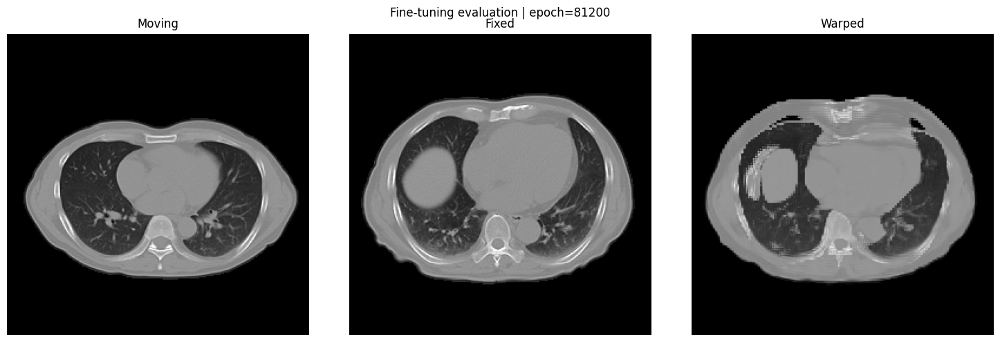

Global epoch 81201/110000 (fine-tuning 1201/30000), Loss: 0.0033
Global epoch 81202/110000 (fine-tuning 1202/30000), Loss: 0.0025
Global epoch 81203/110000 (fine-tuning 1203/30000), Loss: 0.0032
Global epoch 81204/110000 (fine-tuning 1204/30000), Loss: 0.0026
Global epoch 81205/110000 (fine-tuning 1205/30000), Loss: 0.0054
Global epoch 81206/110000 (fine-tuning 1206/30000), Loss: 0.0032
Global epoch 81207/110000 (fine-tuning 1207/30000), Loss: 0.0029
Global epoch 81208/110000 (fine-tuning 1208/30000), Loss: 0.0028
Global epoch 81209/110000 (fine-tuning 1209/30000), Loss: 0.0025
Global epoch 81210/110000 (fine-tuning 1210/30000), Loss: 0.0034
Global epoch 81211/110000 (fine-tuning 1211/30000), Loss: 0.0026
Global epoch 81212/110000 (fine-tuning 1212/30000), Loss: 0.0027
Global epoch 81213/110000 (fine-tuning 1213/30000), Loss: 0.0024
Global epoch 81214/110000 (fine-tuning 1214/30000), Loss: 0.0030
Global epoch 81215/110000 (fine-tuning 1215/30000), Loss: 0.0026
Global epoch 81216/110000

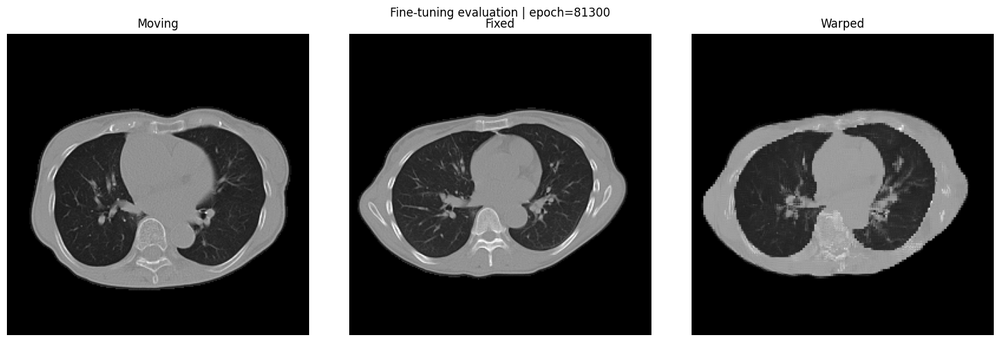

Global epoch 81301/110000 (fine-tuning 1301/30000), Loss: 0.0021
Global epoch 81302/110000 (fine-tuning 1302/30000), Loss: 0.0027
Global epoch 81303/110000 (fine-tuning 1303/30000), Loss: 0.0030
Global epoch 81304/110000 (fine-tuning 1304/30000), Loss: 0.0028
Global epoch 81305/110000 (fine-tuning 1305/30000), Loss: 0.0025
Global epoch 81306/110000 (fine-tuning 1306/30000), Loss: 0.0025
Global epoch 81307/110000 (fine-tuning 1307/30000), Loss: 0.0024
Global epoch 81308/110000 (fine-tuning 1308/30000), Loss: 0.0030
Global epoch 81309/110000 (fine-tuning 1309/30000), Loss: 0.0024
Global epoch 81310/110000 (fine-tuning 1310/30000), Loss: 0.0026
Global epoch 81311/110000 (fine-tuning 1311/30000), Loss: 0.0026
Global epoch 81312/110000 (fine-tuning 1312/30000), Loss: 0.0026
Global epoch 81313/110000 (fine-tuning 1313/30000), Loss: 0.0028
Global epoch 81314/110000 (fine-tuning 1314/30000), Loss: 0.0035
Global epoch 81315/110000 (fine-tuning 1315/30000), Loss: 0.0027
Global epoch 81316/110000

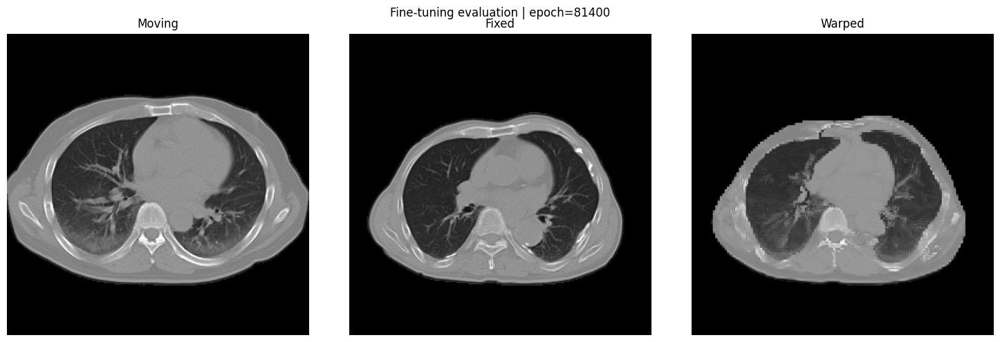

Global epoch 81401/110000 (fine-tuning 1401/30000), Loss: 0.0028
Global epoch 81402/110000 (fine-tuning 1402/30000), Loss: 0.0028
Global epoch 81403/110000 (fine-tuning 1403/30000), Loss: 0.0030
Global epoch 81404/110000 (fine-tuning 1404/30000), Loss: 0.0031
Global epoch 81405/110000 (fine-tuning 1405/30000), Loss: 0.0039
Global epoch 81406/110000 (fine-tuning 1406/30000), Loss: 0.0045
Global epoch 81407/110000 (fine-tuning 1407/30000), Loss: 0.0028
Global epoch 81408/110000 (fine-tuning 1408/30000), Loss: 0.0025
Global epoch 81409/110000 (fine-tuning 1409/30000), Loss: 0.0030
Global epoch 81410/110000 (fine-tuning 1410/30000), Loss: 0.0028
Global epoch 81411/110000 (fine-tuning 1411/30000), Loss: 0.0029
Global epoch 81412/110000 (fine-tuning 1412/30000), Loss: 0.0038
Global epoch 81413/110000 (fine-tuning 1413/30000), Loss: 0.0037
Global epoch 81414/110000 (fine-tuning 1414/30000), Loss: 0.0023
Global epoch 81415/110000 (fine-tuning 1415/30000), Loss: 0.0024
Global epoch 81416/110000

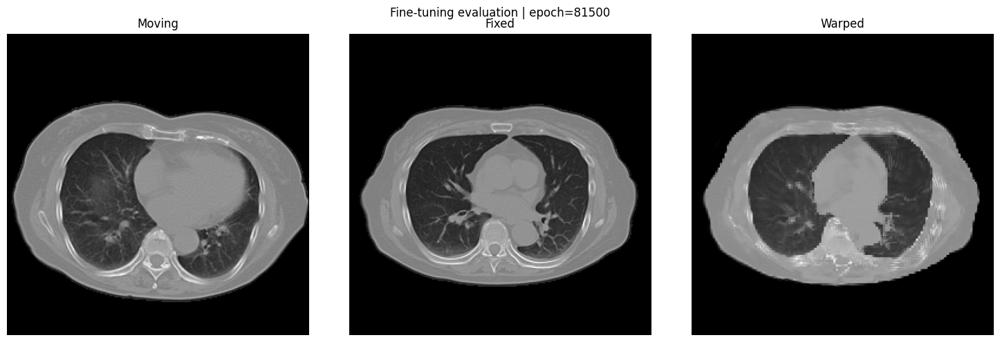

Global epoch 81501/110000 (fine-tuning 1501/30000), Loss: 0.0032
Global epoch 81502/110000 (fine-tuning 1502/30000), Loss: 0.0029
Global epoch 81503/110000 (fine-tuning 1503/30000), Loss: 0.0023
Global epoch 81504/110000 (fine-tuning 1504/30000), Loss: 0.0024
Global epoch 81505/110000 (fine-tuning 1505/30000), Loss: 0.0027
Global epoch 81506/110000 (fine-tuning 1506/30000), Loss: 0.0035
Global epoch 81507/110000 (fine-tuning 1507/30000), Loss: 0.0024
Global epoch 81508/110000 (fine-tuning 1508/30000), Loss: 0.0026
Global epoch 81509/110000 (fine-tuning 1509/30000), Loss: 0.0023
Global epoch 81510/110000 (fine-tuning 1510/30000), Loss: 0.0026
Global epoch 81511/110000 (fine-tuning 1511/30000), Loss: 0.0034
Global epoch 81512/110000 (fine-tuning 1512/30000), Loss: 0.0038
Global epoch 81513/110000 (fine-tuning 1513/30000), Loss: 0.0050
Global epoch 81514/110000 (fine-tuning 1514/30000), Loss: 0.0025
Global epoch 81515/110000 (fine-tuning 1515/30000), Loss: 0.0020
Global epoch 81516/110000

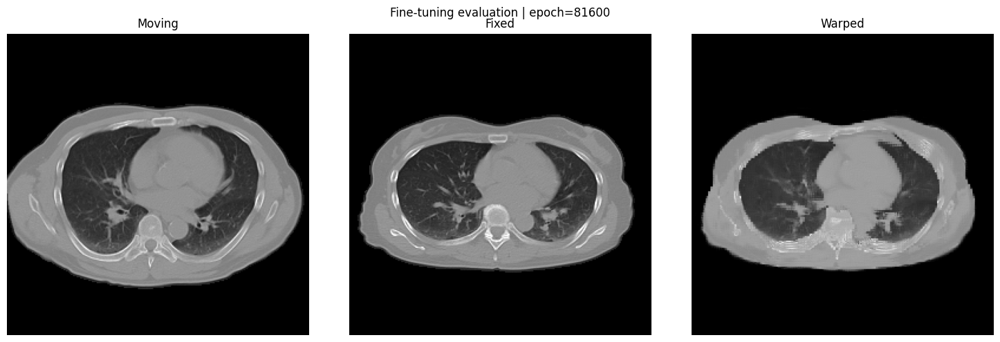

Global epoch 81601/110000 (fine-tuning 1601/30000), Loss: 0.0025
Global epoch 81602/110000 (fine-tuning 1602/30000), Loss: 0.0035
Global epoch 81603/110000 (fine-tuning 1603/30000), Loss: 0.0028
Global epoch 81604/110000 (fine-tuning 1604/30000), Loss: 0.0027
Global epoch 81605/110000 (fine-tuning 1605/30000), Loss: 0.0029
Global epoch 81606/110000 (fine-tuning 1606/30000), Loss: 0.0031
Global epoch 81607/110000 (fine-tuning 1607/30000), Loss: 0.0036
Global epoch 81608/110000 (fine-tuning 1608/30000), Loss: 0.0033
Global epoch 81609/110000 (fine-tuning 1609/30000), Loss: 0.0028
Global epoch 81610/110000 (fine-tuning 1610/30000), Loss: 0.0034
Global epoch 81611/110000 (fine-tuning 1611/30000), Loss: 0.0023
Global epoch 81612/110000 (fine-tuning 1612/30000), Loss: 0.0035
Global epoch 81613/110000 (fine-tuning 1613/30000), Loss: 0.0041
Global epoch 81614/110000 (fine-tuning 1614/30000), Loss: 0.0033
Global epoch 81615/110000 (fine-tuning 1615/30000), Loss: 0.0029
Global epoch 81616/110000

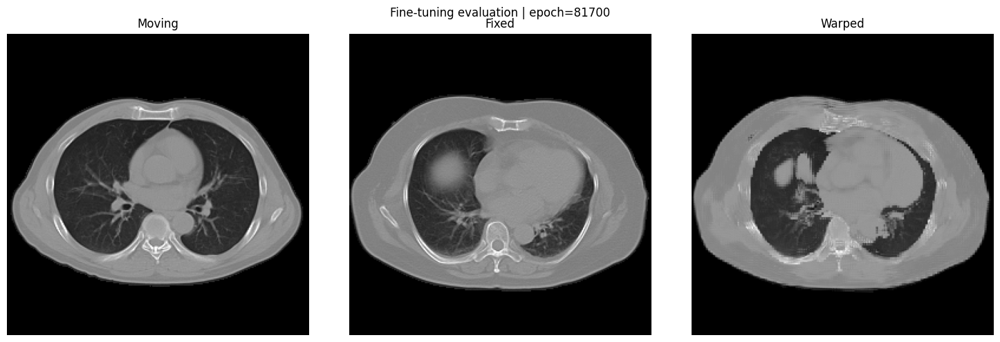

Global epoch 81701/110000 (fine-tuning 1701/30000), Loss: 0.0029
Global epoch 81702/110000 (fine-tuning 1702/30000), Loss: 0.0026
Global epoch 81703/110000 (fine-tuning 1703/30000), Loss: 0.0024
Global epoch 81704/110000 (fine-tuning 1704/30000), Loss: 0.0024
Global epoch 81705/110000 (fine-tuning 1705/30000), Loss: 0.0028
Global epoch 81706/110000 (fine-tuning 1706/30000), Loss: 0.0020
Global epoch 81707/110000 (fine-tuning 1707/30000), Loss: 0.0029
Global epoch 81708/110000 (fine-tuning 1708/30000), Loss: 0.0028
Global epoch 81709/110000 (fine-tuning 1709/30000), Loss: 0.0026
Global epoch 81710/110000 (fine-tuning 1710/30000), Loss: 0.0026
Global epoch 81711/110000 (fine-tuning 1711/30000), Loss: 0.0026
Global epoch 81712/110000 (fine-tuning 1712/30000), Loss: 0.0038
Global epoch 81713/110000 (fine-tuning 1713/30000), Loss: 0.0029
Global epoch 81714/110000 (fine-tuning 1714/30000), Loss: 0.0031
Global epoch 81715/110000 (fine-tuning 1715/30000), Loss: 0.0024
Global epoch 81716/110000

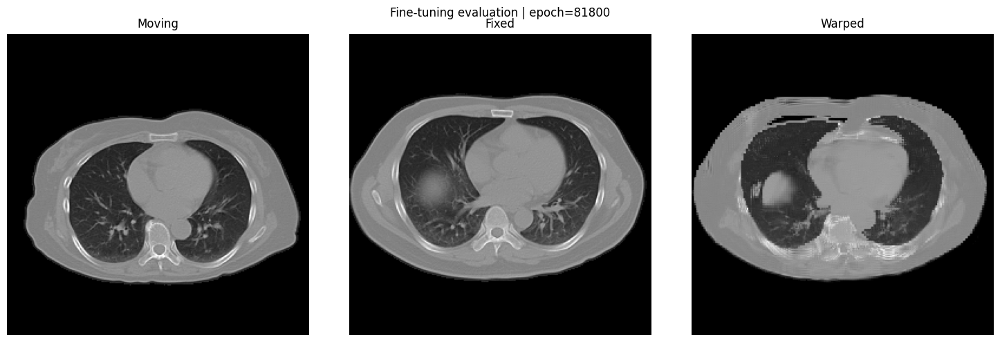

Global epoch 81801/110000 (fine-tuning 1801/30000), Loss: 0.0040
Global epoch 81802/110000 (fine-tuning 1802/30000), Loss: 0.0023
Global epoch 81803/110000 (fine-tuning 1803/30000), Loss: 0.0028
Global epoch 81804/110000 (fine-tuning 1804/30000), Loss: 0.0035
Global epoch 81805/110000 (fine-tuning 1805/30000), Loss: 0.0034
Global epoch 81806/110000 (fine-tuning 1806/30000), Loss: 0.0029
Global epoch 81807/110000 (fine-tuning 1807/30000), Loss: 0.0036
Global epoch 81808/110000 (fine-tuning 1808/30000), Loss: 0.0035
Global epoch 81809/110000 (fine-tuning 1809/30000), Loss: 0.0024
Global epoch 81810/110000 (fine-tuning 1810/30000), Loss: 0.0033
Global epoch 81811/110000 (fine-tuning 1811/30000), Loss: 0.0045
Global epoch 81812/110000 (fine-tuning 1812/30000), Loss: 0.0053
Global epoch 81813/110000 (fine-tuning 1813/30000), Loss: 0.0033
Global epoch 81814/110000 (fine-tuning 1814/30000), Loss: 0.0039
Global epoch 81815/110000 (fine-tuning 1815/30000), Loss: 0.0027
Global epoch 81816/110000

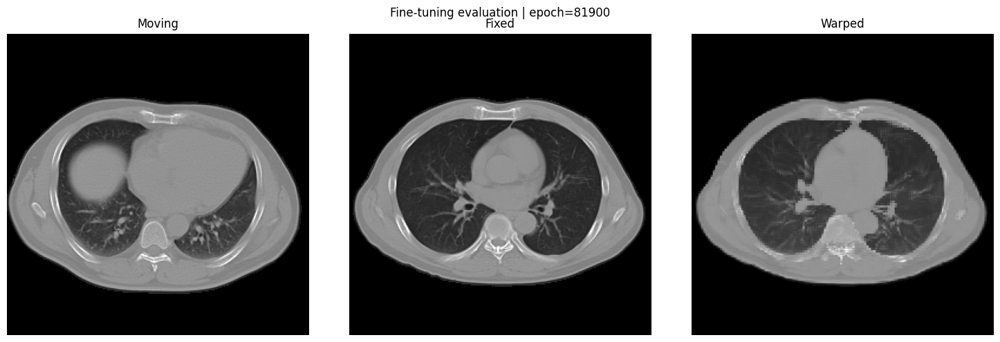

Global epoch 81901/110000 (fine-tuning 1901/30000), Loss: 0.0040
Global epoch 81902/110000 (fine-tuning 1902/30000), Loss: 0.0029
Global epoch 81903/110000 (fine-tuning 1903/30000), Loss: 0.0029
Global epoch 81904/110000 (fine-tuning 1904/30000), Loss: 0.0029
Global epoch 81905/110000 (fine-tuning 1905/30000), Loss: 0.0035
Global epoch 81906/110000 (fine-tuning 1906/30000), Loss: 0.0029
Global epoch 81907/110000 (fine-tuning 1907/30000), Loss: 0.0020
Global epoch 81908/110000 (fine-tuning 1908/30000), Loss: 0.0029
Global epoch 81909/110000 (fine-tuning 1909/30000), Loss: 0.0026
Global epoch 81910/110000 (fine-tuning 1910/30000), Loss: 0.0024
Global epoch 81911/110000 (fine-tuning 1911/30000), Loss: 0.0026
Global epoch 81912/110000 (fine-tuning 1912/30000), Loss: 0.0029
Global epoch 81913/110000 (fine-tuning 1913/30000), Loss: 0.0032
Global epoch 81914/110000 (fine-tuning 1914/30000), Loss: 0.0024
Global epoch 81915/110000 (fine-tuning 1915/30000), Loss: 0.0030
Global epoch 81916/110000

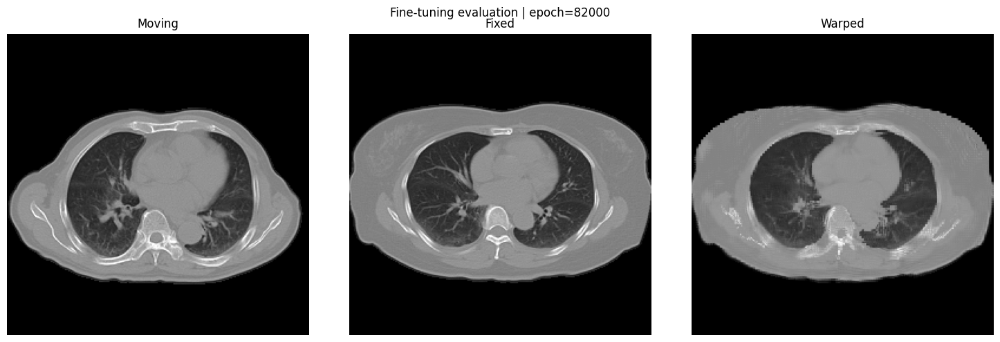

Global epoch 82001/110000 (fine-tuning 2001/30000), Loss: 0.0031
Global epoch 82002/110000 (fine-tuning 2002/30000), Loss: 0.0031
Global epoch 82003/110000 (fine-tuning 2003/30000), Loss: 0.0029
Global epoch 82004/110000 (fine-tuning 2004/30000), Loss: 0.0031
Global epoch 82005/110000 (fine-tuning 2005/30000), Loss: 0.0024
Global epoch 82006/110000 (fine-tuning 2006/30000), Loss: 0.0035
Global epoch 82007/110000 (fine-tuning 2007/30000), Loss: 0.0023
Global epoch 82008/110000 (fine-tuning 2008/30000), Loss: 0.0023
Global epoch 82009/110000 (fine-tuning 2009/30000), Loss: 0.0022
Global epoch 82010/110000 (fine-tuning 2010/30000), Loss: 0.0030
Global epoch 82011/110000 (fine-tuning 2011/30000), Loss: 0.0026
Global epoch 82012/110000 (fine-tuning 2012/30000), Loss: 0.0023
Global epoch 82013/110000 (fine-tuning 2013/30000), Loss: 0.0022
Global epoch 82014/110000 (fine-tuning 2014/30000), Loss: 0.0023
Global epoch 82015/110000 (fine-tuning 2015/30000), Loss: 0.0029
Global epoch 82016/110000

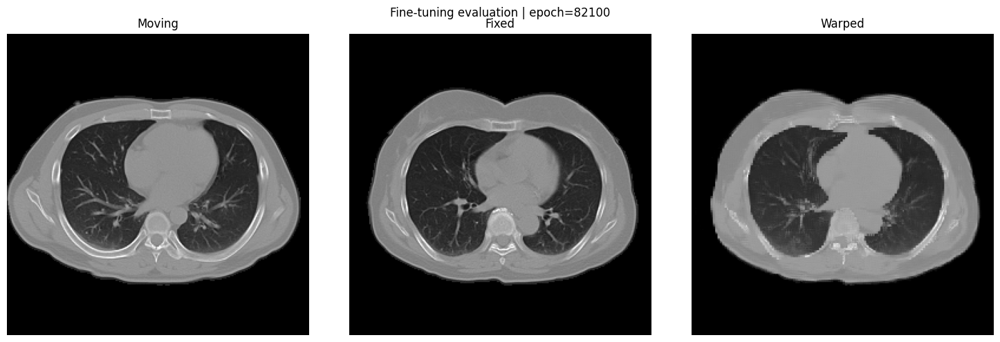

Global epoch 82101/110000 (fine-tuning 2101/30000), Loss: 0.0034
Global epoch 82102/110000 (fine-tuning 2102/30000), Loss: 0.0025
Global epoch 82103/110000 (fine-tuning 2103/30000), Loss: 0.0028
Global epoch 82104/110000 (fine-tuning 2104/30000), Loss: 0.0022
Global epoch 82105/110000 (fine-tuning 2105/30000), Loss: 0.0029
Global epoch 82106/110000 (fine-tuning 2106/30000), Loss: 0.0022
Global epoch 82107/110000 (fine-tuning 2107/30000), Loss: 0.0021
Global epoch 82108/110000 (fine-tuning 2108/30000), Loss: 0.0026
Global epoch 82109/110000 (fine-tuning 2109/30000), Loss: 0.0043
Global epoch 82110/110000 (fine-tuning 2110/30000), Loss: 0.0025
Global epoch 82111/110000 (fine-tuning 2111/30000), Loss: 0.0027
Global epoch 82112/110000 (fine-tuning 2112/30000), Loss: 0.0023
Global epoch 82113/110000 (fine-tuning 2113/30000), Loss: 0.0024
Global epoch 82114/110000 (fine-tuning 2114/30000), Loss: 0.0025
Global epoch 82115/110000 (fine-tuning 2115/30000), Loss: 0.0033
Global epoch 82116/110000

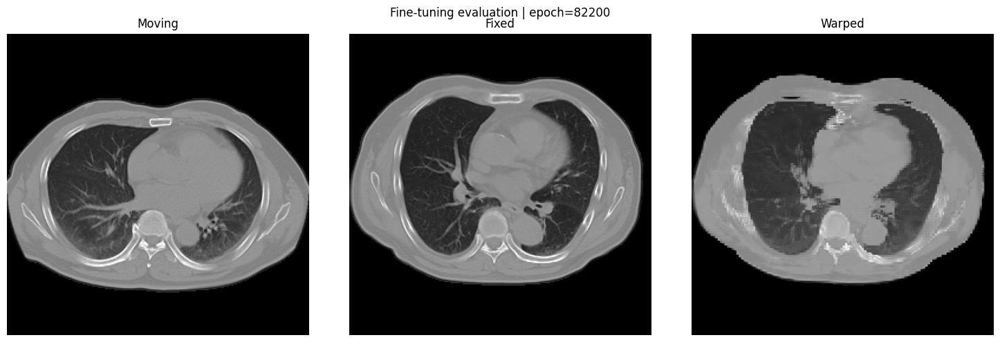

Global epoch 82201/110000 (fine-tuning 2201/30000), Loss: 0.0029
Global epoch 82202/110000 (fine-tuning 2202/30000), Loss: 0.0024
Global epoch 82203/110000 (fine-tuning 2203/30000), Loss: 0.0022
Global epoch 82204/110000 (fine-tuning 2204/30000), Loss: 0.0032
Global epoch 82205/110000 (fine-tuning 2205/30000), Loss: 0.0032
Global epoch 82206/110000 (fine-tuning 2206/30000), Loss: 0.0026
Global epoch 82207/110000 (fine-tuning 2207/30000), Loss: 0.0026
Global epoch 82208/110000 (fine-tuning 2208/30000), Loss: 0.0019
Global epoch 82209/110000 (fine-tuning 2209/30000), Loss: 0.0027
Global epoch 82210/110000 (fine-tuning 2210/30000), Loss: 0.0032
Global epoch 82211/110000 (fine-tuning 2211/30000), Loss: 0.0029
Global epoch 82212/110000 (fine-tuning 2212/30000), Loss: 0.0026
Global epoch 82213/110000 (fine-tuning 2213/30000), Loss: 0.0025
Global epoch 82214/110000 (fine-tuning 2214/30000), Loss: 0.0030
Global epoch 82215/110000 (fine-tuning 2215/30000), Loss: 0.0028
Global epoch 82216/110000

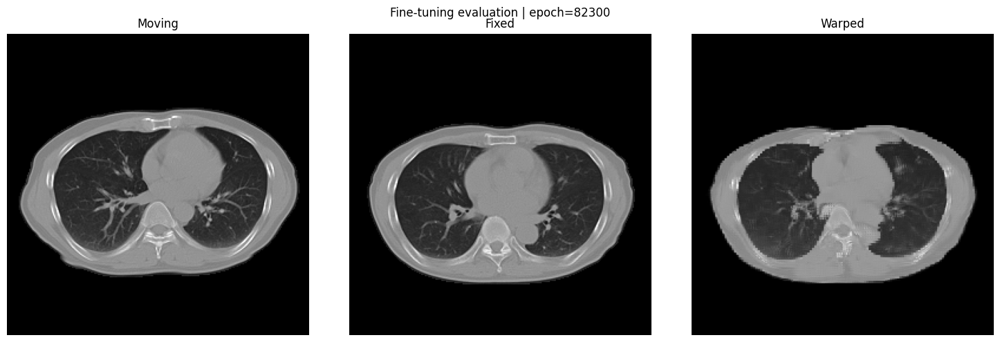

Global epoch 82301/110000 (fine-tuning 2301/30000), Loss: 0.0034
Global epoch 82302/110000 (fine-tuning 2302/30000), Loss: 0.0054
Global epoch 82303/110000 (fine-tuning 2303/30000), Loss: 0.0039
Global epoch 82304/110000 (fine-tuning 2304/30000), Loss: 0.0033
Global epoch 82305/110000 (fine-tuning 2305/30000), Loss: 0.0066
Global epoch 82306/110000 (fine-tuning 2306/30000), Loss: 0.0029
Global epoch 82307/110000 (fine-tuning 2307/30000), Loss: 0.0038
Global epoch 82308/110000 (fine-tuning 2308/30000), Loss: 0.0045
Global epoch 82309/110000 (fine-tuning 2309/30000), Loss: 0.0074
Global epoch 82310/110000 (fine-tuning 2310/30000), Loss: 0.0032
Global epoch 82311/110000 (fine-tuning 2311/30000), Loss: 0.0040
Global epoch 82312/110000 (fine-tuning 2312/30000), Loss: 0.0074
Global epoch 82313/110000 (fine-tuning 2313/30000), Loss: 0.0046
Global epoch 82314/110000 (fine-tuning 2314/30000), Loss: 0.0038
Global epoch 82315/110000 (fine-tuning 2315/30000), Loss: 0.0043
Global epoch 82316/110000

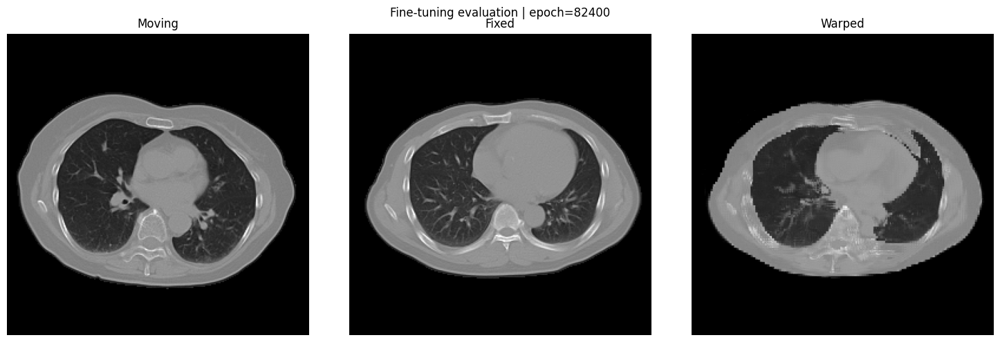

Global epoch 82401/110000 (fine-tuning 2401/30000), Loss: 0.0052
Global epoch 82402/110000 (fine-tuning 2402/30000), Loss: 0.0046
Global epoch 82403/110000 (fine-tuning 2403/30000), Loss: 0.0029
Global epoch 82404/110000 (fine-tuning 2404/30000), Loss: 0.0032
Global epoch 82405/110000 (fine-tuning 2405/30000), Loss: 0.0033
Global epoch 82406/110000 (fine-tuning 2406/30000), Loss: 0.0043
Global epoch 82407/110000 (fine-tuning 2407/30000), Loss: 0.0035
Global epoch 82408/110000 (fine-tuning 2408/30000), Loss: 0.0055
Global epoch 82409/110000 (fine-tuning 2409/30000), Loss: 0.0031
Global epoch 82410/110000 (fine-tuning 2410/30000), Loss: 0.0035
Global epoch 82411/110000 (fine-tuning 2411/30000), Loss: 0.0032
Global epoch 82412/110000 (fine-tuning 2412/30000), Loss: 0.0036
Global epoch 82413/110000 (fine-tuning 2413/30000), Loss: 0.0040
Global epoch 82414/110000 (fine-tuning 2414/30000), Loss: 0.0033
Global epoch 82415/110000 (fine-tuning 2415/30000), Loss: 0.0036
Global epoch 82416/110000

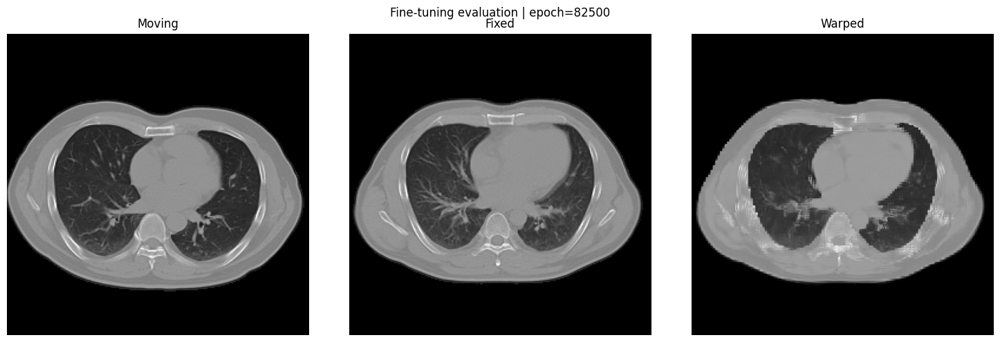

Global epoch 82501/110000 (fine-tuning 2501/30000), Loss: 0.0031
Global epoch 82502/110000 (fine-tuning 2502/30000), Loss: 0.0021
Global epoch 82503/110000 (fine-tuning 2503/30000), Loss: 0.0026
Global epoch 82504/110000 (fine-tuning 2504/30000), Loss: 0.0024
Global epoch 82505/110000 (fine-tuning 2505/30000), Loss: 0.0031
Global epoch 82506/110000 (fine-tuning 2506/30000), Loss: 0.0024
Global epoch 82507/110000 (fine-tuning 2507/30000), Loss: 0.0025
Global epoch 82508/110000 (fine-tuning 2508/30000), Loss: 0.0028
Global epoch 82509/110000 (fine-tuning 2509/30000), Loss: 0.0022
Global epoch 82510/110000 (fine-tuning 2510/30000), Loss: 0.0028
Global epoch 82511/110000 (fine-tuning 2511/30000), Loss: 0.0039
Global epoch 82512/110000 (fine-tuning 2512/30000), Loss: 0.0033
Global epoch 82513/110000 (fine-tuning 2513/30000), Loss: 0.0029
Global epoch 82514/110000 (fine-tuning 2514/30000), Loss: 0.0026
Global epoch 82515/110000 (fine-tuning 2515/30000), Loss: 0.0033
Global epoch 82516/110000

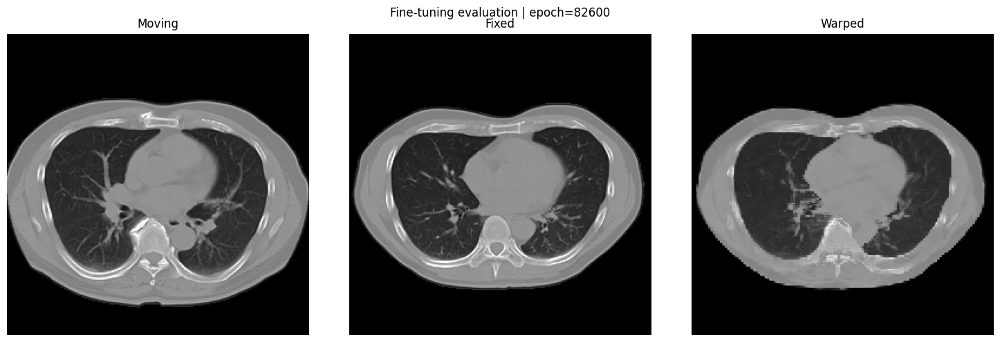

Global epoch 82601/110000 (fine-tuning 2601/30000), Loss: 0.0022
Global epoch 82602/110000 (fine-tuning 2602/30000), Loss: 0.0024
Global epoch 82603/110000 (fine-tuning 2603/30000), Loss: 0.0029
Global epoch 82604/110000 (fine-tuning 2604/30000), Loss: 0.0029
Global epoch 82605/110000 (fine-tuning 2605/30000), Loss: 0.0027
Global epoch 82606/110000 (fine-tuning 2606/30000), Loss: 0.0038
Global epoch 82607/110000 (fine-tuning 2607/30000), Loss: 0.0030
Global epoch 82608/110000 (fine-tuning 2608/30000), Loss: 0.0033
Global epoch 82609/110000 (fine-tuning 2609/30000), Loss: 0.0028
Global epoch 82610/110000 (fine-tuning 2610/30000), Loss: 0.0038
Global epoch 82611/110000 (fine-tuning 2611/30000), Loss: 0.0025
Global epoch 82612/110000 (fine-tuning 2612/30000), Loss: 0.0031
Global epoch 82613/110000 (fine-tuning 2613/30000), Loss: 0.0032
Global epoch 82614/110000 (fine-tuning 2614/30000), Loss: 0.0025
Global epoch 82615/110000 (fine-tuning 2615/30000), Loss: 0.0036
Global epoch 82616/110000

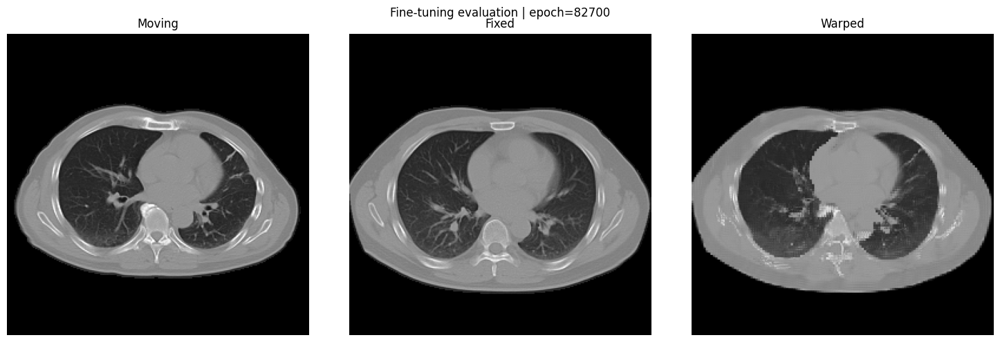

Global epoch 82701/110000 (fine-tuning 2701/30000), Loss: 0.0030
Global epoch 82702/110000 (fine-tuning 2702/30000), Loss: 0.0022
Global epoch 82703/110000 (fine-tuning 2703/30000), Loss: 0.0024
Global epoch 82704/110000 (fine-tuning 2704/30000), Loss: 0.0021
Global epoch 82705/110000 (fine-tuning 2705/30000), Loss: 0.0030
Global epoch 82706/110000 (fine-tuning 2706/30000), Loss: 0.0033
Global epoch 82707/110000 (fine-tuning 2707/30000), Loss: 0.0022
Global epoch 82708/110000 (fine-tuning 2708/30000), Loss: 0.0033
Global epoch 82709/110000 (fine-tuning 2709/30000), Loss: 0.0024
Global epoch 82710/110000 (fine-tuning 2710/30000), Loss: 0.0024
Global epoch 82711/110000 (fine-tuning 2711/30000), Loss: 0.0023
Global epoch 82712/110000 (fine-tuning 2712/30000), Loss: 0.0030
Global epoch 82713/110000 (fine-tuning 2713/30000), Loss: 0.0026
Global epoch 82714/110000 (fine-tuning 2714/30000), Loss: 0.0023
Global epoch 82715/110000 (fine-tuning 2715/30000), Loss: 0.0024
Global epoch 82716/110000

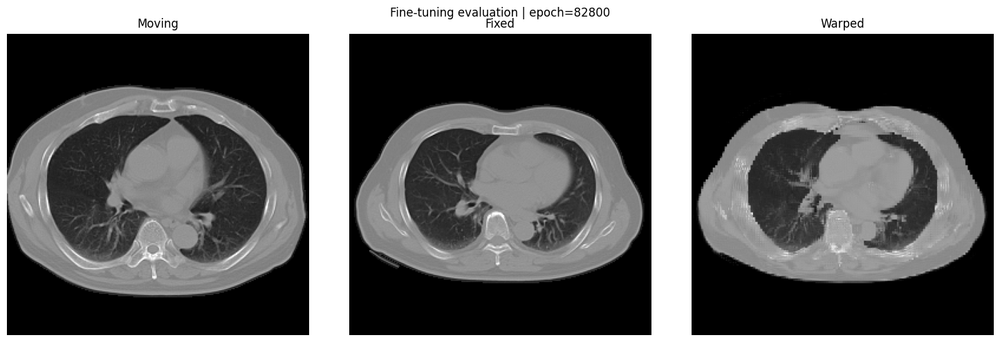

Global epoch 82801/110000 (fine-tuning 2801/30000), Loss: 0.0027
Global epoch 82802/110000 (fine-tuning 2802/30000), Loss: 0.0028
Global epoch 82803/110000 (fine-tuning 2803/30000), Loss: 0.0025
Global epoch 82804/110000 (fine-tuning 2804/30000), Loss: 0.0048
Global epoch 82805/110000 (fine-tuning 2805/30000), Loss: 0.0023
Global epoch 82806/110000 (fine-tuning 2806/30000), Loss: 0.0030
Global epoch 82807/110000 (fine-tuning 2807/30000), Loss: 0.0031
Global epoch 82808/110000 (fine-tuning 2808/30000), Loss: 0.0028
Global epoch 82809/110000 (fine-tuning 2809/30000), Loss: 0.0071
Global epoch 82810/110000 (fine-tuning 2810/30000), Loss: 0.0024
Global epoch 82811/110000 (fine-tuning 2811/30000), Loss: 0.0036
Global epoch 82812/110000 (fine-tuning 2812/30000), Loss: 0.0029
Global epoch 82813/110000 (fine-tuning 2813/30000), Loss: 0.0024
Global epoch 82814/110000 (fine-tuning 2814/30000), Loss: 0.0033
Global epoch 82815/110000 (fine-tuning 2815/30000), Loss: 0.0030
Global epoch 82816/110000

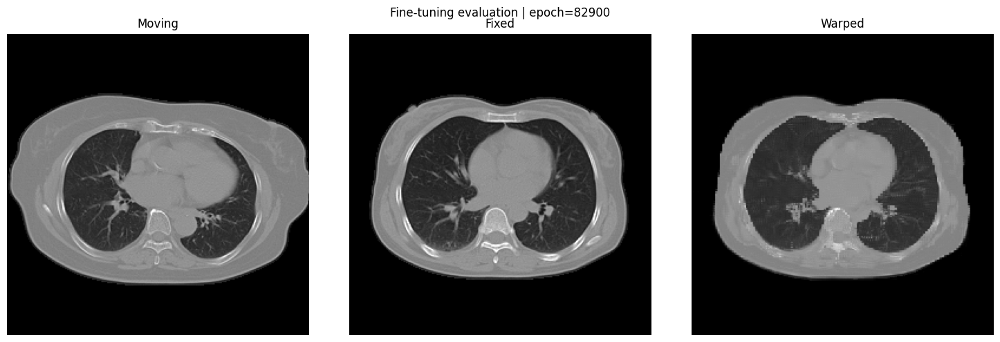

Global epoch 82901/110000 (fine-tuning 2901/30000), Loss: 0.0031
Global epoch 82902/110000 (fine-tuning 2902/30000), Loss: 0.0028
Global epoch 82903/110000 (fine-tuning 2903/30000), Loss: 0.0026
Global epoch 82904/110000 (fine-tuning 2904/30000), Loss: 0.0036
Global epoch 82905/110000 (fine-tuning 2905/30000), Loss: 0.0033
Global epoch 82906/110000 (fine-tuning 2906/30000), Loss: 0.0022
Global epoch 82907/110000 (fine-tuning 2907/30000), Loss: 0.0029
Global epoch 82908/110000 (fine-tuning 2908/30000), Loss: 0.0022
Global epoch 82909/110000 (fine-tuning 2909/30000), Loss: 0.0028
Global epoch 82910/110000 (fine-tuning 2910/30000), Loss: 0.0033
Global epoch 82911/110000 (fine-tuning 2911/30000), Loss: 0.0022
Global epoch 82912/110000 (fine-tuning 2912/30000), Loss: 0.0033
Global epoch 82913/110000 (fine-tuning 2913/30000), Loss: 0.0022
Global epoch 82914/110000 (fine-tuning 2914/30000), Loss: 0.0031
Global epoch 82915/110000 (fine-tuning 2915/30000), Loss: 0.0026
Global epoch 82916/110000

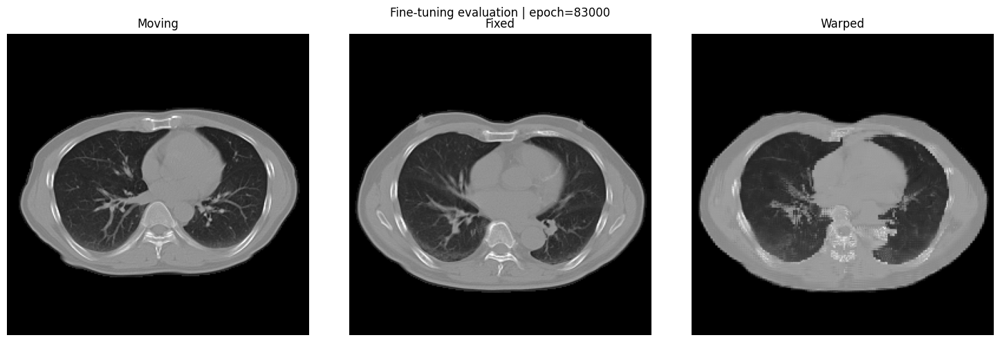

Global epoch 83001/110000 (fine-tuning 3001/30000), Loss: 0.0024
Global epoch 83002/110000 (fine-tuning 3002/30000), Loss: 0.0024
Global epoch 83003/110000 (fine-tuning 3003/30000), Loss: 0.0028
Global epoch 83004/110000 (fine-tuning 3004/30000), Loss: 0.0027
Global epoch 83005/110000 (fine-tuning 3005/30000), Loss: 0.0024
Global epoch 83006/110000 (fine-tuning 3006/30000), Loss: 0.0026
Global epoch 83007/110000 (fine-tuning 3007/30000), Loss: 0.0035
Global epoch 83008/110000 (fine-tuning 3008/30000), Loss: 0.0025
Global epoch 83009/110000 (fine-tuning 3009/30000), Loss: 0.0021
Global epoch 83010/110000 (fine-tuning 3010/30000), Loss: 0.0024
Global epoch 83011/110000 (fine-tuning 3011/30000), Loss: 0.0027
Global epoch 83012/110000 (fine-tuning 3012/30000), Loss: 0.0033
Global epoch 83013/110000 (fine-tuning 3013/30000), Loss: 0.0022
Global epoch 83014/110000 (fine-tuning 3014/30000), Loss: 0.0020
Global epoch 83015/110000 (fine-tuning 3015/30000), Loss: 0.0021
Global epoch 83016/110000

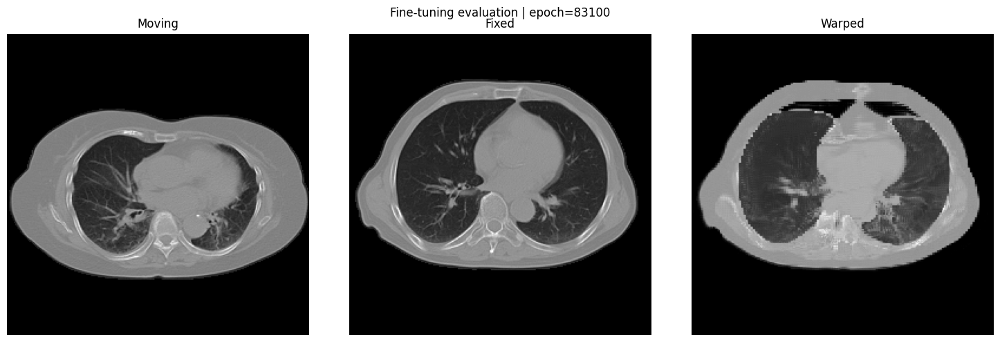

Global epoch 83101/110000 (fine-tuning 3101/30000), Loss: 0.0023
Global epoch 83102/110000 (fine-tuning 3102/30000), Loss: 0.0024
Global epoch 83103/110000 (fine-tuning 3103/30000), Loss: 0.0034
Global epoch 83104/110000 (fine-tuning 3104/30000), Loss: 0.0023
Global epoch 83105/110000 (fine-tuning 3105/30000), Loss: 0.0026
Global epoch 83106/110000 (fine-tuning 3106/30000), Loss: 0.0028
Global epoch 83107/110000 (fine-tuning 3107/30000), Loss: 0.0025
Global epoch 83108/110000 (fine-tuning 3108/30000), Loss: 0.0026
Global epoch 83109/110000 (fine-tuning 3109/30000), Loss: 0.0026
Global epoch 83110/110000 (fine-tuning 3110/30000), Loss: 0.0023
Global epoch 83111/110000 (fine-tuning 3111/30000), Loss: 0.0024
Global epoch 83112/110000 (fine-tuning 3112/30000), Loss: 0.0031
Global epoch 83113/110000 (fine-tuning 3113/30000), Loss: 0.0025
Global epoch 83114/110000 (fine-tuning 3114/30000), Loss: 0.0025
Global epoch 83115/110000 (fine-tuning 3115/30000), Loss: 0.0023
Global epoch 83116/110000

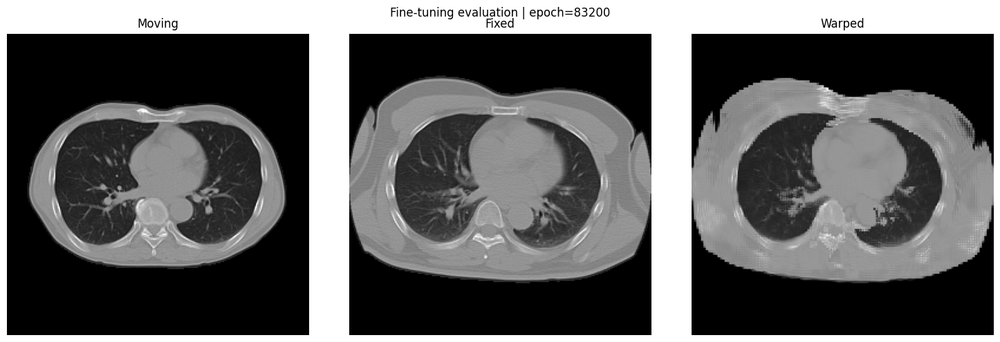

Global epoch 83201/110000 (fine-tuning 3201/30000), Loss: 0.0030
Global epoch 83202/110000 (fine-tuning 3202/30000), Loss: 0.0040
Global epoch 83203/110000 (fine-tuning 3203/30000), Loss: 0.0023
Global epoch 83204/110000 (fine-tuning 3204/30000), Loss: 0.0024
Global epoch 83205/110000 (fine-tuning 3205/30000), Loss: 0.0027
Global epoch 83206/110000 (fine-tuning 3206/30000), Loss: 0.0039
Global epoch 83207/110000 (fine-tuning 3207/30000), Loss: 0.0029
Global epoch 83208/110000 (fine-tuning 3208/30000), Loss: 0.0031
Global epoch 83209/110000 (fine-tuning 3209/30000), Loss: 0.0057
Global epoch 83210/110000 (fine-tuning 3210/30000), Loss: 0.0026
Global epoch 83211/110000 (fine-tuning 3211/30000), Loss: 0.0026
Global epoch 83212/110000 (fine-tuning 3212/30000), Loss: 0.0035
Global epoch 83213/110000 (fine-tuning 3213/30000), Loss: 0.0026
Global epoch 83214/110000 (fine-tuning 3214/30000), Loss: 0.0023
Global epoch 83215/110000 (fine-tuning 3215/30000), Loss: 0.0031
Global epoch 83216/110000

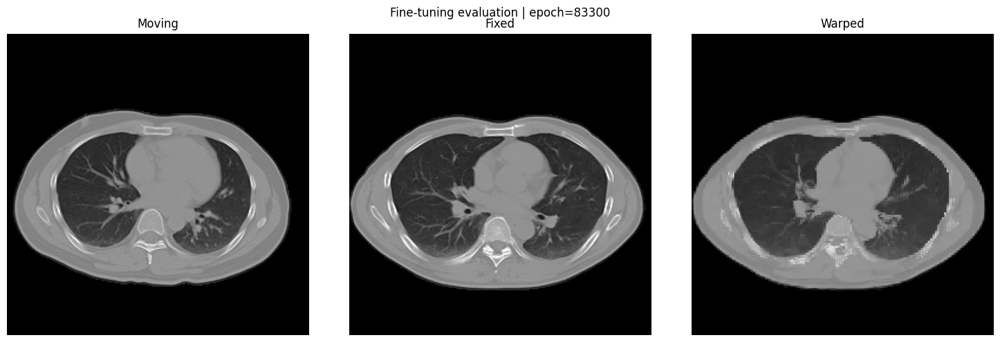

Global epoch 83301/110000 (fine-tuning 3301/30000), Loss: 0.0028
Global epoch 83302/110000 (fine-tuning 3302/30000), Loss: 0.0023
Global epoch 83303/110000 (fine-tuning 3303/30000), Loss: 0.0036
Global epoch 83304/110000 (fine-tuning 3304/30000), Loss: 0.0022
Global epoch 83305/110000 (fine-tuning 3305/30000), Loss: 0.0021
Global epoch 83306/110000 (fine-tuning 3306/30000), Loss: 0.0022
Global epoch 83307/110000 (fine-tuning 3307/30000), Loss: 0.0029
Global epoch 83308/110000 (fine-tuning 3308/30000), Loss: 0.0023
Global epoch 83309/110000 (fine-tuning 3309/30000), Loss: 0.0025
Global epoch 83310/110000 (fine-tuning 3310/30000), Loss: 0.0024
Global epoch 83311/110000 (fine-tuning 3311/30000), Loss: 0.0025
Global epoch 83312/110000 (fine-tuning 3312/30000), Loss: 0.0028
Global epoch 83313/110000 (fine-tuning 3313/30000), Loss: 0.0022
Global epoch 83314/110000 (fine-tuning 3314/30000), Loss: 0.0033
Global epoch 83315/110000 (fine-tuning 3315/30000), Loss: 0.0028
Global epoch 83316/110000

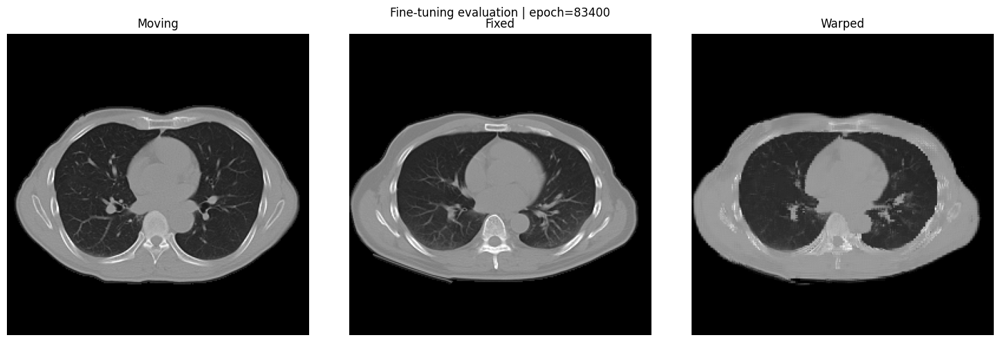

Global epoch 83401/110000 (fine-tuning 3401/30000), Loss: 0.0029
Global epoch 83402/110000 (fine-tuning 3402/30000), Loss: 0.0032
Global epoch 83403/110000 (fine-tuning 3403/30000), Loss: 0.0031
Global epoch 83404/110000 (fine-tuning 3404/30000), Loss: 0.0025
Global epoch 83405/110000 (fine-tuning 3405/30000), Loss: 0.0025
Global epoch 83406/110000 (fine-tuning 3406/30000), Loss: 0.0026
Global epoch 83407/110000 (fine-tuning 3407/30000), Loss: 0.0025
Global epoch 83408/110000 (fine-tuning 3408/30000), Loss: 0.0040
Global epoch 83409/110000 (fine-tuning 3409/30000), Loss: 0.0029
Global epoch 83410/110000 (fine-tuning 3410/30000), Loss: 0.0029
Global epoch 83411/110000 (fine-tuning 3411/30000), Loss: 0.0034
Global epoch 83412/110000 (fine-tuning 3412/30000), Loss: 0.0034
Global epoch 83413/110000 (fine-tuning 3413/30000), Loss: 0.0028
Global epoch 83414/110000 (fine-tuning 3414/30000), Loss: 0.0030
Global epoch 83415/110000 (fine-tuning 3415/30000), Loss: 0.0024
Global epoch 83416/110000

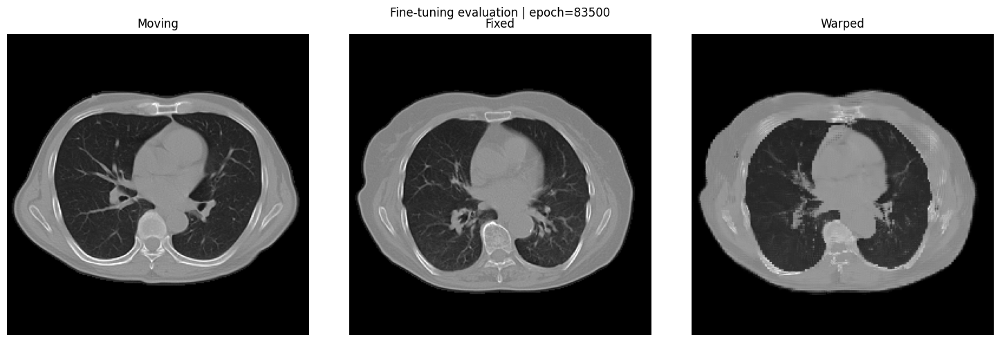

Global epoch 83501/110000 (fine-tuning 3501/30000), Loss: 0.0027
Global epoch 83502/110000 (fine-tuning 3502/30000), Loss: 0.0026
Global epoch 83503/110000 (fine-tuning 3503/30000), Loss: 0.0024
Global epoch 83504/110000 (fine-tuning 3504/30000), Loss: 0.0028
Global epoch 83505/110000 (fine-tuning 3505/30000), Loss: 0.0030
Global epoch 83506/110000 (fine-tuning 3506/30000), Loss: 0.0025
Global epoch 83507/110000 (fine-tuning 3507/30000), Loss: 0.0023
Global epoch 83508/110000 (fine-tuning 3508/30000), Loss: 0.0028
Global epoch 83509/110000 (fine-tuning 3509/30000), Loss: 0.0023
Global epoch 83510/110000 (fine-tuning 3510/30000), Loss: 0.0030
Global epoch 83511/110000 (fine-tuning 3511/30000), Loss: 0.0024
Global epoch 83512/110000 (fine-tuning 3512/30000), Loss: 0.0026
Global epoch 83513/110000 (fine-tuning 3513/30000), Loss: 0.0025
Global epoch 83514/110000 (fine-tuning 3514/30000), Loss: 0.0022
Global epoch 83515/110000 (fine-tuning 3515/30000), Loss: 0.0024
Global epoch 83516/110000

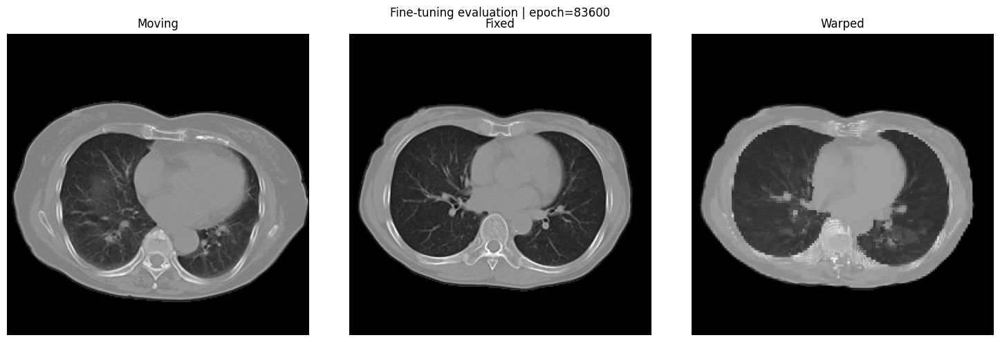

Global epoch 83601/110000 (fine-tuning 3601/30000), Loss: 0.0027
Global epoch 83602/110000 (fine-tuning 3602/30000), Loss: 0.0026
Global epoch 83603/110000 (fine-tuning 3603/30000), Loss: 0.0024
Global epoch 83604/110000 (fine-tuning 3604/30000), Loss: 0.0025
Global epoch 83605/110000 (fine-tuning 3605/30000), Loss: 0.0022
Global epoch 83606/110000 (fine-tuning 3606/30000), Loss: 0.0026
Global epoch 83607/110000 (fine-tuning 3607/30000), Loss: 0.0031
Global epoch 83608/110000 (fine-tuning 3608/30000), Loss: 0.0029
Global epoch 83609/110000 (fine-tuning 3609/30000), Loss: 0.0033
Global epoch 83610/110000 (fine-tuning 3610/30000), Loss: 0.0029
Global epoch 83611/110000 (fine-tuning 3611/30000), Loss: 0.0026
Global epoch 83612/110000 (fine-tuning 3612/30000), Loss: 0.0024
Global epoch 83613/110000 (fine-tuning 3613/30000), Loss: 0.0025
Global epoch 83614/110000 (fine-tuning 3614/30000), Loss: 0.0024
Global epoch 83615/110000 (fine-tuning 3615/30000), Loss: 0.0028
Global epoch 83616/110000

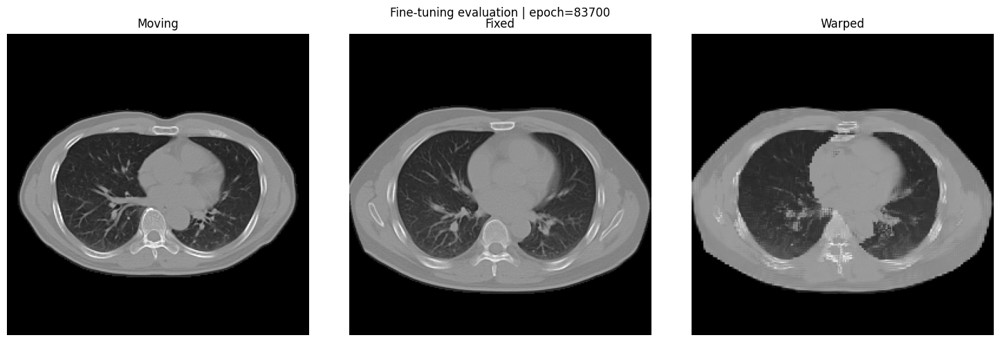

Global epoch 83701/110000 (fine-tuning 3701/30000), Loss: 0.0026
Global epoch 83702/110000 (fine-tuning 3702/30000), Loss: 0.0020
Global epoch 83703/110000 (fine-tuning 3703/30000), Loss: 0.0036
Global epoch 83704/110000 (fine-tuning 3704/30000), Loss: 0.0024
Global epoch 83705/110000 (fine-tuning 3705/30000), Loss: 0.0024
Global epoch 83706/110000 (fine-tuning 3706/30000), Loss: 0.0033
Global epoch 83707/110000 (fine-tuning 3707/30000), Loss: 0.0024
Global epoch 83708/110000 (fine-tuning 3708/30000), Loss: 0.0024
Global epoch 83709/110000 (fine-tuning 3709/30000), Loss: 0.0018
Global epoch 83710/110000 (fine-tuning 3710/30000), Loss: 0.0027
Global epoch 83711/110000 (fine-tuning 3711/30000), Loss: 0.0027
Global epoch 83712/110000 (fine-tuning 3712/30000), Loss: 0.0020
Global epoch 83713/110000 (fine-tuning 3713/30000), Loss: 0.0028
Global epoch 83714/110000 (fine-tuning 3714/30000), Loss: 0.0025
Global epoch 83715/110000 (fine-tuning 3715/30000), Loss: 0.0024
Global epoch 83716/110000

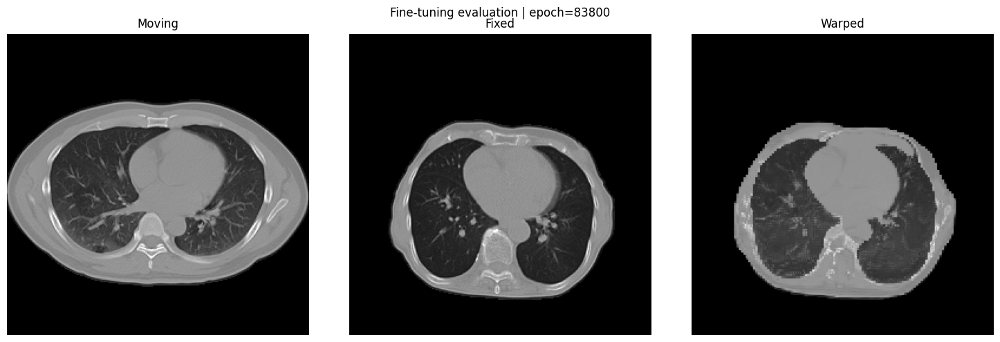

Global epoch 83801/110000 (fine-tuning 3801/30000), Loss: 0.0030
Global epoch 83802/110000 (fine-tuning 3802/30000), Loss: 0.0031
Global epoch 83803/110000 (fine-tuning 3803/30000), Loss: 0.0021
Global epoch 83804/110000 (fine-tuning 3804/30000), Loss: 0.0025
Global epoch 83805/110000 (fine-tuning 3805/30000), Loss: 0.0026
Global epoch 83806/110000 (fine-tuning 3806/30000), Loss: 0.0034
Global epoch 83807/110000 (fine-tuning 3807/30000), Loss: 0.0025
Global epoch 83808/110000 (fine-tuning 3808/30000), Loss: 0.0028
Global epoch 83809/110000 (fine-tuning 3809/30000), Loss: 0.0025
Global epoch 83810/110000 (fine-tuning 3810/30000), Loss: 0.0020
Global epoch 83811/110000 (fine-tuning 3811/30000), Loss: 0.0024
Global epoch 83812/110000 (fine-tuning 3812/30000), Loss: 0.0027
Global epoch 83813/110000 (fine-tuning 3813/30000), Loss: 0.0034
Global epoch 83814/110000 (fine-tuning 3814/30000), Loss: 0.0026
Global epoch 83815/110000 (fine-tuning 3815/30000), Loss: 0.0025
Global epoch 83816/110000

In [ ]:
from tqdm.notebook import tqdm

PRETRAIN_EPOCHS = 80_000
FINETUNE_EPOCHS = 30_000

# True: reuse the model and Adam state from the 80k cell in this same kernel.
# False: create a model from PRETRAIN_CHECKPOINT_PATH (use after restarting the kernel).
REUSE_IN_MEMORY_PRETRAIN = True

if REUSE_IN_MEMORY_PRETRAIN:
    if 'model3D' not in globals() or 'optimizer' not in globals():
        raise RuntimeError(
            'No in-memory pretraining state was found. Set '
            'REUSE_IN_MEMORY_PRETRAIN = False to load the checkpoint instead.'
        )
    pretrain_completed_epoch = PRETRAIN_EPOCHS
    print('Reusing in-memory model and optimizer state from global epoch 80,000.')
else:
    model3D = vxm.networks.VxmDense_128_256_128((128, 256, 256), nb_features, int_steps=0)
    pretrain_checkpoint = torch.load(PRETRAIN_CHECKPOINT_PATH, map_location=device)
    optimizer = optim.Adam(model3D.parameters(), lr=1e-4)

    if isinstance(pretrain_checkpoint, dict) and 'model_state_dict' in pretrain_checkpoint:
        model3D.load_state_dict(pretrain_checkpoint['model_state_dict'])
        if 'optimizer_state_dict' in pretrain_checkpoint:
            optimizer.load_state_dict(pretrain_checkpoint['optimizer_state_dict'])
        pretrain_completed_epoch = int(pretrain_checkpoint.get('global_epoch', PRETRAIN_EPOCHS))
    else:
        # Compatibility with the former weight-only checkpoint format.  Its optimizer
        # state cannot be recovered, so rerun pretraining to obtain fully continuous
        # model and optimizer state.
        model3D.load_state_dict(pretrain_checkpoint)
        pretrain_completed_epoch = PRETRAIN_EPOCHS
        print('WARNING: loaded a legacy weight-only pretraining checkpoint; optimizer state restarts.')

model3D.to(device)
finetune_start_epoch = pretrain_completed_epoch + 1
final_global_epoch = pretrain_completed_epoch + FINETUNE_EPOCHS
print(f'Fine-tuning resumes at global epoch {finetune_start_epoch} and ends at {final_global_epoch}.')

# Fine-tuning is the second phase of one 110k-epoch training run.
losses = []
mses = []
grads = []

for global_epoch in tqdm(
    range(finetune_start_epoch, final_global_epoch + 1),
    desc='Fine-tuning',
):
    finetune_epoch = global_epoch - pretrain_completed_epoch

    # 学習データのバッチを取得
    train_batch, _ = next(train_generator)
    moving_images = torch.as_tensor(
        train_batch[0], dtype=torch.float32, device=device
    )
    fixed_images = torch.as_tensor(
        train_batch[1], dtype=torch.float32, device=device
    )
        
    # Wavelet 変換（前処理）
    moving_w = haar_wavelet_3d(moving_images)  # (B,8,D/2,H/2,W/2)
    fixed_w  = haar_wavelet_3d(fixed_images)   # (B,8,D/2,H/2,W/2)
    
    # device に戻す
    moving_w = moving_w.to(device)
    fixed_w  = fixed_w.to(device)

    # 勾配を初期化
    optimizer.zero_grad()

    # 順伝播
    Vec = model3D(moving_w, fixed_w)

    # --- 各 Wavelet 成分を変形 ---
    moving_LLL = transformer(moving_w[:, 0:1], Vec)
    moving_LLH = transformer(moving_w[:, 1:2], Vec)
    moving_LHL = transformer(moving_w[:, 2:3], Vec)
    moving_LHH = transformer(moving_w[:, 3:4], Vec)
    moving_HLL = transformer(moving_w[:, 4:5], Vec)
    moving_HLH = transformer(moving_w[:, 5:6], Vec)
    moving_HHL = transformer(moving_w[:, 6:7], Vec)
    moving_HHH = transformer(moving_w[:, 7:8], Vec)
    
    moving_warped = torch.cat(
        [
            moving_LLL, moving_LLH, moving_LHL, moving_LHH,
            moving_HLL, moving_HLH, moving_HHL, moving_HHH
        ],
        dim=1
    )  # (B,8,D/2,H/2,W/2)
    
    # 逆Wavelet
    transformed_image = inverse_haar_wavelet_3d(moving_warped)
    
    transformed_image = transformed_image.to(device)    
    # 損失を計算
    loss = MSE_Loss(fixed_images, transformed_image)

    # 逆伝播
    loss.backward()
    optimizer.step()

    # 保存するepochは、事前学習を含む連続番号（80,001〜110,000）。
    training_state = {
        'phase': 'finetuning',
        'global_epoch': global_epoch,
        'finetune_epoch': finetune_epoch,
        'model_state_dict': model3D.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'pretraining_checkpoint': str(PRETRAIN_CHECKPOINT_PATH),
    }
    torch.save(training_state, FINETUNE_CHECKPOINT_PATH)

    # エポックごとのロスを保存
    losses.append(loss.cpu().item())
    
    # エポックごとのロスの表示
    print(
        f"Global epoch {global_epoch}/{final_global_epoch} "
        f"(fine-tuning {finetune_epoch}/{FINETUNE_EPOCHS}), Loss: {loss:.4f}"
    )

    # 100 epochごとにMoving / Fixed / Warpedと位置合わせ指標を表示・保存
    if global_epoch % finetune_eval_every == 0:
        save_finetune_evaluation(
            moving_images,
            fixed_images,
            transformed_image,
            losses,
            global_epoch,
        )

final_training_state = {
    'phase': 'finetuning_complete',
    'global_epoch': final_global_epoch,
    'finetune_epoch': FINETUNE_EPOCHS,
    'model_state_dict': model3D.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'pretraining_checkpoint': str(PRETRAIN_CHECKPOINT_PATH),
}
torch.save(final_training_state, FINETUNE_FINAL_MODEL_PATH)
print(f'Continuous training complete: global epoch {final_global_epoch}.')
print(f'Final model saved: {FINETUNE_FINAL_MODEL_PATH}')


In [13]:
# ============================================================
# Fair float32 comparison
#
# Direct 24ch DVF  vs  Integrated 24ch velocity
#
# 元の直接24ch DVFモデルの構造・Haar・STN・loss設定を基準に統一
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import random
import time
import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter

import voxelmorph as vxm


# ============================================================
# 0. 実行対象
#
# 以下を変えて4回実行する
#
# 1. direct_dvf / pretrain
# 2. velocity   / pretrain
# 3. direct_dvf / finetune
# 4. velocity   / finetune
# ============================================================

PARAMETERIZATION = "direct_dvf"
# "direct_dvf" または "velocity"

PHASE = "pretrain"
# "pretrain" または "finetune"


# ============================================================
# 1. 完全共通設定
# ============================================================

SEED = 42

TRAIN_DATA_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed.npz"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

# 元の直接DVF教師にあった局所blob設定
LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

# 元の直接24ch DVF学習と揃える
BATCH_SIZE = 2
PRETRAIN_EPOCHS = 40_000
PRETRAIN_LR = 1e-4

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

IMAGE_WEIGHT = 100.0
COEFFICIENT_WEIGHT = 0.01

# 高周波だけを5倍しない
HIGH_BAND_WEIGHT = 1.0

INTEGRATION_STEPS = 4

# fine-tuning
FINETUNE_EPOCHS = 30_000
FINETUNE_LR = 1e-5
FINETUNE_IMAGE_WEIGHT = 100.0

# 正解DVFがないのでfine-tuningでは使わない
SMOOTHNESS_WEIGHT = 0.0
JACOBIAN_WEIGHT = 0.0

CHECKPOINT_EVERY = 2_000
LOG_EVERY = 100

# ------------------------------------------------------------
# 安全な共通teacher用のvelocity scale
#
# 元の人工DVF生成規則をvelocityとして使い、
# その振幅を0.40倍にしてexp(v)する。
# Direct / velocity 両方で完全に共通。
# ------------------------------------------------------------
VELOCITY_SCALE = 0.40

# ------------------------------------------------------------
# 保存先
# ------------------------------------------------------------
EXPERIMENT_ROOT = Path(
    r"D:\Saito\fair_float32_direct_vs_integrated"
)

RUN_DIR = EXPERIMENT_ROOT / PARAMETERIZATION / PHASE
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

PRETRAIN_FINAL_PATH = (
    EXPERIMENT_ROOT
    / PARAMETERIZATION
    / "pretrain"
    / f"{PARAMETERIZATION}_pretrain_final.pth"
)

FINAL_MODEL_PATH = (
    RUN_DIR
    / f"{PARAMETERIZATION}_{PHASE}_final.pth"
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. float32固定
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

AMP_ENABLED = False

torch.set_default_dtype(torch.float32)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

    # TensorFloat-32も無効化して厳密にfloat32で比較
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision("highest")
except AttributeError:
    pass

print("DEVICE            :", DEVICE)
print("PARAMETERIZATION  :", PARAMETERIZATION)
print("PHASE             :", PHASE)
print("AMP_ENABLED       :", AMP_ENABLED)
print("TF32 enabled      :", torch.backends.cuda.matmul.allow_tf32)
print("RUN_DIR           :", RUN_DIR)


# ============================================================
# 3. Seed
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# ============================================================
# 4. 学習画像
# ============================================================

archive = np.load(TRAIN_DATA_PATH)

assert "Train" in archive.files, archive.files

x_train = np.asarray(
    archive["Train"],
    dtype=np.float32,
)

# (128,256,256,N) -> (N,128,256,256)
if tuple(x_train.shape[:3]) == FULL_SIZE:
    x_train = np.transpose(x_train, (3, 0, 1, 2))

assert x_train.ndim == 4, x_train.shape
assert tuple(x_train.shape[1:]) == FULL_SIZE, x_train.shape

x_train = np.ascontiguousarray(x_train)

assert x_train.min() >= -1e-4
assert x_train.max() <= 1.0001

print("x_train:", x_train.shape)
print("range  :", x_train.min(), "to", x_train.max())


# ============================================================
# 5. 元のHaar実装
# ============================================================

class Haar3D(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):
        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )

haar = Haar3D().to(DEVICE)


def wavelet_input(image):
    return haar.analysis(image)


def full_dvf_to_wavelet_dvf(flow_full):
    batch_size = flow_full.shape[0]

    flow_as_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    flow_bands = haar.analysis(flow_as_images)

    return flow_bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):
    batch_size = flow_wavelet.shape[0]

    flow_bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_as_images = haar.synthesis(flow_bands)

    return flow_as_images.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ============================================================
# 6. 元の24ch VoxelMorph構造
# ============================================================

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )
    nn.init.zeros_(model.flow.bias)

    return model


# ============================================================
# 7. 元のSpatial Transformer
# ============================================================

transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(DEVICE)


# ============================================================
# 8. teacher stationary velocity
#
# 元の直接DVF生成規則をベースにする。
# ただし「直接DVF」ではなくvelocity vとして解釈し、
# scale=0.40を掛けてから exp(v) する。
# ============================================================

def gaussian_smooth_3d(tensor, sigma=2.0):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        np.ascontiguousarray(smoothed_np)
    ).to(
        device=tensor.device,
        dtype=tensor.dtype,
    )


def generate_teacher_velocity(batch_size, shift):
    # A. 元の粗い滑らかな場
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_velocity = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 元の局所Gaussian blob
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_velocity_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_w - 1)

            blob = torch.exp(
                -0.5 * (
                    ((z_grid - center_z) / 1.5).square()
                    + ((y_grid - center_y) / 2.5).square()
                    + ((x_grid - center_x) / 2.5).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_velocity_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_velocity = F.interpolate(
        local_velocity_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # 同じ安全なteacher velocityを両モデルに渡す
    return VELOCITY_SCALE * (
        global_velocity + local_velocity
    )


# ============================================================
# 9. velocity v -> final DVF exp(v)
# ============================================================

def integrate_stationary_velocity(
    velocity_full,
    transformer,
    n_steps=INTEGRATION_STEPS,
):
    flow = velocity_full / float(2 ** n_steps)

    for _ in range(n_steps):
        flow = flow + transformer(flow, flow)

    return flow


# ============================================================
# 10. 共通utility
# ============================================================

def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


def sample_same_patient_batch(batch_size):
    indices = np.random.choice(
        len(x_train),
        size=batch_size,
        replace=False,
    )

    moving = torch.from_numpy(
        np.ascontiguousarray(x_train[indices])
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    return moving


def different_patient_batch_generator(
    volumes,
    batch_size,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    n_samples = len(volumes)

    while True:
        moving_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        fixed_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        same = moving_indices == fixed_indices

        while np.any(same):
            fixed_indices[same] = rng.integers(
                0,
                n_samples,
                size=int(same.sum()),
            )
            same = moving_indices == fixed_indices

        yield (
            volumes[moving_indices],
            volumes[fixed_indices],
            moving_indices,
            fixed_indices,
        )


def bandwise_coefficient_mse(predicted_24, target_24):
    pred = predicted_24.reshape(
        predicted_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target = target_24.reshape(
        target_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    lll_mse = F.mse_loss(
        pred[:, :, 0],
        target[:, :, 0],
    )

    high_mse = F.mse_loss(
        pred[:, :, 1:],
        target[:, :, 1:],
    )

    coefficient_mse = (
        lll_mse
        + HIGH_BAND_WEIGHT * high_mse
    )

    return coefficient_mse, lll_mse, high_mse


def save_checkpoint(
    model,
    optimizer,
    epoch,
    history,
    phase,
):
    path = CHECKPOINT_DIR / (
        f"checkpoint_{phase}_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "phase": phase,
            "parameterization": PARAMETERIZATION,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "image_weight": IMAGE_WEIGHT,
            "coefficient_weight": COEFFICIENT_WEIGHT,
            "high_band_weight": HIGH_BAND_WEIGHT,
            "velocity_scale": VELOCITY_SCALE,
            "integration_steps": INTEGRATION_STEPS,
            "dtype": "float32",
            "amp_enabled": False,
            "tf32_enabled": False,
        },
        path,
    )

    print("Saved:", path)


# ============================================================
# 11. モデル生成と重み読込
# ============================================================

model3D = create_model().to(
    DEVICE,
    dtype=torch.float32,
)

if PHASE == "finetune":
    assert PRETRAIN_FINAL_PATH.exists(), (
        f"事前学習済み重みがありません:\n{PRETRAIN_FINAL_PATH}"
    )

    checkpoint = torch.load(
        PRETRAIN_FINAL_PATH,
        map_location=DEVICE,
    )

    model3D.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True,
    )

    print("Loaded pretraining weight:")
    print(PRETRAIN_FINAL_PATH)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=PRETRAIN_LR if PHASE == "pretrain" else FINETUNE_LR,
)


# ============================================================
# 12. 学習
# ============================================================

if PHASE == "pretrain":
    TOTAL_EPOCHS = PRETRAIN_EPOCHS
    batch_generator = None
else:
    TOTAL_EPOCHS = FINETUNE_EPOCHS
    batch_generator = different_patient_batch_generator(
        x_train,
        batch_size=BATCH_SIZE,
        seed=SEED,
    )

history = []
start_time = time.perf_counter()

progress_bar = tqdm(
    range(1, TOTAL_EPOCHS + 1),
    desc=f"{PARAMETERIZATION} | {PHASE} | float32",
)

for epoch in progress_bar:
    model3D.train()
    optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # A. pretraining:
    # 同じteacher vから同じFixedを作る
    # --------------------------------------------------------
    if PHASE == "pretrain":
        shift = curriculum_shift(epoch)

        moving = sample_same_patient_batch(
            BATCH_SIZE
        )

        with torch.no_grad():
            true_velocity_full = generate_teacher_velocity(
                batch_size=BATCH_SIZE,
                shift=shift,
            )

            true_flow_full = integrate_stationary_velocity(
                true_velocity_full,
                transformer256,
            )

            fixed = transformer256(
                moving,
                true_flow_full,
            )

            if PARAMETERIZATION == "direct_dvf":
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_flow_full
                )
            else:
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_velocity_full
                )

    # --------------------------------------------------------
    # B. fine-tuning:
    # 別患者。正解DVFなし、画像MSEのみ
    # --------------------------------------------------------
    else:
        (
            moving_np,
            fixed_np,
            moving_ids,
            fixed_ids,
        ) = next(batch_generator)

        moving = torch.from_numpy(
            np.ascontiguousarray(moving_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        fixed = torch.from_numpy(
            np.ascontiguousarray(fixed_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        shift = None
        target_coeff = None

    # --------------------------------------------------------
    # C. 共通入力
    # --------------------------------------------------------
    moving_w = wavelet_input(moving)
    fixed_w = wavelet_input(fixed)

    predicted_coeff = model3D(
        moving_w,
        fixed_w,
    ).float()

    assert predicted_coeff.shape == (
        BATCH_SIZE,
        24,
        *LOW_SIZE,
    ), predicted_coeff.shape

    # --------------------------------------------------------
    # D. ここだけが両モデルの差
    # --------------------------------------------------------
    if PARAMETERIZATION == "direct_dvf":
        predicted_flow_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_velocity_full = None

    elif PARAMETERIZATION == "velocity":
        predicted_velocity_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_flow_full = integrate_stationary_velocity(
            predicted_velocity_full,
            transformer256,
        )

    else:
        raise ValueError(PARAMETERIZATION)

    moved = transformer256(
        moving,
        predicted_flow_full,
    )

    image_mse = F.mse_loss(
        moved,
        fixed,
    )

    # --------------------------------------------------------
    # E. loss
    # --------------------------------------------------------
    if PHASE == "pretrain":
        (
            coefficient_mse,
            lll_mse,
            high_mse,
        ) = bandwise_coefficient_mse(
            predicted_coeff,
            target_coeff,
        )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + COEFFICIENT_WEIGHT * coefficient_mse
        )

    else:
        # 正解DVF / velocityは使用しない
        coefficient_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        lll_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        high_mse = torch.zeros(
            (),
            device=DEVICE,
        )

        total_loss = (
            FINETUNE_IMAGE_WEIGHT * image_mse
        )

    total_loss.backward()
    optimizer.step()

    # --------------------------------------------------------
    # F. log
    # --------------------------------------------------------
    history.append(
        {
            "epoch": epoch,
            "shift": shift,
            "total_loss": total_loss.item(),
            "image_mse": image_mse.item(),
            "coefficient_mse": coefficient_mse.item(),
            "lll_mse": lll_mse.item(),
            "high_mse": high_mse.item(),
            "mean_abs_dvf": (
                predicted_flow_full.detach().abs().mean().item()
            ),
        }
    )

    if epoch == 1 or epoch % LOG_EVERY == 0:
        elapsed = time.perf_counter() - start_time
        sec_per_epoch = elapsed / epoch

        if PHASE == "pretrain":
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coefficient_mse.item():.6f} | "
                f"LLL={lll_mse.item():.6f} | "
                f"high={high_mse.item():.6f} | "
                f"{sec_per_epoch:.3f} sec/epoch"
            )
        else:
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"moving={moving_ids.tolist()} -> "
                f"fixed={fixed_ids.tolist()}"
            )

    if epoch % CHECKPOINT_EVERY == 0:
        save_checkpoint(
            model3D,
            optimizer,
            epoch,
            history,
            PHASE,
        )

# ============================================================
# 13. 最終保存
# ============================================================

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "phase": PHASE,
        "parameterization": PARAMETERIZATION,
        "model_state_dict": model3D.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "image_weight": IMAGE_WEIGHT,
        "coefficient_weight": COEFFICIENT_WEIGHT,
        "high_band_weight": HIGH_BAND_WEIGHT,
        "velocity_scale": VELOCITY_SCALE,
        "integration_steps": INTEGRATION_STEPS,
        "dtype": "float32",
        "amp_enabled": False,
        "tf32_enabled": False,
    },
    FINAL_MODEL_PATH,
)

history_path = RUN_DIR / "training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False,
)

print("\nTraining finished.")
print("Final model :", FINAL_MODEL_PATH)
print("History     :", history_path)

DEVICE            : cuda:0
PARAMETERIZATION  : direct_dvf
PHASE             : pretrain
AMP_ENABLED       : False
TF32 enabled      : False
RUN_DIR           : D:\Saito\fair_float32_direct_vs_integrated\direct_dvf\pretrain


KeyboardInterrupt: 

In [ ]:
# ============================================================
# Fair float32 comparison
#
# Direct 24ch DVF  vs  Integrated 24ch velocity
#
# 元の直接24ch DVFモデルの構造・Haar・STN・loss設定を基準に統一
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import random
import time
import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter

import voxelmorph as vxm


# ============================================================
# 0. 実行対象
#
# 以下を変えて4回実行する
#
# 1. direct_dvf / pretrain
# 2. velocity   / pretrain
# 3. direct_dvf / finetune
# 4. velocity   / finetune
# ============================================================

PARAMETERIZATION = "velocity"
# "direct_dvf" または "velocity"

PHASE = "pretrain"
# "pretrain" または "finetune"


# ============================================================
# 1. 完全共通設定
# ============================================================

SEED = 42

TRAIN_DATA_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed.npz"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

# 元の直接DVF教師にあった局所blob設定
LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

# 元の直接24ch DVF学習と揃える
BATCH_SIZE = 2
PRETRAIN_EPOCHS = 40_000
PRETRAIN_LR = 1e-4

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

IMAGE_WEIGHT = 100.0
COEFFICIENT_WEIGHT = 0.01

# 高周波だけを5倍しない
HIGH_BAND_WEIGHT = 1.0

INTEGRATION_STEPS = 4

# fine-tuning
FINETUNE_EPOCHS = 30_000
FINETUNE_LR = 1e-5
FINETUNE_IMAGE_WEIGHT = 100.0

# 正解DVFがないのでfine-tuningでは使わない
SMOOTHNESS_WEIGHT = 0.0
JACOBIAN_WEIGHT = 0.0

CHECKPOINT_EVERY = 2_000
LOG_EVERY = 100

# ------------------------------------------------------------
# 安全な共通teacher用のvelocity scale
#
# 元の人工DVF生成規則をvelocityとして使い、
# その振幅を0.40倍にしてexp(v)する。
# Direct / velocity 両方で完全に共通。
# ------------------------------------------------------------
VELOCITY_SCALE = 0.40

# ------------------------------------------------------------
# 保存先
# ------------------------------------------------------------
EXPERIMENT_ROOT = Path(
    r"D:\Saito\fair_float32_direct_vs_integrated"
)

RUN_DIR = EXPERIMENT_ROOT / PARAMETERIZATION / PHASE
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

PRETRAIN_FINAL_PATH = (
    EXPERIMENT_ROOT
    / PARAMETERIZATION
    / "pretrain"
    / f"{PARAMETERIZATION}_pretrain_final.pth"
)

FINAL_MODEL_PATH = (
    RUN_DIR
    / f"{PARAMETERIZATION}_{PHASE}_final.pth"
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. float32固定
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

AMP_ENABLED = False

torch.set_default_dtype(torch.float32)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

    # TensorFloat-32も無効化して厳密にfloat32で比較
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision("highest")
except AttributeError:
    pass

print("DEVICE            :", DEVICE)
print("PARAMETERIZATION  :", PARAMETERIZATION)
print("PHASE             :", PHASE)
print("AMP_ENABLED       :", AMP_ENABLED)
print("TF32 enabled      :", torch.backends.cuda.matmul.allow_tf32)
print("RUN_DIR           :", RUN_DIR)


# ============================================================
# 3. Seed
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# ============================================================
# 4. 学習画像
# ============================================================

archive = np.load(TRAIN_DATA_PATH)

assert "Train" in archive.files, archive.files

x_train = np.asarray(
    archive["Train"],
    dtype=np.float32,
)

# (128,256,256,N) -> (N,128,256,256)
if tuple(x_train.shape[:3]) == FULL_SIZE:
    x_train = np.transpose(x_train, (3, 0, 1, 2))

assert x_train.ndim == 4, x_train.shape
assert tuple(x_train.shape[1:]) == FULL_SIZE, x_train.shape

x_train = np.ascontiguousarray(x_train)

assert x_train.min() >= -1e-4
assert x_train.max() <= 1.0001

print("x_train:", x_train.shape)
print("range  :", x_train.min(), "to", x_train.max())


# ============================================================
# 5. 元のHaar実装
# ============================================================

class Haar3D(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):
        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )

haar = Haar3D().to(DEVICE)


def wavelet_input(image):
    return haar.analysis(image)


def full_dvf_to_wavelet_dvf(flow_full):
    batch_size = flow_full.shape[0]

    flow_as_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    flow_bands = haar.analysis(flow_as_images)

    return flow_bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):
    batch_size = flow_wavelet.shape[0]

    flow_bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_as_images = haar.synthesis(flow_bands)

    return flow_as_images.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ============================================================
# 6. 元の24ch VoxelMorph構造
# ============================================================

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )
    nn.init.zeros_(model.flow.bias)

    return model


# ============================================================
# 7. 元のSpatial Transformer
# ============================================================

transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(DEVICE)


# ============================================================
# 8. teacher stationary velocity
#
# 元の直接DVF生成規則をベースにする。
# ただし「直接DVF」ではなくvelocity vとして解釈し、
# scale=0.40を掛けてから exp(v) する。
# ============================================================

def gaussian_smooth_3d(tensor, sigma=2.0):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        np.ascontiguousarray(smoothed_np)
    ).to(
        device=tensor.device,
        dtype=tensor.dtype,
    )


def generate_teacher_velocity(batch_size, shift):
    # A. 元の粗い滑らかな場
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_velocity = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 元の局所Gaussian blob
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_velocity_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_w - 1)

            blob = torch.exp(
                -0.5 * (
                    ((z_grid - center_z) / 1.5).square()
                    + ((y_grid - center_y) / 2.5).square()
                    + ((x_grid - center_x) / 2.5).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_velocity_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_velocity = F.interpolate(
        local_velocity_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # 同じ安全なteacher velocityを両モデルに渡す
    return VELOCITY_SCALE * (
        global_velocity + local_velocity
    )


# ============================================================
# 9. velocity v -> final DVF exp(v)
# ============================================================

def integrate_stationary_velocity(
    velocity_full,
    transformer,
    n_steps=INTEGRATION_STEPS,
):
    flow = velocity_full / float(2 ** n_steps)

    for _ in range(n_steps):
        flow = flow + transformer(flow, flow)

    return flow


# ============================================================
# 10. 共通utility
# ============================================================

def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


def sample_same_patient_batch(batch_size):
    indices = np.random.choice(
        len(x_train),
        size=batch_size,
        replace=False,
    )

    moving = torch.from_numpy(
        np.ascontiguousarray(x_train[indices])
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    return moving


def different_patient_batch_generator(
    volumes,
    batch_size,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    n_samples = len(volumes)

    while True:
        moving_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        fixed_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        same = moving_indices == fixed_indices

        while np.any(same):
            fixed_indices[same] = rng.integers(
                0,
                n_samples,
                size=int(same.sum()),
            )
            same = moving_indices == fixed_indices

        yield (
            volumes[moving_indices],
            volumes[fixed_indices],
            moving_indices,
            fixed_indices,
        )


def bandwise_coefficient_mse(predicted_24, target_24):
    pred = predicted_24.reshape(
        predicted_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target = target_24.reshape(
        target_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    lll_mse = F.mse_loss(
        pred[:, :, 0],
        target[:, :, 0],
    )

    high_mse = F.mse_loss(
        pred[:, :, 1:],
        target[:, :, 1:],
    )

    coefficient_mse = (
        lll_mse
        + HIGH_BAND_WEIGHT * high_mse
    )

    return coefficient_mse, lll_mse, high_mse


def save_checkpoint(
    model,
    optimizer,
    epoch,
    history,
    phase,
):
    path = CHECKPOINT_DIR / (
        f"checkpoint_{phase}_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "phase": phase,
            "parameterization": PARAMETERIZATION,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "image_weight": IMAGE_WEIGHT,
            "coefficient_weight": COEFFICIENT_WEIGHT,
            "high_band_weight": HIGH_BAND_WEIGHT,
            "velocity_scale": VELOCITY_SCALE,
            "integration_steps": INTEGRATION_STEPS,
            "dtype": "float32",
            "amp_enabled": False,
            "tf32_enabled": False,
        },
        path,
    )

    print("Saved:", path)


# ============================================================
# 11. モデル生成と重み読込
# ============================================================

model3D = create_model().to(
    DEVICE,
    dtype=torch.float32,
)

if PHASE == "finetune":
    assert PRETRAIN_FINAL_PATH.exists(), (
        f"事前学習済み重みがありません:\n{PRETRAIN_FINAL_PATH}"
    )

    checkpoint = torch.load(
        PRETRAIN_FINAL_PATH,
        map_location=DEVICE,
    )

    model3D.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True,
    )

    print("Loaded pretraining weight:")
    print(PRETRAIN_FINAL_PATH)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=PRETRAIN_LR if PHASE == "pretrain" else FINETUNE_LR,
)


# ============================================================
# 12. 学習
# ============================================================

if PHASE == "pretrain":
    TOTAL_EPOCHS = PRETRAIN_EPOCHS
    batch_generator = None
else:
    TOTAL_EPOCHS = FINETUNE_EPOCHS
    batch_generator = different_patient_batch_generator(
        x_train,
        batch_size=BATCH_SIZE,
        seed=SEED,
    )

history = []
start_time = time.perf_counter()

progress_bar = tqdm(
    range(1, TOTAL_EPOCHS + 1),
    desc=f"{PARAMETERIZATION} | {PHASE} | float32",
)

for epoch in progress_bar:
    model3D.train()
    optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # A. pretraining:
    # 同じteacher vから同じFixedを作る
    # --------------------------------------------------------
    if PHASE == "pretrain":
        shift = curriculum_shift(epoch)

        moving = sample_same_patient_batch(
            BATCH_SIZE
        )

        with torch.no_grad():
            true_velocity_full = generate_teacher_velocity(
                batch_size=BATCH_SIZE,
                shift=shift,
            )

            true_flow_full = integrate_stationary_velocity(
                true_velocity_full,
                transformer256,
            )

            fixed = transformer256(
                moving,
                true_flow_full,
            )

            if PARAMETERIZATION == "direct_dvf":
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_flow_full
                )
            else:
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_velocity_full
                )

    # --------------------------------------------------------
    # B. fine-tuning:
    # 別患者。正解DVFなし、画像MSEのみ
    # --------------------------------------------------------
    else:
        (
            moving_np,
            fixed_np,
            moving_ids,
            fixed_ids,
        ) = next(batch_generator)

        moving = torch.from_numpy(
            np.ascontiguousarray(moving_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        fixed = torch.from_numpy(
            np.ascontiguousarray(fixed_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        shift = None
        target_coeff = None

    # --------------------------------------------------------
    # C. 共通入力
    # --------------------------------------------------------
    moving_w = wavelet_input(moving)
    fixed_w = wavelet_input(fixed)

    predicted_coeff = model3D(
        moving_w,
        fixed_w,
    ).float()

    assert predicted_coeff.shape == (
        BATCH_SIZE,
        24,
        *LOW_SIZE,
    ), predicted_coeff.shape

    # --------------------------------------------------------
    # D. ここだけが両モデルの差
    # --------------------------------------------------------
    if PARAMETERIZATION == "direct_dvf":
        predicted_flow_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_velocity_full = None

    elif PARAMETERIZATION == "velocity":
        predicted_velocity_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_flow_full = integrate_stationary_velocity(
            predicted_velocity_full,
            transformer256,
        )

    else:
        raise ValueError(PARAMETERIZATION)

    moved = transformer256(
        moving,
        predicted_flow_full,
    )

    image_mse = F.mse_loss(
        moved,
        fixed,
    )

    # --------------------------------------------------------
    # E. loss
    # --------------------------------------------------------
    if PHASE == "pretrain":
        (
            coefficient_mse,
            lll_mse,
            high_mse,
        ) = bandwise_coefficient_mse(
            predicted_coeff,
            target_coeff,
        )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + COEFFICIENT_WEIGHT * coefficient_mse
        )

    else:
        # 正解DVF / velocityは使用しない
        coefficient_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        lll_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        high_mse = torch.zeros(
            (),
            device=DEVICE,
        )

        total_loss = (
            FINETUNE_IMAGE_WEIGHT * image_mse
        )

    total_loss.backward()
    optimizer.step()

    # --------------------------------------------------------
    # F. log
    # --------------------------------------------------------
    history.append(
        {
            "epoch": epoch,
            "shift": shift,
            "total_loss": total_loss.item(),
            "image_mse": image_mse.item(),
            "coefficient_mse": coefficient_mse.item(),
            "lll_mse": lll_mse.item(),
            "high_mse": high_mse.item(),
            "mean_abs_dvf": (
                predicted_flow_full.detach().abs().mean().item()
            ),
        }
    )

    if epoch == 1 or epoch % LOG_EVERY == 0:
        elapsed = time.perf_counter() - start_time
        sec_per_epoch = elapsed / epoch

        if PHASE == "pretrain":
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coefficient_mse.item():.6f} | "
                f"LLL={lll_mse.item():.6f} | "
                f"high={high_mse.item():.6f} | "
                f"{sec_per_epoch:.3f} sec/epoch"
            )
        else:
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"moving={moving_ids.tolist()} -> "
                f"fixed={fixed_ids.tolist()}"
            )

    if epoch % CHECKPOINT_EVERY == 0:
        save_checkpoint(
            model3D,
            optimizer,
            epoch,
            history,
            PHASE,
        )

# ============================================================
# 13. 最終保存
# ============================================================

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "phase": PHASE,
        "parameterization": PARAMETERIZATION,
        "model_state_dict": model3D.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "image_weight": IMAGE_WEIGHT,
        "coefficient_weight": COEFFICIENT_WEIGHT,
        "high_band_weight": HIGH_BAND_WEIGHT,
        "velocity_scale": VELOCITY_SCALE,
        "integration_steps": INTEGRATION_STEPS,
        "dtype": "float32",
        "amp_enabled": False,
        "tf32_enabled": False,
    },
    FINAL_MODEL_PATH,
)

history_path = RUN_DIR / "training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False,
)

print("\nTraining finished.")
print("Final model :", FINAL_MODEL_PATH)
print("History     :", history_path)

In [15]:
# ============================================================
# 0. 必須ライブラリ
# ============================================================
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm

# GPU確認
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU   :", torch.cuda.get_device_name(0))

DEVICE: cuda
GPU   : NVIDIA GeForce RTX 3090


In [ ]:
# ============================================================
# Fair float32 curriculum pretraining
# GPU Cubic teacher interpolation version
#
# direct 24ch DVF / integrated 24ch velocity
#
# teacher flow resize:
#   y/x : GPU bicubic interpolation
#   z   : GPU Catmull-Rom cubic interpolation
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import random
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter

import voxelmorph as vxm


# ============================================================
# 0. 実行設定
# ============================================================

PARAMETERIZATION = "direct_dvf"
# "direct_dvf" または "velocity"

SEED = 42

TRAIN_DATA_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed.npz"
)

# 従来版・CPU Cubic版と混ざらない保存先
EXPERIMENT_ROOT = Path(
    r"D:\Saito\fair_float32_direct_vs_integrated_gpu_cubic_teacher"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

BATCH_SIZE = 2

PRETRAIN_EPOCHS = 40_000
PRETRAIN_LR = 1e-4

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

IMAGE_WEIGHT = 100.0
COEFFICIENT_WEIGHT = 0.01
HIGH_BAND_WEIGHT = 1.0

VELOCITY_SCALE = 0.40
INTEGRATION_STEPS = 4

CHECKPOINT_EVERY = 2_000
LOG_EVERY = 100

TEACHER_INTERPOLATION = (
    "gpu_bicubic_yx_plus_catmull_rom_cubic_z"
)

RUN_DIR = (
    EXPERIMENT_ROOT
    / PARAMETERIZATION
    / "pretrain"
)

CHECKPOINT_DIR = RUN_DIR / "checkpoints"

FINAL_MODEL_PATH = (
    RUN_DIR
    / f"{PARAMETERIZATION}_pretrain_final.pth"
)

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 1. float32 / seed
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", (
    "GPU CUDAが使えません。"
)

torch.set_default_dtype(torch.float32)

torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision(
        "highest"
    )
except AttributeError:
    pass


def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

print("DEVICE                 :", DEVICE)
print("PARAMETERIZATION       :", PARAMETERIZATION)
print("Teacher interpolation  :", TEACHER_INTERPOLATION)
print("RUN_DIR                :", RUN_DIR)


# ============================================================
# 2. データ読込
# ============================================================

assert TRAIN_DATA_PATH.is_file(), (
    f"Train data not found:\n{TRAIN_DATA_PATH}"
)

with np.load(
    TRAIN_DATA_PATH,
    allow_pickle=False,
) as archive:

    assert "Train" in archive.files, archive.files

    x_train = np.asarray(
        archive["Train"],
        dtype=np.float32,
    )

# (128, 256, 256, N) -> (N, 128, 256, 256)
if tuple(x_train.shape[:3]) == FULL_SIZE:
    x_train = np.transpose(
        x_train,
        (3, 0, 1, 2),
    )

assert x_train.ndim == 4
assert tuple(x_train.shape[1:]) == FULL_SIZE

x_train = np.ascontiguousarray(x_train)

print("x_train:", x_train.shape)
print("range  :", x_train.min(), "to", x_train.max())


# ============================================================
# 3. Haar 3D
# ============================================================

class Haar3D(nn.Module):

    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:

                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )

                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):

        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):

        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )


haar = Haar3D().to(DEVICE)


def wavelet_input(image):
    return haar.analysis(image)


def full_dvf_to_wavelet_dvf(flow_full):

    batch_size = flow_full.shape[0]

    flow_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    bands = haar.analysis(flow_images)

    return bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):

    batch_size = flow_wavelet.shape[0]

    bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_full = haar.synthesis(bands)

    return flow_full.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ============================================================
# 4. Direct 24ch VoxelMorph
# ============================================================

assert hasattr(
    vxm.networks,
    "VxmDense_128_256_256",
), "VxmDense_128_256_256 がありません。"

NB_FEATURES = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_model():

    # 修正後
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        NB_FEATURES,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )

    nn.init.zeros_(model.flow.bias)

    return model


transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(DEVICE)


# ============================================================
# 5. GPU cubic interpolation
#
# PyTorch 3D interpolateはbicubic非対応。
# y/xをbicubic、zをCatmull-Rom cubicで補間する。
# ============================================================

@torch.no_grad()
def cubic_resize_z_gpu(
    tensor,
    output_depth,
):
    """
    tensor:
        (B, C, D, H, W)

    z方向のみCatmull-Rom cubic補間する。
    """

    batch_size, channels, input_depth, height, width = (
        tensor.shape
    )

    if input_depth == output_depth:
        return tensor

    # align_corners=Falseに対応する座標
    z_coordinate = (
        (
            torch.arange(
                output_depth,
                device=tensor.device,
                dtype=tensor.dtype,
            ) + 0.5
        )
        * input_depth
        / output_depth
        - 0.5
    )

    z_floor = torch.floor(
        z_coordinate
    ).long()

    t = z_coordinate - z_floor.to(
        tensor.dtype
    )

    # Catmull-Rom cubic weights
    w0 = (
        -0.5 * t
        + t.square()
        - 0.5 * t.pow(3)
    )

    w1 = (
        1.0
        - 2.5 * t.square()
        + 1.5 * t.pow(3)
    )

    w2 = (
        0.5 * t
        + 2.0 * t.square()
        - 1.5 * t.pow(3)
    )

    w3 = (
        -0.5 * t.square()
        + 0.5 * t.pow(3)
    )

    index0 = (
        z_floor - 1
    ).clamp(0, input_depth - 1)

    index1 = z_floor.clamp(
        0,
        input_depth - 1,
    )

    index2 = (
        z_floor + 1
    ).clamp(0, input_depth - 1)

    index3 = (
        z_floor + 2
    ).clamp(0, input_depth - 1)

    value0 = tensor.index_select(
        2,
        index0,
    )

    value1 = tensor.index_select(
        2,
        index1,
    )

    value2 = tensor.index_select(
        2,
        index2,
    )

    value3 = tensor.index_select(
        2,
        index3,
    )

    return (
        value0 * w0.view(1, 1, -1, 1, 1)
        + value1 * w1.view(1, 1, -1, 1, 1)
        + value2 * w2.view(1, 1, -1, 1, 1)
        + value3 * w3.view(1, 1, -1, 1, 1)
    )


@torch.no_grad()
def cubic_resize_flow_gpu(
    flow_low,
    output_size,
):
    """
    flow_low:
        (B, 3, D, H, W)

    output:
        (B, 3, D_out, H_out, W_out)

    y/x: bicubic
    z  : Catmull-Rom cubic
    """

    batch_size, channels, input_d, input_h, input_w = (
        flow_low.shape
    )

    output_d, output_h, output_w = output_size

    assert channels == 3

    # --------------------------------------------------------
    # y/x方向: GPU bicubic
    # --------------------------------------------------------
    flow_planes = flow_low.reshape(
        batch_size * channels * input_d,
        1,
        input_h,
        input_w,
    )

    flow_yx = F.interpolate(
        flow_planes,
        size=(output_h, output_w),
        mode="bicubic",
        align_corners=False,
    )

    flow_yx = flow_yx.reshape(
        batch_size,
        channels,
        input_d,
        output_h,
        output_w,
    )

    # --------------------------------------------------------
    # z方向: GPU Catmull-Rom cubic
    # --------------------------------------------------------
    flow_full = cubic_resize_z_gpu(
        flow_yx,
        output_d,
    )

    assert tuple(flow_full.shape[-3:]) == tuple(
        output_size
    )

    return flow_full


# ============================================================
# 6. teacher velocity
# ============================================================

def gaussian_smooth_3d(
    tensor,
    sigma=2.0,
):
    """
    粗い8×16×16場だけをCPU Gaussian smoothingする。
    この処理は非常に小さい配列なのでボトルネックではない。
    """

    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        np.ascontiguousarray(
            smoothed_np.astype(
                np.float32,
                copy=False,
            )
        )
    ).to(
        DEVICE,
        dtype=torch.float32,
    )


def generate_teacher_velocity(
    batch_size,
    shift,
):

    # A. global smooth velocity
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_velocity = cubic_resize_flow_gpu(
        coarse_flow,
        FULL_SIZE,
    )

    # B. local Gaussian blobs
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_velocity_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):

            center_z = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_w - 1)

            blob = torch.exp(
                -0.5 * (
                    ((z_grid - center_z) / 1.5).square()
                    + ((y_grid - center_y) / 2.5).square()
                    + ((x_grid - center_x) / 2.5).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_velocity_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_velocity = cubic_resize_flow_gpu(
        local_velocity_low,
        FULL_SIZE,
    )

    return VELOCITY_SCALE * (
        global_velocity
        + local_velocity
    )


# ============================================================
# 7. velocity -> DVF
# ============================================================

def integrate_stationary_velocity(
    velocity_full,
    transformer,
    n_steps=INTEGRATION_STEPS,
):

    flow = velocity_full / float(
        2 ** n_steps
    )

    for _ in range(n_steps):
        flow = flow + transformer(
            flow,
            flow,
        )

    return flow


# ============================================================
# 8. utility
# ============================================================

def curriculum_shift(epoch):

    level = (
        (epoch - 1)
        // SHIFT_STEP_EPOCHS
    )

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


def sample_same_patient_batch(batch_size):

    indices = np.random.choice(
        len(x_train),
        size=batch_size,
        replace=False,
    )

    moving = torch.from_numpy(
        np.ascontiguousarray(
            x_train[indices]
        )
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    return moving


def bandwise_coefficient_mse(
    predicted_24,
    target_24,
):

    pred = predicted_24.reshape(
        predicted_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target = target_24.reshape(
        target_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    lll_mse = F.mse_loss(
        pred[:, :, 0],
        target[:, :, 0],
    )

    high_mse = F.mse_loss(
        pred[:, :, 1:],
        target[:, :, 1:],
    )

    coefficient_mse = (
        lll_mse
        + HIGH_BAND_WEIGHT * high_mse
    )

    return coefficient_mse, lll_mse, high_mse


def save_checkpoint(
    model,
    optimizer,
    epoch,
    history,
):

    checkpoint_path = CHECKPOINT_DIR / (
        f"checkpoint_pretrain_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "phase": "pretrain",
            "parameterization": PARAMETERIZATION,
            "teacher_interpolation": TEACHER_INTERPOLATION,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "seed": SEED,
            "image_weight": IMAGE_WEIGHT,
            "coefficient_weight": COEFFICIENT_WEIGHT,
            "high_band_weight": HIGH_BAND_WEIGHT,
            "velocity_scale": VELOCITY_SCALE,
            "integration_steps": INTEGRATION_STEPS,
            "dtype": "float32",
        },
        checkpoint_path,
    )

    print("Saved:", checkpoint_path)


# ============================================================
# 9. 学習
# ============================================================

model3D = create_model().to(
    DEVICE,
    dtype=torch.float32,
)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=PRETRAIN_LR,
)

history = []
start_time = time.perf_counter()

progress_bar = tqdm(
    range(1, PRETRAIN_EPOCHS + 1),
    desc=(
        f"{PARAMETERIZATION} | "
        "pretrain | GPU cubic teacher"
    ),
)

for epoch in progress_bar:

    model3D.train()

    optimizer.zero_grad(
        set_to_none=True,
    )

    shift = curriculum_shift(epoch)

    moving = sample_same_patient_batch(
        BATCH_SIZE
    )

    with torch.no_grad():

        true_velocity_full = (
            generate_teacher_velocity(
                BATCH_SIZE,
                shift,
            )
        )

        true_flow_full = integrate_stationary_velocity(
            true_velocity_full,
            transformer256,
        )

        fixed = transformer256(
            moving,
            true_flow_full,
        )

        if PARAMETERIZATION == "direct_dvf":

            target_coeff = full_dvf_to_wavelet_dvf(
                true_flow_full
            )

        elif PARAMETERIZATION == "velocity":

            target_coeff = full_dvf_to_wavelet_dvf(
                true_velocity_full
            )

        else:
            raise ValueError(
                PARAMETERIZATION
            )

    moving_w = wavelet_input(moving)
    fixed_w = wavelet_input(fixed)

    predicted_coeff = model3D(
        moving_w,
        fixed_w,
    ).float()

    assert tuple(predicted_coeff.shape) == (
        BATCH_SIZE,
        24,
        *LOW_SIZE,
    ), predicted_coeff.shape

    if PARAMETERIZATION == "direct_dvf":

        predicted_flow_full = (
            wavelet_dvf_to_full_dvf(
                predicted_coeff
            )
        )

    else:

        predicted_velocity_full = (
            wavelet_dvf_to_full_dvf(
                predicted_coeff
            )
        )

        predicted_flow_full = (
            integrate_stationary_velocity(
                predicted_velocity_full,
                transformer256,
            )
        )

    moved = transformer256(
        moving,
        predicted_flow_full,
    )

    image_mse = F.mse_loss(
        moved,
        fixed,
    )

    (
        coefficient_mse,
        lll_mse,
        high_mse,
    ) = bandwise_coefficient_mse(
        predicted_coeff,
        target_coeff,
    )

    total_loss = (
        IMAGE_WEIGHT * image_mse
        + COEFFICIENT_WEIGHT * coefficient_mse
    )

    total_loss.backward()
    optimizer.step()

    history.append(
        {
            "epoch": epoch,
            "shift": shift,
            "total_loss": total_loss.item(),
            "image_mse": image_mse.item(),
            "coefficient_mse": coefficient_mse.item(),
            "lll_mse": lll_mse.item(),
            "high_mse": high_mse.item(),
            "mean_abs_dvf": (
                predicted_flow_full
                .detach()
                .abs()
                .mean()
                .item()
            ),
        }
    )

    if epoch == 1 or epoch % LOG_EVERY == 0:

        elapsed = time.perf_counter() - start_time
        sec_per_epoch = elapsed / epoch

        print(
            f"epoch {epoch:05d}/{PRETRAIN_EPOCHS} | "
            f"shift=±{shift:02d} | "
            f"total={total_loss.item():.6f} | "
            f"image={image_mse.item():.6f} | "
            f"coeff={coefficient_mse.item():.6f} | "
            f"LLL={lll_mse.item():.6f} | "
            f"high={high_mse.item():.6f} | "
            f"{sec_per_epoch:.3f} sec/epoch"
        )

    if epoch % CHECKPOINT_EVERY == 0:

        save_checkpoint(
            model3D,
            optimizer,
            epoch,
            history,
        )


# ============================================================
# 10. 最終保存
# ============================================================

torch.save(
    {
        "epoch": PRETRAIN_EPOCHS,
        "phase": "pretrain",
        "parameterization": PARAMETERIZATION,
        "teacher_interpolation": TEACHER_INTERPOLATION,
        "model_state_dict": model3D.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "seed": SEED,
        "image_weight": IMAGE_WEIGHT,
        "coefficient_weight": COEFFICIENT_WEIGHT,
        "high_band_weight": HIGH_BAND_WEIGHT,
        "velocity_scale": VELOCITY_SCALE,
        "integration_steps": INTEGRATION_STEPS,
        "dtype": "float32",
    },
    FINAL_MODEL_PATH,
)

history_path = RUN_DIR / "training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False,
)

print("\nTraining finished.")
print("Final model :", FINAL_MODEL_PATH)
print("History     :", history_path)

DEVICE                 : cuda:0
PARAMETERIZATION       : direct_dvf
Teacher interpolation  : gpu_bicubic_yx_plus_catmull_rom_cubic_z
RUN_DIR                : D:\Saito\fair_float32_direct_vs_integrated_gpu_cubic_teacher\direct_dvf\pretrain
x_train: (400, 128, 256, 256)
range  : 0.0 to 1.0
[64, 128, 128]


direct_dvf | pretrain | GPU cubic teacher:   0%|          | 0/40000 [00:00<?, ?it/s]

epoch 00001/40000 | shift=±01 | total=0.000222 | image=0.000002 | coeff=0.002824 | LLL=0.002823 | high=0.000000 | 56.946 sec/epoch
epoch 00100/40000 | shift=±01 | total=0.000172 | image=0.000001 | coeff=0.003019 | LLL=0.002996 | high=0.000024 | 1.484 sec/epoch
epoch 00200/40000 | shift=±01 | total=0.000189 | image=0.000002 | coeff=0.002707 | LLL=0.002686 | high=0.000022 | 1.208 sec/epoch


In [ ]:
# ============================================================
# Direct 24ch / Integrated velocity 24ch
# Curriculum pretraining
# GPU Cubic low-frequency + Nearest high-frequency teacher
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import random
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter

import voxelmorph as vxm


# ============================================================
# 0. 設定
# ============================================================

PARAMETERIZATION = "direct_dvf"
# "direct_dvf" または "velocity"

SEED = 42

TRAIN_DATA_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed.npz"
)

EXPERIMENT_ROOT = Path(
    r"D:\Saito\fair_float32_direct_vs_integrated_cubic_nearest"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

BATCH_SIZE = 2

PRETRAIN_EPOCHS = 100
# 動作確認後に 40_000 へ変更

PRETRAIN_LR = 1e-4

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

IMAGE_WEIGHT = 100.0
COEFFICIENT_WEIGHT = 0.01
HIGH_BAND_WEIGHT = 1.0

VELOCITY_SCALE = 0.40
INTEGRATION_STEPS = 4

# 最初は0.10で安全確認。
# 1.0はNearest高周波が強すぎてfoldingしやすい。
HIGH_COMPONENT_SCALE = 0.10
LOCAL_COMPONENT_SCALE = 1.00

CHECKPOINT_EVERY = 2_000
LOG_EVERY = 100

TEACHER_INTERPOLATION = (
    "gpu_cubic_low_plus_nearest_high"
)

RUN_DIR = (
    EXPERIMENT_ROOT
    / PARAMETERIZATION
    / "pretrain"
)

CHECKPOINT_DIR = RUN_DIR / "checkpoints"

FINAL_MODEL_PATH = (
    RUN_DIR
    / f"{PARAMETERIZATION}_pretrain_final.pth"
)

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 1. GPU / seed
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", (
    "CUDA GPUが見つかりません。"
)

torch.set_default_dtype(torch.float32)

torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision(
        "highest"
    )
except AttributeError:
    pass


def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

print("DEVICE                :", DEVICE)
print("PARAMETERIZATION      :", PARAMETERIZATION)
print("TEACHER INTERPOLATION :", TEACHER_INTERPOLATION)
print("HIGH COMPONENT SCALE  :", HIGH_COMPONENT_SCALE)
print("RUN DIR               :", RUN_DIR)


# ============================================================
# 2. CTデータ読込
# ============================================================

assert TRAIN_DATA_PATH.is_file(), (
    f"Train data not found:\n{TRAIN_DATA_PATH}"
)

with np.load(
    TRAIN_DATA_PATH,
    allow_pickle=False,
) as archive:

    assert "Train" in archive.files, archive.files

    x_train = np.asarray(
        archive["Train"],
        dtype=np.float32,
    )

# (128,256,256,N) -> (N,128,256,256)
if tuple(x_train.shape[:3]) == FULL_SIZE:
    x_train = np.transpose(
        x_train,
        (3, 0, 1, 2),
    )

assert x_train.ndim == 4
assert tuple(x_train.shape[1:]) == FULL_SIZE

x_train = np.ascontiguousarray(x_train)

print("x_train:", x_train.shape)
print("range  :", x_train.min(), "to", x_train.max())


# ============================================================
# 3. Haar 3D
# ============================================================

class Haar3D(nn.Module):

    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:

                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )

                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):
        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )


haar = Haar3D().to(DEVICE)


def wavelet_input(image):
    return haar.analysis(image)


def full_dvf_to_wavelet_dvf(flow_full):

    batch_size = flow_full.shape[0]

    flow_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    flow_bands = haar.analysis(flow_images)

    return flow_bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):

    batch_size = flow_wavelet.shape[0]

    flow_bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_full = haar.synthesis(flow_bands)

    return flow_full.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ============================================================
# 4. Direct 24ch VoxelMorph
# ============================================================

assert hasattr(
    vxm.networks,
    "VxmDense_128_256_256",
), "VxmDense_128_256_256 がありません。"

NB_FEATURES = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_model():

    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        NB_FEATURES,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        old_flow.in_channels,
        24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )

    nn.init.zeros_(model.flow.bias)

    return model


transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(DEVICE)


# ============================================================
# 5. GPU Cubic / Nearest補間
# ============================================================

@torch.no_grad()
def cubic_resize_z_gpu(
    tensor,
    output_depth,
):
    """
    z方向Catmull-Rom cubic interpolation.
    tensor: (B,C,D,H,W)
    """

    _, _, input_depth, _, _ = tensor.shape

    if input_depth == output_depth:
        return tensor

    coordinate = (
        (
            torch.arange(
                output_depth,
                device=tensor.device,
                dtype=tensor.dtype,
            ) + 0.5
        )
        * input_depth
        / output_depth
        - 0.5
    )

    base = torch.floor(coordinate).long()
    t = coordinate - base.to(tensor.dtype)

    w0 = -0.5 * t + t.square() - 0.5 * t.pow(3)
    w1 = 1.0 - 2.5 * t.square() + 1.5 * t.pow(3)
    w2 = 0.5 * t + 2.0 * t.square() - 1.5 * t.pow(3)
    w3 = -0.5 * t.square() + 0.5 * t.pow(3)

    i0 = (base - 1).clamp(0, input_depth - 1)
    i1 = base.clamp(0, input_depth - 1)
    i2 = (base + 1).clamp(0, input_depth - 1)
    i3 = (base + 2).clamp(0, input_depth - 1)

    v0 = tensor.index_select(2, i0)
    v1 = tensor.index_select(2, i1)
    v2 = tensor.index_select(2, i2)
    v3 = tensor.index_select(2, i3)

    return (
        v0 * w0.view(1, 1, -1, 1, 1)
        + v1 * w1.view(1, 1, -1, 1, 1)
        + v2 * w2.view(1, 1, -1, 1, 1)
        + v3 * w3.view(1, 1, -1, 1, 1)
    )


@torch.no_grad()
def cubic_resize_flow_gpu(
    flow_low,
    output_size,
):
    """
    y/x: GPU bicubic
    z  : GPU Catmull-Rom cubic
    """

    batch_size, channels, input_d, input_h, input_w = (
        flow_low.shape
    )

    output_d, output_h, output_w = output_size

    planes = flow_low.reshape(
        batch_size * channels * input_d,
        1,
        input_h,
        input_w,
    )

    resized_yx = F.interpolate(
        planes,
        size=(output_h, output_w),
        mode="bicubic",
        align_corners=False,
    )

    resized_yx = resized_yx.reshape(
        batch_size,
        channels,
        input_d,
        output_h,
        output_w,
    )

    return cubic_resize_z_gpu(
        resized_yx,
        output_d,
    )


@torch.no_grad()
def nearest_resize_flow_gpu(
    flow_low,
    output_size,
):
    return F.interpolate(
        flow_low,
        size=output_size,
        mode="nearest",
    )


# ============================================================
# 6. teacher velocity:
# Cubic low + Nearest high
# ============================================================

def gaussian_smooth_3d(
    tensor,
    sigma=2.0,
):
    """
    8×16×16の粗いfieldのみCPU Gaussian平滑化。
    大きいfull DVFをCPUへ送らない。
    """

    tensor_np = tensor.detach().cpu().numpy()

    output_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        np.ascontiguousarray(
            output_np.astype(
                np.float32,
                copy=False,
            )
        )
    ).to(
        DEVICE,
        dtype=torch.float32,
    )


def generate_teacher_velocity(
    batch_size,
    shift,
):

    # A. 元の粗いvelocity
    raw_coarse = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * float(shift)

    # B. 周波数分解
    low_coarse = gaussian_smooth_3d(
        raw_coarse,
        sigma=2.0,
    )

    high_coarse = raw_coarse - low_coarse

    # C. 低周波: Cubic
    low_full = cubic_resize_flow_gpu(
        low_coarse,
        FULL_SIZE,
    )

    # D. 高周波: Nearest
    high_full = nearest_resize_flow_gpu(
        high_coarse,
        FULL_SIZE,
    )

    # E. 局所blob
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):

            center_z = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_w - 1)

            blob = torch.exp(
                -0.5 * (
                    ((z_grid - center_z) / 1.5).square()
                    + ((y_grid - center_y) / 2.5).square()
                    + ((x_grid - center_x) / 2.5).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    # 局所構造: Nearest
    local_full = nearest_resize_flow_gpu(
        local_low,
        FULL_SIZE,
    )

    return VELOCITY_SCALE * (
        low_full
        + HIGH_COMPONENT_SCALE * high_full
        + LOCAL_COMPONENT_SCALE * local_full
    )


# ============================================================
# 7. utility / loss
# ============================================================

def integrate_stationary_velocity(
    velocity_full,
):

    flow = velocity_full / float(
        2 ** INTEGRATION_STEPS
    )

    for _ in range(INTEGRATION_STEPS):
        flow = flow + transformer256(
            flow,
            flow,
        )

    return flow


def curriculum_shift(epoch):

    level = (
        (epoch - 1)
        // SHIFT_STEP_EPOCHS
    )

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


def sample_same_patient_batch(batch_size):

    indices = np.random.choice(
        len(x_train),
        size=batch_size,
        replace=False,
    )

    return torch.from_numpy(
        np.ascontiguousarray(
            x_train[indices]
        )
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )


def coefficient_mse(
    predicted_24,
    target_24,
):

    pred = predicted_24.reshape(
        predicted_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target = target_24.reshape(
        target_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    lll = F.mse_loss(
        pred[:, :, 0],
        target[:, :, 0],
    )

    high = F.mse_loss(
        pred[:, :, 1:],
        target[:, :, 1:],
    )

    return (
        lll + HIGH_BAND_WEIGHT * high,
        lll,
        high,
    )


# ============================================================
# 8. モデル・学習
# ============================================================

model3D = create_model().to(
    DEVICE,
    dtype=torch.float32,
)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=PRETRAIN_LR,
)

history = []
start_time = time.perf_counter()

progress_bar = tqdm(
    range(1, PRETRAIN_EPOCHS + 1),
    desc=(
        f"{PARAMETERIZATION} | "
        "Cubic-low + Nearest-high"
    ),
)

for epoch in progress_bar:

    model3D.train()

    optimizer.zero_grad(
        set_to_none=True,
    )

    shift = curriculum_shift(epoch)

    moving = sample_same_patient_batch(
        BATCH_SIZE
    )

    with torch.no_grad():

        true_velocity = generate_teacher_velocity(
            BATCH_SIZE,
            shift,
        )

        true_flow = integrate_stationary_velocity(
            true_velocity
        )

        fixed = transformer256(
            moving,
            true_flow,
        )

        if PARAMETERIZATION == "direct_dvf":
            target_coeff = full_dvf_to_wavelet_dvf(
                true_flow
            )

        elif PARAMETERIZATION == "velocity":
            target_coeff = full_dvf_to_wavelet_dvf(
                true_velocity
            )

        else:
            raise ValueError(
                PARAMETERIZATION
            )

    predicted_coeff = model3D(
        wavelet_input(moving),
        wavelet_input(fixed),
    ).float()

    assert tuple(predicted_coeff.shape) == (
        BATCH_SIZE,
        24,
        *LOW_SIZE,
    ), predicted_coeff.shape

    if PARAMETERIZATION == "direct_dvf":

        predicted_flow = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

    else:

        predicted_velocity = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_flow = integrate_stationary_velocity(
            predicted_velocity
        )

    moved = transformer256(
        moving,
        predicted_flow,
    )

    image_mse = F.mse_loss(
        moved,
        fixed,
    )

    (
        coeff_loss,
        lll_mse,
        high_mse,
    ) = coefficient_mse(
        predicted_coeff,
        target_coeff,
    )

    total_loss = (
        IMAGE_WEIGHT * image_mse
        + COEFFICIENT_WEIGHT * coeff_loss
    )

    total_loss.backward()
    optimizer.step()

    history.append(
        {
            "epoch": epoch,
            "shift": shift,
            "total_loss": total_loss.item(),
            "image_mse": image_mse.item(),
            "coefficient_mse": coeff_loss.item(),
            "lll_mse": lll_mse.item(),
            "high_mse": high_mse.item(),
            "mean_abs_dvf": (
                predicted_flow.detach()
                .abs()
                .mean()
                .item()
            ),
        }
    )

    if epoch == 1 or epoch % LOG_EVERY == 0:

        elapsed = time.perf_counter() - start_time
        sec_per_epoch = elapsed / epoch

        print(
            f"epoch {epoch:05d}/{PRETRAIN_EPOCHS} | "
            f"shift=±{shift:02d} | "
            f"total={total_loss.item():.6f} | "
            f"image={image_mse.item():.6f} | "
            f"coeff={coeff_loss.item():.6f} | "
            f"LLL={lll_mse.item():.6f} | "
            f"high={high_mse.item():.6f} | "
            f"DVF={predicted_flow.abs().mean().item():.5f} | "
            f"{sec_per_epoch:.3f} sec/epoch"
        )

    if epoch % CHECKPOINT_EVERY == 0:

        checkpoint_path = CHECKPOINT_DIR / (
            f"checkpoint_pretrain_epoch_{epoch:05d}.pth"
        )

        torch.save(
            {
                "epoch": epoch,
                "parameterization": PARAMETERIZATION,
                "teacher_interpolation": TEACHER_INTERPOLATION,
                "high_component_scale": HIGH_COMPONENT_SCALE,
                "local_component_scale": LOCAL_COMPONENT_SCALE,
                "model_state_dict": model3D.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
            },
            checkpoint_path,
        )

        print("Saved:", checkpoint_path)


# ============================================================
# 9. 最終保存
# ============================================================

torch.save(
    {
        "epoch": PRETRAIN_EPOCHS,
        "parameterization": PARAMETERIZATION,
        "teacher_interpolation": TEACHER_INTERPOLATION,
        "high_component_scale": HIGH_COMPONENT_SCALE,
        "local_component_scale": LOCAL_COMPONENT_SCALE,
        "model_state_dict": model3D.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    FINAL_MODEL_PATH,
)

history_path = RUN_DIR / "training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False,
)

print("\nTraining finished.")
print("Final model :", FINAL_MODEL_PATH)
print("History     :", history_path)

In [2]:
# ============================================================
# 完全版:
# 3ch low-DVFモデルを復元
# -> Haar解析
# -> 低解像度DVFを予測
# -> 1024格子DVFへ展開
# -> 元のMoving CT (128,256,256) へ直接適用
# -> Moving / Fixed / Moved / Residual を表示
#
# このセルは「旧方式の3ch DVFモデル」用です。
# Direct 24chモデル用ではありません。
# ============================================================

import os
import sys
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 設定：ここだけ必要に応じて変更
# ------------------------------------------------------------
PROJECT_ROOT = Path(r"D:\Saito")

CHECKPOINT_PATH = Path(
    r"D:\Saito\model_analysis_pipeline_128_256_256.pth"
)

TEST_ROOT = Path(
    r"D:\Saito\Data\TestData"
)

PAIR_NAME = "pair80"
Z_SLICE = 48

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)

# DVFのみを高密度化する格子
DVF_1024_SIZE = (128, 1024, 1024)

# ------------------------------------------------------------
# VoxelMorph読込
# ------------------------------------------------------------
os.environ["VXM_BACKEND"] = "pytorch"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import voxelmorph as vxm


DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("DEVICE         :", DEVICE)
print("Checkpoint     :", CHECKPOINT_PATH)
print("Test root      :", TEST_ROOT)
print("Pair           :", PAIR_NAME)

assert CHECKPOINT_PATH.is_file(), (
    f"checkpointが見つかりません:\n{CHECKPOINT_PATH}\n"
    "CHECKPOINT_PATH を変更してください。"
)

PAIR_DIR = TEST_ROOT / PAIR_NAME

assert PAIR_DIR.is_dir(), (
    f"pairフォルダが見つかりません:\n{PAIR_DIR}\n"
    "TEST_ROOT または PAIR_NAME を変更してください。"
)


# ============================================================
# 学習時と同じHaar解析・逆Haar定義
# ============================================================
BAND_NAMES = [
    "LLL", "LLH", "LHL", "LHH",
    "HLL", "HLH", "HHL", "HHH",
]


class Haar3DAnalysisOnly(nn.Module):
    def __init__(self):
        super().__init__()

        h_low = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        h_high = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []

        for filter_z in [h_low, h_high]:
            for filter_y in [h_low, h_high]:
                for filter_x in [h_low, h_high]:

                    kernel = (
                        filter_z[:, None, None]
                        * filter_y[None, :, None]
                        * filter_x[None, None, :]
                    )

                    filters.append(kernel)

        weight = torch.stack(
            filters,
            dim=0,
        ).unsqueeze(1)

        self.register_buffer(
            "weight",
            weight,
        )

    def forward(self, image):
        # 学習時と同じ右側padding
        image = F.pad(
            image,
            (0, 1, 0, 1, 0, 1),
        )

        return F.conv3d(
            image,
            self.weight,
            stride=1,
            padding=0,
        )


def analysis_filter_3d(image, analysis_layer):
    return analysis_layer(image)


def down_sampling_3d(bands):
    return bands[:, :, ::2, ::2, ::2]


def up_sampling_3d(bands_low):
    batch, channels, depth, height, width = bands_low.shape

    bands_up = torch.zeros(
        batch,
        channels,
        depth * 2,
        height * 2,
        width * 2,
        device=bands_low.device,
        dtype=bands_low.dtype,
    )

    bands_up[:, :, ::2, ::2, ::2] = bands_low

    return bands_up


def make_3d_filter(filter_z, filter_y, filter_x):
    return (
        filter_z[:, None, None]
        * filter_y[None, :, None]
        * filter_x[None, None, :]
    )


def create_synthesis_filters(device):
    h_low = torch.tensor(
        [1.0, 1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    h_high = torch.tensor(
        [1.0, -1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    filters = torch.stack(
        [
            make_3d_filter(h_low,  h_low,  h_low),
            make_3d_filter(h_low,  h_low,  h_high),
            make_3d_filter(h_low,  h_high, h_low),
            make_3d_filter(h_low,  h_high, h_high),
            make_3d_filter(h_high, h_low,  h_low),
            make_3d_filter(h_high, h_low,  h_high),
            make_3d_filter(h_high, h_high, h_low),
            make_3d_filter(h_high, h_high, h_high),
        ],
        dim=0,
    )

    return torch.flip(
        filters,
        dims=[1, 2, 3],
    ).unsqueeze(1)


def synthesis_filter_3d(bands_up, synthesis_filters):
    """
    (B,8,128,256,256) -> (B,1,128,256,256)
    """
    _, channels, depth, height, width = bands_up.shape

    reconstructed_bands = []

    for channel_index in range(channels):

        band = bands_up[
            :,
            channel_index:channel_index + 1,
        ]

        kernel = synthesis_filters[
            channel_index:channel_index + 1,
        ]

        reconstructed = F.conv3d(
            band,
            kernel,
            stride=1,
            padding=1,
        )

        reconstructed = reconstructed[
            :,
            :,
            :depth,
            :height,
            :width,
        ]

        reconstructed_bands.append(reconstructed)

    reconstructed_bands = torch.cat(
        reconstructed_bands,
        dim=1,
    )

    reconstructed_image = torch.sum(
        reconstructed_bands,
        dim=1,
        keepdim=True,
    )

    return reconstructed_image


analysis = Haar3DAnalysisOnly().to(DEVICE).eval()
synthesis_filters = create_synthesis_filters(DEVICE)


# ============================================================
# モデル構造・checkpoint読込
# ============================================================
NB_FEATURES = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]

model = vxm.networks.VxmDense_128_256_256(
    LOW_SIZE,
    NB_FEATURES,
    int_steps=0,
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
)

# checkpoint形式の違いに対応
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

model.load_state_dict(
    state_dict,
    strict=True,
)

model.eval()

print("Model         :", type(model).__name__)
print("Model loaded  : OK")


# ============================================================
# pairからMoving / Fixed CTを読込
# ============================================================
def load_3d_npz(npz_path):
    with np.load(
        npz_path,
        allow_pickle=False,
    ) as archive:

        if "Train" in archive.files:
            array = archive["Train"]
        else:
            candidates = [
                archive[key]
                for key in archive.files
                if archive[key].ndim >= 3
            ]

            assert candidates, (
                f"3次元CTが見つかりません: {npz_path}"
            )

            array = candidates[0]

    array = np.asarray(array, dtype=np.float32)
    array = np.squeeze(array)

    assert tuple(array.shape) == FULL_SIZE, (
        f"CTサイズが不正です: {npz_path}\n"
        f"実際: {array.shape}, 想定: {FULL_SIZE}"
    )

    return array


npz_files = sorted(PAIR_DIR.glob("*.npz"))

assert len(npz_files) >= 2, (
    f"npzが2個以上必要です: {PAIR_DIR}\n"
    f"見つかった数: {len(npz_files)}"
)

# ファイル名からFixed / Movingを優先判定
fixed_candidates = [
    path for path in npz_files
    if "fixed" in path.name.lower()
]

moving_candidates = [
    path for path in npz_files
    if (
        "moving" in path.name.lower()
        or "registered" in path.name.lower()
    )
    and "lung" not in path.name.lower()
]

# 古いデータ形式ではソート順で固定・移動を決める
fixed_path = (
    fixed_candidates[0]
    if fixed_candidates
    else npz_files[0]
)

moving_path = (
    moving_candidates[0]
    if moving_candidates
    else npz_files[1]
)

print("Fixed file    :", fixed_path.name)
print("Moving file   :", moving_path.name)

fixed_np = load_3d_npz(fixed_path)
moving_np = load_3d_npz(moving_path)

moving = torch.from_numpy(
    moving_np
).unsqueeze(0).unsqueeze(0).to(DEVICE)

fixed = torch.from_numpy(
    fixed_np
).unsqueeze(0).unsqueeze(0).to(DEVICE)

print("Moving shape  :", tuple(moving.shape))
print("Fixed shape   :", tuple(fixed.shape))
print(
    "Moving range  :",
    float(moving.min()),
    "to",
    float(moving.max()),
)


# ============================================================
# 256 CTへDVFを適用する関数
# ============================================================
def warp_ct_with_voxel_dvf(image, flow):
    """
    image: (B,1,128,256,256)
    flow : (B,3,128,256,256), [z,y,x]
           元CTのvoxel単位
    """
    _, _, depth, height, width = image.shape

    z = torch.arange(
        depth,
        device=image.device,
        dtype=image.dtype,
    )
    y = torch.arange(
        height,
        device=image.device,
        dtype=image.dtype,
    )
    x = torch.arange(
        width,
        device=image.device,
        dtype=image.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    source_z = zz.unsqueeze(0) + flow[:, 0]
    source_y = yy.unsqueeze(0) + flow[:, 1]
    source_x = xx.unsqueeze(0) + flow[:, 2]

    sampling_grid = torch.stack(
        [
            2.0 * source_x / (width - 1) - 1.0,
            2.0 * source_y / (height - 1) - 1.0,
            2.0 * source_z / (depth - 1) - 1.0,
        ],
        dim=-1,
    )

    return F.grid_sample(
        image,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


def sample_1024_dvf_on_256_ct_grid(flow_1024):
    """
    (B,3,128,1024,1024) のDVFを
    256 CT格子の出力位置で評価する。

    DVF値の単位は256 CT voxel単位のまま。
    """
    batch_size = flow_1024.shape[0]
    depth, height, width = FULL_SIZE

    z = torch.arange(
        depth,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    y = torch.arange(
        height,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    x = torch.arange(
        width,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    sampling_grid = torch.stack(
        [
            2.0 * xx / (width - 1) - 1.0,
            2.0 * yy / (height - 1) - 1.0,
            2.0 * zz / (depth - 1) - 1.0,
        ],
        dim=-1,
    ).unsqueeze(0).repeat(
        batch_size, 1, 1, 1, 1
    )

    return F.grid_sample(
        flow_1024,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


def ncc(a, b, eps=1e-8):
    a = a.reshape(-1) - a.mean()
    b = b.reshape(-1) - b.mean()

    return (
        (a * b).mean()
        / (
            a.square().mean().sqrt()
            * b.square().mean().sqrt()
            + eps
        )
    ).item()


# ============================================================
# 推論:
# Haar解析 -> low-DVF予測 -> 1024-DVF -> 256 CTへ直接適用
# ============================================================
with torch.no_grad():

    # (B,1,128,256,256) -> (B,8,64,128,128)
    moving_analysis = analysis_filter_3d(
        moving,
        analysis,
    )
    fixed_analysis = analysis_filter_3d(
        fixed,
        analysis,
    )

    moving_coeff = down_sampling_3d(
        moving_analysis,
    )
    fixed_coeff = down_sampling_3d(
        fixed_analysis,
    )

    assert tuple(moving_coeff.shape[1:]) == (
        8, 64, 128, 128
    ), f"係数画像サイズが想定外: {tuple(moving_coeff.shape)}"

    # (B,3,64,128,128)
    predicted_low_dvf = model(
        moving_coeff,
        fixed_coeff,
    ).float()

    assert tuple(predicted_low_dvf.shape[1:]) == (
        3, 64, 128, 128
    ), f"モデル出力が想定外: {tuple(predicted_low_dvf.shape)}"

    # low-DVF格子単位 -> 256 CT voxel単位
    dvf_ct_256 = F.interpolate(
        predicted_low_dvf,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=True,
    ) * 2.0

    # DVFだけを1024格子へ展開
    # 値の単位は256 CT voxelのままなので、成分は4倍しない。
    dvf_1024 = F.interpolate(
        dvf_ct_256,
        size=DVF_1024_SIZE,
        mode="trilinear",
        align_corners=True,
    )

    # 1024格子DVFを256 CT出力座標で評価
    dvf_on_ct_256 = sample_1024_dvf_on_256_ct_grid(
        dvf_1024,
    )

    # Moving CTへ直接適用
    moved_ct_256 = warp_ct_with_voxel_dvf(
        moving,
        dvf_on_ct_256,
    )

    # 比較：1024を経由しない通常256-DVF
    moved_ct_direct = warp_ct_with_voxel_dvf(
        moving,
        dvf_ct_256,
    )

    dvf_path_mae = torch.mean(
        torch.abs(dvf_on_ct_256 - dvf_ct_256)
    ).item()

    moved_path_mae = torch.mean(
        torch.abs(moved_ct_256 - moved_ct_direct)
    ).item()

    image_mae = torch.mean(
        torch.abs(moved_ct_256 - fixed)
    ).item()

    image_rmse = torch.sqrt(
        torch.mean(
            (moved_ct_256 - fixed) ** 2
        )
    ).item()

    image_ncc = ncc(
        moved_ct_256,
        fixed,
    )


# ============================================================
# 結果表示
# ============================================================
print("\n=== Shape ===")
print("Moving CT          :", tuple(moving.shape))
print("Haar coefficient   :", tuple(moving_coeff.shape))
print("Predicted low DVF  :", tuple(predicted_low_dvf.shape))
print("DVF 256 grid       :", tuple(dvf_ct_256.shape))
print("DVF 1024 grid      :", tuple(dvf_1024.shape))
print("Moved CT           :", tuple(moved_ct_256.shape))

print("\n=== 1024-DVF direct CT sampling ===")
print(f"1024 → 256 DVF MAE        : {dvf_path_mae:.10f}")
print(f"1024-path vs direct MAE    : {moved_path_mae:.10f}")
print(f"Moved vs Fixed MAE         : {image_mae:.10f}")
print(f"Moved vs Fixed RMSE        : {image_rmse:.10f}")
print(f"Moved vs Fixed NCC         : {image_ncc:.10f}")


# ============================================================
# 図
# ============================================================
z_show = min(
    Z_SLICE,
    moving.shape[2] - 1,
)

moving_slice = moving[0, 0, z_show].detach().cpu()
fixed_slice = fixed[0, 0, z_show].detach().cpu()
moved_slice = moved_ct_256[0, 0, z_show].detach().cpu()

residual_slice = torch.abs(
    moved_ct_256[0, 0, z_show]
    - fixed[0, 0, z_show]
).detach().cpu()

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
)

axes[0].imshow(
    moving_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0].set_title("Moving CT")
axes[0].axis("off")

axes[1].imshow(
    fixed_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Fixed CT")
axes[1].axis("off")

axes[2].imshow(
    moved_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[2].set_title(
    "Moved CT\n256 CT + 1024-grid DVF"
)
axes[2].axis("off")

shown = axes[3].imshow(
    residual_slice,
    cmap="magma",
    vmin=0,
    vmax=0.6,
)
axes[3].set_title("|Moved − Fixed|")
axes[3].axis("off")

plt.colorbar(
    shown,
    ax=axes[3],
    fraction=0.046,
)

plt.suptitle(
    f"{PAIR_NAME}: 1024-grid DVF sampled on native 256 CT",
    y=1.02,
)
plt.tight_layout()
plt.show()

DEVICE         : cuda:0
Checkpoint     : D:\Saito\model_analysis_pipeline_128_256_256.pth
Test root      : D:\Saito\Data\TestData
Pair           : pair80
[32, 64, 64]


c:\Users\user\anaconda3\envs\nn\lib\site-packages\torch\functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3550.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


RuntimeError: Error(s) in loading state_dict for VxmDense_128_256_256:
	size mismatch for transformer.grid: copying a param with shape torch.Size([1, 3, 64, 128, 128]) from checkpoint, the shape in current model is torch.Size([1, 3, 32, 64, 64]).

In [16]:
# ============================================================
# 3ch low-DVF -> 1024格子DVF -> Moving CT(256)へ直接適用
#
# 出力画像は256格子のまま:
#   moving (128,256,256)
#       + 1024格子DVFを256出力座標で評価
#       -> moved (128,256,256)
#
# 必要:
#   model, moving, fixed, haar
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

assert "model" in globals(), "model がありません。"
assert "moving" in globals(), "moving がありません。"
assert "fixed" in globals(), "fixed がありません。"
assert "haar" in globals(), "haar がありません。"
assert hasattr(haar, "analysis"), "haar.analysis がありません。"

DEVICE = next(model.parameters()).device

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)

# DVFだけを高密度化するサイズ
DVF_1024_SIZE = (128, 1024, 1024)

Z_SLICE = 48


# ------------------------------------------------------------
# 256 CT格子上でDVFを使ってwarpする
# flow単位: 元CTのvoxel単位、channel=[z,y,x]
# ------------------------------------------------------------
def warp_ct_with_voxel_dvf(image, flow):
    _, _, depth, height, width = image.shape

    z = torch.arange(
        depth,
        device=image.device,
        dtype=image.dtype,
    )
    y = torch.arange(
        height,
        device=image.device,
        dtype=image.dtype,
    )
    x = torch.arange(
        width,
        device=image.device,
        dtype=image.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    source_z = zz.unsqueeze(0) + flow[:, 0]
    source_y = yy.unsqueeze(0) + flow[:, 1]
    source_x = xx.unsqueeze(0) + flow[:, 2]

    grid = torch.stack(
        [
            2.0 * source_x / (width  - 1) - 1.0,
            2.0 * source_y / (height - 1) - 1.0,
            2.0 * source_z / (depth  - 1) - 1.0,
        ],
        dim=-1,
    )

    return F.grid_sample(
        image,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


# ------------------------------------------------------------
# 1024-DVFを256 CT出力格子の座標で評価する
#
# flow_1024の値は「256 CT voxel単位」のまま保持している
# ------------------------------------------------------------
def sample_1024_dvf_on_256_ct_grid(flow_1024):
    batch_size = flow_1024.shape[0]
    depth, height, width = FULL_SIZE

    z = torch.arange(
        depth,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    y = torch.arange(
        height,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    x = torch.arange(
        width,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    # 256 CT格子位置を正規化座標へ変換して、
    # 1024-DVFの対応位置を読む
    grid = torch.stack(
        [
            2.0 * xx / (width  - 1) - 1.0,
            2.0 * yy / (height - 1) - 1.0,
            2.0 * zz / (depth  - 1) - 1.0,
        ],
        dim=-1,
    ).unsqueeze(0).repeat(
        batch_size, 1, 1, 1, 1
    )

    return F.grid_sample(
        flow_1024,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


def compute_ncc(a, b, eps=1e-8):
    a = a.reshape(-1) - a.mean()
    b = b.reshape(-1) - b.mean()

    return (
        (a * b).mean()
        / (
            a.square().mean().sqrt()
            * b.square().mean().sqrt()
            + eps
        )
    ).item()


# ============================================================
# 実行
# ============================================================
model.eval()

with torch.no_grad():

    moving = moving.to(DEVICE, dtype=torch.float32)
    fixed = fixed.to(DEVICE, dtype=torch.float32)

    # 1. Haar係数をモデルへ入力
    moving_coeff = haar.analysis(moving).float()
    fixed_coeff = haar.analysis(fixed).float()

    # 2. 3ch low-DVFを予測
    predicted_low_dvf = model(
        moving_coeff,
        fixed_coeff,
    ).float()

    assert tuple(predicted_low_dvf.shape[1:]) == (
        3, 64, 128, 128
    ), (
        "このセルは3ch low-DVFモデル用です。\n"
        f"モデル出力: {tuple(predicted_low_dvf.shape)}"
    )

    # 3. low-DVFを256 CT格子DVFへ変換
    #    低解像度1 voxel = CT側で約2 voxel
    dvf_ct_256 = F.interpolate(
        predicted_low_dvf,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=True,
    ) * 2.0

    # 4. DVFだけを1024格子へ展開
    #
    # 重要:
    # dvf_ct_256の値は「256 CT voxel単位」なので、
    # 1024へ展開しても成分を4倍しない。
    dvf_1024 = F.interpolate(
        dvf_ct_256,
        size=DVF_1024_SIZE,
        mode="trilinear",
        align_corners=True,
    )

    # 5. 1024-DVFを、256 CTの出力格子位置で評価
    dvf_on_ct_256 = sample_1024_dvf_on_256_ct_grid(
        dvf_1024
    )

    # 6. 256 Moving CTへ直接warp
    moved_ct_256 = warp_ct_with_voxel_dvf(
        moving,
        dvf_on_ct_256,
    )

    # 比較用：1024を経由しない通常の256-DVF warp
    moved_ct_direct_256 = warp_ct_with_voxel_dvf(
        moving,
        dvf_ct_256,
    )

    dvf_resample_mae = torch.mean(
        torch.abs(dvf_on_ct_256 - dvf_ct_256)
    ).item()

    moved_difference_mae = torch.mean(
        torch.abs(moved_ct_256 - moved_ct_direct_256)
    ).item()

    image_mae = torch.mean(
        torch.abs(moved_ct_256 - fixed)
    ).item()

    image_rmse = torch.sqrt(
        torch.mean((moved_ct_256 - fixed) ** 2)
    ).item()

    image_ncc = compute_ncc(
        moved_ct_256,
        fixed,
    )


print("\n=== Shape ===")
print("Moving CT              :", tuple(moving.shape))
print("Predicted low DVF      :", tuple(predicted_low_dvf.shape))
print("DVF 256 grid           :", tuple(dvf_ct_256.shape))
print("DVF 1024 grid          :", tuple(dvf_1024.shape))
print("Moved CT               :", tuple(moved_ct_256.shape))

print("\n=== 1024-DVF direct sampling result ===")
print(f"1024 -> 256 DVF MAE    : {dvf_resample_mae:.10f}")
print(f"1024-path vs direct MAE: {moved_difference_mae:.10f}")
print(f"Image MAE              : {image_mae:.10f}")
print(f"Image RMSE             : {image_rmse:.10f}")
print(f"Image NCC              : {image_ncc:.10f}")


# ============================================================
# 表示
# ============================================================
z_show = min(
    Z_SLICE,
    moving.shape[2] - 1,
)

moving_slice = moving[0, 0, z_show].detach().cpu()
fixed_slice = fixed[0, 0, z_show].detach().cpu()
moved_slice = moved_ct_256[0, 0, z_show].detach().cpu()

residual_slice = torch.abs(
    moved_ct_256[0, 0, z_show]
    - fixed[0, 0, z_show]
).detach().cpu()

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
)

panels = [
    (moving_slice, "Moving CT"),
    (fixed_slice, "Fixed CT"),
    (
        moved_slice,
        "Moved CT\n256 CT + 1024-grid DVF",
    ),
    (residual_slice, "|Moved − Fixed|"),
]

for axis, (image, title) in zip(axes, panels):

    if title == "|Moved − Fixed|":
        shown = axis.imshow(
            image,
            cmap="magma",
            vmin=0,
            vmax=0.6,
        )
        plt.colorbar(
            shown,
            ax=axis,
            fraction=0.046,
        )
    else:
        axis.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1,
        )

    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()

AssertionError: model がありません。

In [ ]:
# ============================================================
# Direct 24ch 共通定義・データ読込セル
# C学習セルより先に1回だけ実行する
# ============================================================

from pathlib import Path
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------
# 基本設定
# ------------------------------------------------------------
DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)

TRAIN_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed_train320_seed42.npz"
)

VAL_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed_val80_seed42.npz"
)


# ------------------------------------------------------------
# npzから4次元CT配列を安全に読む
# 想定形状: (N, 128, 256, 256)
# ------------------------------------------------------------
def load_ct_npz(npz_path):
    assert npz_path.is_file(), (
        f"データが見つかりません:\n{npz_path}"
    )

    archive = np.load(
        npz_path,
        allow_pickle=False,
    )

    candidates = [
        (key, archive[key])
        for key in archive.files
        if archive[key].ndim == 4
    ]

    archive.close()

    assert candidates, (
        f"4次元配列が見つかりません:\n{npz_path}"
    )

    key, array = candidates[0]

    assert tuple(array.shape[1:]) == FULL_SIZE, (
        f"CT shapeが想定と異なります: {array.shape}\n"
        f"Expected: (N, {FULL_SIZE})"
    )

    print(
        f"Loaded {npz_path.name} | "
        f"key={key} | shape={array.shape}"
    )

    return np.ascontiguousarray(
        array.astype(
            np.float32,
            copy=False,
        )
    )


# ------------------------------------------------------------
# CTデータ読込
# ------------------------------------------------------------
x_train = load_ct_npz(TRAIN_PATH)
x_val = load_ct_npz(VAL_PATH)

print("\nDEVICE :", DEVICE)
print("x_train:", x_train.shape)
print("x_val  :", x_val.shape)
print(
    "Train range:",
    float(x_train.min()),
    "to",
    float(x_train.max()),
)


# ------------------------------------------------------------
# 3D Haar変換
# バンド順:
# LLL, LLH, LHL, LHH, HLL, HLH, HHL, HHH
# ------------------------------------------------------------
class Haar3D(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):
        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )


haar = Haar3D().to(DEVICE).eval()


def wavelet_input(image):
    """
    (B, 1, 128, 256, 256)
      -> (B, 8, 64, 128, 128)
    """
    assert image.ndim == 5
    assert image.shape[1] == 1
    assert tuple(image.shape[-3:]) == FULL_SIZE

    return haar.analysis(image.float())


def full_dvf_to_wavelet_dvf(flow_full):
    """
    (B, 3, 128, 256, 256)
      -> (B, 24, 64, 128, 128)
    """
    assert flow_full.ndim == 5
    assert flow_full.shape[1] == 3
    assert tuple(flow_full.shape[-3:]) == FULL_SIZE

    batch_size = flow_full.shape[0]

    flow_as_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    flow_bands = haar.analysis(
        flow_as_images.float()
    )

    return flow_bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):
    """
    (B, 24, 64, 128, 128)
      -> (B, 3, 128, 256, 256)
    """
    assert flow_wavelet.ndim == 5
    assert flow_wavelet.shape[1] == 24
    assert tuple(flow_wavelet.shape[-3:]) == LOW_SIZE

    batch_size = flow_wavelet.shape[0]

    flow_bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_as_images = haar.synthesis(
        flow_bands.float()
    )

    return flow_as_images.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ------------------------------------------------------------
# Haar完全再構成の確認
# ------------------------------------------------------------
with torch.no_grad():
    test_ct = torch.randn(
        1,
        1,
        *FULL_SIZE,
        device=DEVICE,
    )

    reconstructed_ct = haar.synthesis(
        wavelet_input(test_ct)
    )

    ct_mae = F.l1_loss(
        reconstructed_ct,
        test_ct,
    ).item()

    test_dvf = torch.randn(
        1,
        3,
        *FULL_SIZE,
        device=DEVICE,
    )

    reconstructed_dvf = wavelet_dvf_to_full_dvf(
        full_dvf_to_wavelet_dvf(test_dvf)
    )

    dvf_mae = F.l1_loss(
        reconstructed_dvf,
        test_dvf,
    ).item()

print("\n=== Direct 24ch common definitions restored ===")
print(f"CT  Haar round-trip MAE : {ct_mae:.3e}")
print(f"DVF Haar round-trip MAE : {dvf_mae:.3e}")

assert ct_mae < 1e-5
assert dvf_mae < 1e-5

print("\nPASS: C学習セルを実行できます。")

Loaded TrainData_NoBed_train320_seed42.npz | key=Train | shape=(320, 128, 256, 256)
Loaded TrainData_NoBed_val80_seed42.npz | key=Validation | shape=(80, 128, 256, 256)

DEVICE : cuda:0
x_train: (320, 128, 256, 256)
x_val  : (80, 128, 256, 256)
Train range: 0.0 to 1.0

=== Direct 24ch common definitions restored ===
CT  Haar round-trip MAE : 1.683e-07
DVF Haar round-trip MAE : 1.684e-07

PASS: C学習セルを実行できます。


In [3]:
# ============================================================
# Direct 24ch controlled loss ablation
#
# A: 現行損失
# B: 正規化Haar係数損失
# C: 正規化Haar係数損失 + 局所edge画像損失
#
# 使い方:
# 1. EXPERIMENT_ID を選ぶ
# 2. このセルを実行
# 3. A, B, C で順に実行する
#
# 前提:
# - Direct 24ch共通定義セルを実行済み
# - x_train, x_val, haar, wavelet_input,
#   full_dvf_to_wavelet_dvf, wavelet_dvf_to_full_dvf,
#   FULL_SIZE, LOW_SIZE, DEVICE が存在
# ============================================================

from pathlib import Path
import random
import re
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import voxelmorph as vxm

from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 実行する条件を1つ選択
# ------------------------------------------------------------
# EXPERIMENT_ID = "A_current"

EXPERIMENT_ID = "B_normalized_coeff"
# EXPERIMENT_ID = "C_normalized_coeff_edge"


# ------------------------------------------------------------
# 共通設定
# ------------------------------------------------------------
SEED = 42

TOTAL_EPOCHS = 20_000
BATCH_SIZE = 2
LEARNING_RATE = 1e-4

IMAGE_WEIGHT = 100.0
DVF_WEIGHT = 0.01

# C条件でだけ使う局所edge画像損失の重み
LOCAL_EDGE_WEIGHT = 10.0

# 係数損失の帯域重み:
# 現在の寄与率から、LLL約79% / 高周波約21%を目標とする開始値
BAND_LOSS_WEIGHTS = {
    "LLL": 1.0,

    "LLH": 50.0,
    "LHL": 50.0,
    "HLL": 50.0,

    "LHH": 20.0,
    "HLH": 20.0,
    "HHL": 20.0,

    "HHH": 5.0,
}

# 学習時と同じ人工DVF設定
COARSE_SIZE = (8, 16, 16)

LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

VALIDATION_EVERY = 1_000
VALIDATION_CASES = 10
CHECKPOINT_EVERY = 1_000
LOG_EVERY = 100

RUN_ROOT = Path(
    r"D:\Saito\direct24ch_loss_ablation_20k"
)

RUN_DIR = RUN_ROOT / EXPERIMENT_ID
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 条件定義
# ------------------------------------------------------------
EXPERIMENTS = {
    "A_current": {
        "description": (
            "Current loss: image MSE + "
            "LLL MSE + mean high-band MSE"
        ),
        "use_normalized_coeff": False,
        "use_local_edge": False,
    },

    "B_normalized_coeff": {
        "description": (
            "Image MSE + weighted Haar coefficient loss"
        ),
        "use_normalized_coeff": True,
        "use_local_edge": False,
    },

    "C_normalized_coeff_edge": {
        "description": (
            "Image MSE + weighted Haar coefficient loss "
            "+ local high-edge image loss"
        ),
        "use_normalized_coeff": True,
        "use_local_edge": True,
    },
}

assert EXPERIMENT_ID in EXPERIMENTS

CONFIG = EXPERIMENTS[EXPERIMENT_ID]


# ------------------------------------------------------------
# 必須定義確認
# ------------------------------------------------------------
REQUIRED_NAMES = [
    "DEVICE",
    "FULL_SIZE",
    "LOW_SIZE",
    "x_train",
    "haar",
    "wavelet_input",
    "full_dvf_to_wavelet_dvf",
    "wavelet_dvf_to_full_dvf",
]

missing = [
    name
    for name in REQUIRED_NAMES
    if name not in globals()
]

assert not missing, (
    "先にDirect 24ch共通定義・データ読込セルを実行してください。\n"
    f"不足: {missing}"
)

assert tuple(FULL_SIZE) == (128, 256, 256)
assert tuple(LOW_SIZE) == (64, 128, 128)


# ------------------------------------------------------------
# 乱数固定
# ------------------------------------------------------------
def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


# ------------------------------------------------------------
# 学習時と同一の教師DVF生成
# ------------------------------------------------------------
def gaussian_smooth_3d(
    tensor,
    sigma=2.0,
):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        smoothed_np
    ).to(
        tensor.device,
        dtype=tensor.dtype,
    )


def generate_artificial_dvf(
    batch_size,
    shift,
):
    # A. 大域的な滑らかDVF
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        )
        * 2.0
        - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_flow = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 局所Gaussian blob DVF
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_flow_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_w - 1)

            sigma_z = 1.5
            sigma_y = 2.5
            sigma_x = 2.5

            blob = torch.exp(
                -0.5
                * (
                    (
                        (z_grid - center_z)
                        / sigma_z
                    ).square()
                    + (
                        (y_grid - center_y)
                        / sigma_y
                    ).square()
                    + (
                        (x_grid - center_x)
                        / sigma_x
                    ).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_flow_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_flow_full = F.interpolate(
        local_flow_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    return global_flow + local_flow_full


# ------------------------------------------------------------
# Direct 24chモデル
# ------------------------------------------------------------
nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_direct24_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(
        DEVICE,
        dtype=torch.float32,
    )

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(
        DEVICE,
        dtype=torch.float32,
    )

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )

    nn.init.zeros_(model.flow.bias)

    return model


transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(
    DEVICE,
    dtype=torch.float32,
)


# ------------------------------------------------------------
# 損失関数
# ------------------------------------------------------------
BAND_NAMES = [
    "LLL",
    "LLH",
    "LHL",
    "LHH",
    "HLL",
    "HLH",
    "HHL",
    "HHH",
]

BAND_WEIGHT_TENSOR = torch.tensor(
    [
        BAND_LOSS_WEIGHTS[band]
        for band in BAND_NAMES
    ],
    device=DEVICE,
    dtype=torch.float32,
).view(1, 1, 8, 1, 1, 1)


def edge_tensor(image):
    dz = F.pad(
        image[:, :, 1:]
        - image[:, :, :-1],
        (0, 0, 0, 0, 0, 1),
    )

    dy = F.pad(
        image[:, :, :, 1:]
        - image[:, :, :, :-1],
        (0, 0, 0, 1, 0, 0),
    )

    dx = F.pad(
        image[:, :, :, :, 1:]
        - image[:, :, :, :, :-1],
        (0, 1, 0, 0, 0, 0),
    )

    return torch.sqrt(
        dz.square()
        + dy.square()
        + dx.square()
        + 1e-8
    )


def local_edge_mse(
    moved,
    fixed,
):
    moved_edge = edge_tensor(moved)
    fixed_edge = edge_tensor(fixed)

    # fixed画像のgradient上位10%だけを局所edge ROIとする
    threshold = torch.quantile(
        fixed_edge.detach().flatten(1),
        0.90,
        dim=1,
        keepdim=True,
    )

    threshold = threshold.view(
        -1,
        1,
        1,
        1,
        1,
    )

    edge_roi = (
        fixed_edge.detach() >= threshold
    ).float()

    squared_error = (
        moved_edge - fixed_edge
    ).square()

    return (
        (squared_error * edge_roi).sum()
        / edge_roi.sum().clamp_min(1.0)
    )


def coefficient_loss(
    predicted_coeff,
    target_coeff,
    use_normalized_coeff,
):
    predicted_bands = predicted_coeff.reshape(
        predicted_coeff.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target_bands = target_coeff.reshape(
        target_coeff.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    # 各帯域のMSE: (B,3,8,D,H,W) -> (8,)
    band_mse = (
        predicted_bands
        - target_bands
    ).square().mean(
        dim=(0, 1, 3, 4, 5)
    )

    if not use_normalized_coeff:
        # 元のDirect24学習セルと同じ:
        # LLL MSE + 残り7帯域の平均MSE
        loss = (
            band_mse[0]
            + band_mse[1:].mean()
        )

    else:
        # B/C:
        # LLLは基準1、高周波帯域は指定重みで強調
        loss = (
            band_mse
            * BAND_WEIGHT_TENSOR.flatten()
        ).sum()

    return loss, band_mse


def tensor_ncc(a, b, eps=1e-8):
    a = a.flatten(1)
    b = b.flatten(1)

    a = a - a.mean(
        dim=1,
        keepdim=True,
    )

    b = b - b.mean(
        dim=1,
        keepdim=True,
    )

    return (
        (a * b).sum(dim=1)
        / (
            torch.sqrt(
                a.square().sum(dim=1)
                * b.square().sum(dim=1)
            )
            + eps
        )
    )


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
if "x_val" in globals() and len(x_val) >= VALIDATION_CASES:
    validation_array = x_val
    validation_source = "x_val"

else:
    validation_array = x_train
    validation_source = "x_train fixed subset"

validation_indices = np.linspace(
    0,
    len(validation_array) - 1,
    VALIDATION_CASES,
    dtype=int,
)


@torch.no_grad()
def validate_model(
    model,
    epoch,
):
    model.eval()

    rows = []

    # validation実行前の乱数状態を保存
    torch_state = torch.get_rng_state()
    np_state = np.random.get_state()
    py_state = random.getstate()

    if torch.cuda.is_available():
        cuda_state = torch.cuda.get_rng_state_all()
    else:
        cuda_state = None

    for case_number, image_index in enumerate(
        validation_indices
    ):
        torch.manual_seed(
            SEED + 1_000_000 + case_number
        )

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(
                SEED + 1_000_000 + case_number
            )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                validation_array[
                    image_index:image_index + 1
                ]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        # 同一難度で比較
        teacher_dvf = generate_artificial_dvf(
            batch_size=1,
            shift=curriculum_shift(epoch),
        )

        fixed = transformer256(
            moving,
            teacher_dvf,
        )

        target_coeff = full_dvf_to_wavelet_dvf(
            teacher_dvf
        ).float()

        predicted_coeff = model(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        coeff_loss_value, band_mse = coefficient_loss(
            predicted_coeff,
            target_coeff,
            CONFIG["use_normalized_coeff"],
        )

        edge_loss_value = local_edge_mse(
            moved,
            fixed,
        )

        rows.append(
            {
                "image_ncc": float(
                    tensor_ncc(
                        moved,
                        fixed,
                    ).mean().item()
                ),
                "image_mae": float(
                    (moved - fixed)
                    .abs()
                    .mean()
                    .item()
                ),
                "edge_ncc": float(
                    tensor_ncc(
                        edge_tensor(moved),
                        edge_tensor(fixed),
                    ).mean().item()
                ),
                "edge_mse": float(
                    edge_loss_value.item()
                ),
                "dvf_mae": float(
                    (
                        predicted_dvf
                        - teacher_dvf
                    )
                    .abs()
                    .mean()
                    .item()
                ),
                "coeff_loss": float(
                    coeff_loss_value.item()
                ),
                "lll_mse": float(
                    band_mse[0].item()
                ),
                "high_band_mse_mean": float(
                    band_mse[1:].mean().item()
                ),
            }
        )

    # 学習用乱数状態を復元
    torch.set_rng_state(torch_state)
    np.random.set_state(np_state)
    random.setstate(py_state)

    if (
        torch.cuda.is_available()
        and cuda_state is not None
    ):
        torch.cuda.set_rng_state_all(cuda_state)

    model.train()

    val_df = pd.DataFrame(rows)

    return {
        "val_image_ncc_mean": (
            val_df["image_ncc"].mean()
        ),
        "val_image_mae_mean": (
            val_df["image_mae"].mean()
        ),
        "val_edge_ncc_mean": (
            val_df["edge_ncc"].mean()
        ),
        "val_edge_mse_mean": (
            val_df["edge_mse"].mean()
        ),
        "val_dvf_mae_mean": (
            val_df["dvf_mae"].mean()
        ),
        "val_coeff_loss_mean": (
            val_df["coeff_loss"].mean()
        ),
        "val_lll_mse_mean": (
            val_df["lll_mse"].mean()
        ),
        "val_high_band_mse_mean": (
            val_df["high_band_mse_mean"].mean()
        ),
    }


# ------------------------------------------------------------
# checkpoint検出・再開
# ------------------------------------------------------------
def checkpoint_epoch(path):
    match = re.search(
        r"checkpoint_epoch_(\d+)\.pth$",
        path.name,
    )

    return int(match.group(1)) if match else -1


checkpoint_paths = sorted(
    CHECKPOINT_DIR.glob(
        "checkpoint_epoch_*.pth"
    ),
    key=checkpoint_epoch,
)

set_all_seeds(SEED)

model = create_direct24_model()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []
start_epoch = 1

if checkpoint_paths:
    resume_path = checkpoint_paths[-1]

    checkpoint = torch.load(
        resume_path,
        map_location="cpu",
    )

    assert checkpoint["experiment_id"] == EXPERIMENT_ID

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(DEVICE)

    history = checkpoint.get("history", [])

    completed_epoch = int(
        checkpoint["epoch"]
    )

    start_epoch = completed_epoch + 1

    if "torch_rng_state" in checkpoint:
        torch.set_rng_state(
            checkpoint["torch_rng_state"]
        )

    if "numpy_rng_state" in checkpoint:
        np.random.set_state(
            checkpoint["numpy_rng_state"]
        )

    if "python_rng_state" in checkpoint:
        random.setstate(
            checkpoint["python_rng_state"]
        )

    if (
        torch.cuda.is_available()
        and "cuda_rng_state_all" in checkpoint
    ):
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state_all"]
        )

    print("Resuming from:", resume_path)
    print("Completed epoch:", completed_epoch)

else:
    print("Starting new run from identical seed:", SEED)

print()
print("Experiment :", EXPERIMENT_ID)
print("Description:", CONFIG["description"])
print("Run dir    :", RUN_DIR)
print("Val source :", validation_source)
print("Start epoch:", start_epoch)
print("Final epoch:", TOTAL_EPOCHS)


# ------------------------------------------------------------
# 保存関数
# ------------------------------------------------------------
def save_checkpoint(
    epoch,
    model,
    optimizer,
    history,
):
    path = (
        CHECKPOINT_DIR
        / f"checkpoint_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "experiment_id": EXPERIMENT_ID,
            "config": CONFIG,
            "band_loss_weights": BAND_LOSS_WEIGHTS,
            "local_edge_weight": LOCAL_EDGE_WEIGHT,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "torch_rng_state": torch.get_rng_state(),
            "numpy_rng_state": np.random.get_state(),
            "python_rng_state": random.getstate(),
            "cuda_rng_state_all": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available()
                else None
            ),
        },
        path,
    )

    return path


# ------------------------------------------------------------
# 学習
# ------------------------------------------------------------
started_at = time.perf_counter()

try:
    progress = tqdm(
        range(start_epoch, TOTAL_EPOCHS + 1),
        initial=start_epoch - 1,
        total=TOTAL_EPOCHS,
        desc=EXPERIMENT_ID,
    )

    for epoch in progress:
        model.train()

        shift_px = curriculum_shift(epoch)

        indices = np.random.choice(
            len(x_train),
            size=BATCH_SIZE,
            replace=False,
        )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                x_train[indices]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        with torch.no_grad():
            teacher_dvf = generate_artificial_dvf(
                batch_size=BATCH_SIZE,
                shift=shift_px,
            )

            fixed = transformer256(
                moving,
                teacher_dvf,
            )

            target_coeff = full_dvf_to_wavelet_dvf(
                teacher_dvf
            ).float()

        optimizer.zero_grad(
            set_to_none=True,
        )

        predicted_coeff = model(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        image_mse = F.mse_loss(
            moved,
            fixed,
        )

        coeff_loss_value, band_mse = coefficient_loss(
            predicted_coeff,
            target_coeff,
            CONFIG["use_normalized_coeff"],
        )

        if CONFIG["use_local_edge"]:
            edge_loss_value = local_edge_mse(
                moved,
                fixed,
            )
        else:
            edge_loss_value = torch.zeros(
                (),
                device=DEVICE,
            )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + DVF_WEIGHT * coeff_loss_value
            + (
                LOCAL_EDGE_WEIGHT
                * edge_loss_value
            )
        )

        total_loss.backward()

        optimizer.step()

        progress.set_postfix(
            loss=f"{total_loss.item():.4f}",
            img=f"{image_mse.item():.6f}",
            coeff=f"{coeff_loss_value.item():.4f}",
        )

        if epoch == start_epoch or epoch % LOG_EVERY == 0:
            elapsed = time.perf_counter() - started_at
            completed = epoch - start_epoch + 1

            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift_px:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coeff_loss_value.item():.6f} | "
                f"edge={edge_loss_value.item():.6f} | "
                f"LLL={band_mse[0].item():.6f} | "
                f"high={band_mse[1:].mean().item():.6f} | "
                f"{elapsed / completed:.3f} sec/epoch"
            )

        if (
            epoch % VALIDATION_EVERY == 0
            or epoch == TOTAL_EPOCHS
        ):
            validation_metrics = validate_model(
                model,
                epoch,
            )

            record = {
                "epoch": epoch,
                "shift_px": shift_px,
                "train_total_loss": float(
                    total_loss.item()
                ),
                "train_image_mse": float(
                    image_mse.item()
                ),
                "train_coeff_loss": float(
                    coeff_loss_value.item()
                ),
                "train_edge_loss": float(
                    edge_loss_value.item()
                ),
                **validation_metrics,
            }

            history.append(record)

            history_df = pd.DataFrame(
                history
            ).sort_values("epoch")

            history_df.to_csv(
                RUN_DIR / "validation_history.csv",
                index=False,
            )

            print()
            print(
                f"--- Validation: "
                f"{EXPERIMENT_ID}, epoch {epoch:05d} ---"
            )

            for key, value in validation_metrics.items():
                print(f"{key}: {value}")

        if (
            epoch % CHECKPOINT_EVERY == 0
            or epoch == TOTAL_EPOCHS
        ):
            checkpoint_path = save_checkpoint(
                epoch,
                model,
                optimizer,
                history,
            )

            print("Saved:", checkpoint_path)

except KeyboardInterrupt:
    interrupted_epoch = max(
        start_epoch,
        epoch - 1,
    )

    checkpoint_path = save_checkpoint(
        interrupted_epoch,
        model,
        optimizer,
        history,
    )

    print()
    print("Interrupted. Saved:", checkpoint_path)
    raise


# ------------------------------------------------------------
# 最終保存
# ------------------------------------------------------------
final_path = (
    RUN_DIR
    / f"{EXPERIMENT_ID}_final_20k.pth"
)

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "experiment_id": EXPERIMENT_ID,
        "config": CONFIG,
        "band_loss_weights": BAND_LOSS_WEIGHTS,
        "local_edge_weight": LOCAL_EDGE_WEIGHT,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    final_path,
)

pd.DataFrame(history).sort_values(
    "epoch"
).to_csv(
    RUN_DIR / "validation_history.csv",
    index=False,
)

print()
print("Training finished.")
print("Experiment:", EXPERIMENT_ID)
print("Final model:", final_path)

c:\Users\user\anaconda3\envs\nn\lib\site-packages\torch\functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3550.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[64, 128, 128]
Resuming from: D:\Saito\direct24ch_loss_ablation_20k\B_normalized_coeff\checkpoints\checkpoint_epoch_07000.pth
Completed epoch: 7000

Experiment : B_normalized_coeff
Description: Image MSE + weighted Haar coefficient loss
Run dir    : D:\Saito\direct24ch_loss_ablation_20k\B_normalized_coeff
Val source : x_val
Start epoch: 7001
Final epoch: 20000


B_normalized_coeff:  35%|###5      | 7000/20000 [00:00<?, ?it/s]

epoch 07001/20000 | shift=±08 | total=0.005557 | image=0.000014 | coeff=0.413983 | edge=0.000000 | LLL=0.400509 | high=0.000039 | 3.173 sec/epoch
epoch 07100/20000 | shift=±08 | total=0.005851 | image=0.000013 | coeff=0.459847 | edge=0.000000 | LLL=0.445231 | high=0.000043 | 0.458 sec/epoch
epoch 07200/20000 | shift=±08 | total=0.006217 | image=0.000014 | coeff=0.481630 | edge=0.000000 | LLL=0.466571 | high=0.000045 | 0.447 sec/epoch
epoch 07300/20000 | shift=±08 | total=0.005395 | image=0.000012 | coeff=0.416469 | edge=0.000000 | LLL=0.400814 | high=0.000045 | 0.446 sec/epoch
epoch 07400/20000 | shift=±08 | total=0.007073 | image=0.000016 | coeff=0.546582 | edge=0.000000 | LLL=0.530637 | high=0.000047 | 0.445 sec/epoch
epoch 07500/20000 | shift=±08 | total=0.004303 | image=0.000012 | coeff=0.312888 | edge=0.000000 | LLL=0.300934 | high=0.000035 | 0.445 sec/epoch
epoch 07600/20000 | shift=±08 | total=0.005841 | image=0.000007 | coeff=0.512057 | edge=0.000000 | LLL=0.498405 | high=0.000

In [4]:
# ============================================================
# Direct 24ch controlled loss ablation
#
# A: 現行損失
# B: 正規化Haar係数損失
# C: 正規化Haar係数損失 + 局所edge画像損失
#
# 使い方:
# 1. EXPERIMENT_ID を選ぶ
# 2. このセルを実行
# 3. A, B, C で順に実行する
#
# 前提:
# - Direct 24ch共通定義セルを実行済み
# - x_train, x_val, haar, wavelet_input,
#   full_dvf_to_wavelet_dvf, wavelet_dvf_to_full_dvf,
#   FULL_SIZE, LOW_SIZE, DEVICE が存在
# ============================================================

from pathlib import Path
import random
import re
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import voxelmorph as vxm

from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 実行する条件を1つ選択
# ------------------------------------------------------------
# EXPERIMENT_ID = "A_current"

# EXPERIMENT_ID = "B_normalized_coeff"
EXPERIMENT_ID = "C_normalized_coeff_edge"


# ------------------------------------------------------------
# 共通設定
# ------------------------------------------------------------
SEED = 42

TOTAL_EPOCHS = 20_000
BATCH_SIZE = 2
LEARNING_RATE = 1e-4

IMAGE_WEIGHT = 100.0
DVF_WEIGHT = 0.01

# C条件でだけ使う局所edge画像損失の重み
LOCAL_EDGE_WEIGHT = 10.0

# 係数損失の帯域重み:
# 現在の寄与率から、LLL約79% / 高周波約21%を目標とする開始値
BAND_LOSS_WEIGHTS = {
    "LLL": 1.0,

    "LLH": 50.0,
    "LHL": 50.0,
    "HLL": 50.0,

    "LHH": 20.0,
    "HLH": 20.0,
    "HHL": 20.0,

    "HHH": 5.0,
}

# 学習時と同じ人工DVF設定
COARSE_SIZE = (8, 16, 16)

LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

VALIDATION_EVERY = 1_000
VALIDATION_CASES = 10
CHECKPOINT_EVERY = 1_000
LOG_EVERY = 100

RUN_ROOT = Path(
    r"D:\Saito\direct24ch_loss_ablation_20k"
)

RUN_DIR = RUN_ROOT / EXPERIMENT_ID
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 条件定義
# ------------------------------------------------------------
EXPERIMENTS = {
    "A_current": {
        "description": (
            "Current loss: image MSE + "
            "LLL MSE + mean high-band MSE"
        ),
        "use_normalized_coeff": False,
        "use_local_edge": False,
    },

    "B_normalized_coeff": {
        "description": (
            "Image MSE + weighted Haar coefficient loss"
        ),
        "use_normalized_coeff": True,
        "use_local_edge": False,
    },

    "C_normalized_coeff_edge": {
        "description": (
            "Image MSE + weighted Haar coefficient loss "
            "+ local high-edge image loss"
        ),
        "use_normalized_coeff": True,
        "use_local_edge": True,
    },
}

assert EXPERIMENT_ID in EXPERIMENTS

CONFIG = EXPERIMENTS[EXPERIMENT_ID]


# ------------------------------------------------------------
# 必須定義確認
# ------------------------------------------------------------
REQUIRED_NAMES = [
    "DEVICE",
    "FULL_SIZE",
    "LOW_SIZE",
    "x_train",
    "haar",
    "wavelet_input",
    "full_dvf_to_wavelet_dvf",
    "wavelet_dvf_to_full_dvf",
]

missing = [
    name
    for name in REQUIRED_NAMES
    if name not in globals()
]

assert not missing, (
    "先にDirect 24ch共通定義・データ読込セルを実行してください。\n"
    f"不足: {missing}"
)

assert tuple(FULL_SIZE) == (128, 256, 256)
assert tuple(LOW_SIZE) == (64, 128, 128)


# ------------------------------------------------------------
# 乱数固定
# ------------------------------------------------------------
def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


# ------------------------------------------------------------
# 学習時と同一の教師DVF生成
# ------------------------------------------------------------
def gaussian_smooth_3d(
    tensor,
    sigma=2.0,
):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        smoothed_np
    ).to(
        tensor.device,
        dtype=tensor.dtype,
    )


def generate_artificial_dvf(
    batch_size,
    shift,
):
    # A. 大域的な滑らかDVF
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        )
        * 2.0
        - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_flow = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 局所Gaussian blob DVF
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_flow_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_w - 1)

            sigma_z = 1.5
            sigma_y = 2.5
            sigma_x = 2.5

            blob = torch.exp(
                -0.5
                * (
                    (
                        (z_grid - center_z)
                        / sigma_z
                    ).square()
                    + (
                        (y_grid - center_y)
                        / sigma_y
                    ).square()
                    + (
                        (x_grid - center_x)
                        / sigma_x
                    ).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_flow_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_flow_full = F.interpolate(
        local_flow_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    return global_flow + local_flow_full


# ------------------------------------------------------------
# Direct 24chモデル
# ------------------------------------------------------------
nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_direct24_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(
        DEVICE,
        dtype=torch.float32,
    )

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(
        DEVICE,
        dtype=torch.float32,
    )

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )

    nn.init.zeros_(model.flow.bias)

    return model


transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(
    DEVICE,
    dtype=torch.float32,
)


# ------------------------------------------------------------
# 損失関数
# ------------------------------------------------------------
BAND_NAMES = [
    "LLL",
    "LLH",
    "LHL",
    "LHH",
    "HLL",
    "HLH",
    "HHL",
    "HHH",
]

BAND_WEIGHT_TENSOR = torch.tensor(
    [
        BAND_LOSS_WEIGHTS[band]
        for band in BAND_NAMES
    ],
    device=DEVICE,
    dtype=torch.float32,
).view(1, 1, 8, 1, 1, 1)


def edge_tensor(image):
    dz = F.pad(
        image[:, :, 1:]
        - image[:, :, :-1],
        (0, 0, 0, 0, 0, 1),
    )

    dy = F.pad(
        image[:, :, :, 1:]
        - image[:, :, :, :-1],
        (0, 0, 0, 1, 0, 0),
    )

    dx = F.pad(
        image[:, :, :, :, 1:]
        - image[:, :, :, :, :-1],
        (0, 1, 0, 0, 0, 0),
    )

    return torch.sqrt(
        dz.square()
        + dy.square()
        + dx.square()
        + 1e-8
    )


def local_edge_mse(
    moved,
    fixed,
):
    moved_edge = edge_tensor(moved)
    fixed_edge = edge_tensor(fixed)

    # fixed画像のgradient上位10%だけを局所edge ROIとする
    threshold = torch.quantile(
        fixed_edge.detach().flatten(1),
        0.90,
        dim=1,
        keepdim=True,
    )

    threshold = threshold.view(
        -1,
        1,
        1,
        1,
        1,
    )

    edge_roi = (
        fixed_edge.detach() >= threshold
    ).float()

    squared_error = (
        moved_edge - fixed_edge
    ).square()

    return (
        (squared_error * edge_roi).sum()
        / edge_roi.sum().clamp_min(1.0)
    )


def coefficient_loss(
    predicted_coeff,
    target_coeff,
    use_normalized_coeff,
):
    predicted_bands = predicted_coeff.reshape(
        predicted_coeff.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target_bands = target_coeff.reshape(
        target_coeff.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    # 各帯域のMSE: (B,3,8,D,H,W) -> (8,)
    band_mse = (
        predicted_bands
        - target_bands
    ).square().mean(
        dim=(0, 1, 3, 4, 5)
    )

    if not use_normalized_coeff:
        # 元のDirect24学習セルと同じ:
        # LLL MSE + 残り7帯域の平均MSE
        loss = (
            band_mse[0]
            + band_mse[1:].mean()
        )

    else:
        # B/C:
        # LLLは基準1、高周波帯域は指定重みで強調
        loss = (
            band_mse
            * BAND_WEIGHT_TENSOR.flatten()
        ).sum()

    return loss, band_mse


def tensor_ncc(a, b, eps=1e-8):
    a = a.flatten(1)
    b = b.flatten(1)

    a = a - a.mean(
        dim=1,
        keepdim=True,
    )

    b = b - b.mean(
        dim=1,
        keepdim=True,
    )

    return (
        (a * b).sum(dim=1)
        / (
            torch.sqrt(
                a.square().sum(dim=1)
                * b.square().sum(dim=1)
            )
            + eps
        )
    )


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
if "x_val" in globals() and len(x_val) >= VALIDATION_CASES:
    validation_array = x_val
    validation_source = "x_val"

else:
    validation_array = x_train
    validation_source = "x_train fixed subset"

validation_indices = np.linspace(
    0,
    len(validation_array) - 1,
    VALIDATION_CASES,
    dtype=int,
)


@torch.no_grad()
def validate_model(
    model,
    epoch,
):
    model.eval()

    rows = []

    # validation実行前の乱数状態を保存
    torch_state = torch.get_rng_state()
    np_state = np.random.get_state()
    py_state = random.getstate()

    if torch.cuda.is_available():
        cuda_state = torch.cuda.get_rng_state_all()
    else:
        cuda_state = None

    for case_number, image_index in enumerate(
        validation_indices
    ):
        torch.manual_seed(
            SEED + 1_000_000 + case_number
        )

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(
                SEED + 1_000_000 + case_number
            )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                validation_array[
                    image_index:image_index + 1
                ]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        # 同一難度で比較
        teacher_dvf = generate_artificial_dvf(
            batch_size=1,
            shift=curriculum_shift(epoch),
        )

        fixed = transformer256(
            moving,
            teacher_dvf,
        )

        target_coeff = full_dvf_to_wavelet_dvf(
            teacher_dvf
        ).float()

        predicted_coeff = model(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        coeff_loss_value, band_mse = coefficient_loss(
            predicted_coeff,
            target_coeff,
            CONFIG["use_normalized_coeff"],
        )

        edge_loss_value = local_edge_mse(
            moved,
            fixed,
        )

        rows.append(
            {
                "image_ncc": float(
                    tensor_ncc(
                        moved,
                        fixed,
                    ).mean().item()
                ),
                "image_mae": float(
                    (moved - fixed)
                    .abs()
                    .mean()
                    .item()
                ),
                "edge_ncc": float(
                    tensor_ncc(
                        edge_tensor(moved),
                        edge_tensor(fixed),
                    ).mean().item()
                ),
                "edge_mse": float(
                    edge_loss_value.item()
                ),
                "dvf_mae": float(
                    (
                        predicted_dvf
                        - teacher_dvf
                    )
                    .abs()
                    .mean()
                    .item()
                ),
                "coeff_loss": float(
                    coeff_loss_value.item()
                ),
                "lll_mse": float(
                    band_mse[0].item()
                ),
                "high_band_mse_mean": float(
                    band_mse[1:].mean().item()
                ),
            }
        )

    # 学習用乱数状態を復元
    torch.set_rng_state(torch_state)
    np.random.set_state(np_state)
    random.setstate(py_state)

    if (
        torch.cuda.is_available()
        and cuda_state is not None
    ):
        torch.cuda.set_rng_state_all(cuda_state)

    model.train()

    val_df = pd.DataFrame(rows)

    return {
        "val_image_ncc_mean": (
            val_df["image_ncc"].mean()
        ),
        "val_image_mae_mean": (
            val_df["image_mae"].mean()
        ),
        "val_edge_ncc_mean": (
            val_df["edge_ncc"].mean()
        ),
        "val_edge_mse_mean": (
            val_df["edge_mse"].mean()
        ),
        "val_dvf_mae_mean": (
            val_df["dvf_mae"].mean()
        ),
        "val_coeff_loss_mean": (
            val_df["coeff_loss"].mean()
        ),
        "val_lll_mse_mean": (
            val_df["lll_mse"].mean()
        ),
        "val_high_band_mse_mean": (
            val_df["high_band_mse_mean"].mean()
        ),
    }


# ------------------------------------------------------------
# checkpoint検出・再開
# ------------------------------------------------------------
def checkpoint_epoch(path):
    match = re.search(
        r"checkpoint_epoch_(\d+)\.pth$",
        path.name,
    )

    return int(match.group(1)) if match else -1


checkpoint_paths = sorted(
    CHECKPOINT_DIR.glob(
        "checkpoint_epoch_*.pth"
    ),
    key=checkpoint_epoch,
)

set_all_seeds(SEED)

model = create_direct24_model()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []
start_epoch = 1

if checkpoint_paths:
    resume_path = checkpoint_paths[-1]

    checkpoint = torch.load(
        resume_path,
        map_location=DEVICE,
    )

    assert checkpoint["experiment_id"] == EXPERIMENT_ID

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(DEVICE)

    history = checkpoint.get("history", [])

    completed_epoch = int(
        checkpoint["epoch"]
    )

    start_epoch = completed_epoch + 1

    if "torch_rng_state" in checkpoint:
        torch.set_rng_state(
            checkpoint["torch_rng_state"]
        )

    if "numpy_rng_state" in checkpoint:
        np.random.set_state(
            checkpoint["numpy_rng_state"]
        )

    if "python_rng_state" in checkpoint:
        random.setstate(
            checkpoint["python_rng_state"]
        )

    if (
        torch.cuda.is_available()
        and "cuda_rng_state_all" in checkpoint
    ):
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state_all"]
        )

    print("Resuming from:", resume_path)
    print("Completed epoch:", completed_epoch)

else:
    print("Starting new run from identical seed:", SEED)

print()
print("Experiment :", EXPERIMENT_ID)
print("Description:", CONFIG["description"])
print("Run dir    :", RUN_DIR)
print("Val source :", validation_source)
print("Start epoch:", start_epoch)
print("Final epoch:", TOTAL_EPOCHS)


# ------------------------------------------------------------
# 保存関数
# ------------------------------------------------------------
def save_checkpoint(
    epoch,
    model,
    optimizer,
    history,
):
    path = (
        CHECKPOINT_DIR
        / f"checkpoint_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "experiment_id": EXPERIMENT_ID,
            "config": CONFIG,
            "band_loss_weights": BAND_LOSS_WEIGHTS,
            "local_edge_weight": LOCAL_EDGE_WEIGHT,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "torch_rng_state": torch.get_rng_state(),
            "numpy_rng_state": np.random.get_state(),
            "python_rng_state": random.getstate(),
            "cuda_rng_state_all": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available()
                else None
            ),
        },
        path,
    )

    return path


# ------------------------------------------------------------
# 学習
# ------------------------------------------------------------
started_at = time.perf_counter()

try:
    progress = tqdm(
        range(start_epoch, TOTAL_EPOCHS + 1),
        initial=start_epoch - 1,
        total=TOTAL_EPOCHS,
        desc=EXPERIMENT_ID,
    )

    for epoch in progress:
        model.train()

        shift_px = curriculum_shift(epoch)

        indices = np.random.choice(
            len(x_train),
            size=BATCH_SIZE,
            replace=False,
        )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                x_train[indices]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        with torch.no_grad():
            teacher_dvf = generate_artificial_dvf(
                batch_size=BATCH_SIZE,
                shift=shift_px,
            )

            fixed = transformer256(
                moving,
                teacher_dvf,
            )

            target_coeff = full_dvf_to_wavelet_dvf(
                teacher_dvf
            ).float()

        optimizer.zero_grad(
            set_to_none=True,
        )

        predicted_coeff = model(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        image_mse = F.mse_loss(
            moved,
            fixed,
        )

        coeff_loss_value, band_mse = coefficient_loss(
            predicted_coeff,
            target_coeff,
            CONFIG["use_normalized_coeff"],
        )

        if CONFIG["use_local_edge"]:
            edge_loss_value = local_edge_mse(
                moved,
                fixed,
            )
        else:
            edge_loss_value = torch.zeros(
                (),
                device=DEVICE,
            )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + DVF_WEIGHT * coeff_loss_value
            + (
                LOCAL_EDGE_WEIGHT
                * edge_loss_value
            )
        )

        total_loss.backward()

        optimizer.step()

        progress.set_postfix(
            loss=f"{total_loss.item():.4f}",
            img=f"{image_mse.item():.6f}",
            coeff=f"{coeff_loss_value.item():.4f}",
        )

        if epoch == start_epoch or epoch % LOG_EVERY == 0:
            elapsed = time.perf_counter() - started_at
            completed = epoch - start_epoch + 1

            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift_px:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coeff_loss_value.item():.6f} | "
                f"edge={edge_loss_value.item():.6f} | "
                f"LLL={band_mse[0].item():.6f} | "
                f"high={band_mse[1:].mean().item():.6f} | "
                f"{elapsed / completed:.3f} sec/epoch"
            )

        if (
            epoch % VALIDATION_EVERY == 0
            or epoch == TOTAL_EPOCHS
        ):
            validation_metrics = validate_model(
                model,
                epoch,
            )

            record = {
                "epoch": epoch,
                "shift_px": shift_px,
                "train_total_loss": float(
                    total_loss.item()
                ),
                "train_image_mse": float(
                    image_mse.item()
                ),
                "train_coeff_loss": float(
                    coeff_loss_value.item()
                ),
                "train_edge_loss": float(
                    edge_loss_value.item()
                ),
                **validation_metrics,
            }

            history.append(record)

            history_df = pd.DataFrame(
                history
            ).sort_values("epoch")

            history_df.to_csv(
                RUN_DIR / "validation_history.csv",
                index=False,
            )

            print()
            print(
                f"--- Validation: "
                f"{EXPERIMENT_ID}, epoch {epoch:05d} ---"
            )

            for key, value in validation_metrics.items():
                print(f"{key}: {value}")

        if (
            epoch % CHECKPOINT_EVERY == 0
            or epoch == TOTAL_EPOCHS
        ):
            checkpoint_path = save_checkpoint(
                epoch,
                model,
                optimizer,
                history,
            )

            print("Saved:", checkpoint_path)

except KeyboardInterrupt:
    interrupted_epoch = max(
        start_epoch,
        epoch - 1,
    )

    checkpoint_path = save_checkpoint(
        interrupted_epoch,
        model,
        optimizer,
        history,
    )

    print()
    print("Interrupted. Saved:", checkpoint_path)
    raise


# ------------------------------------------------------------
# 最終保存
# ------------------------------------------------------------
final_path = (
    RUN_DIR
    / f"{EXPERIMENT_ID}_final_20k.pth"
)

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "experiment_id": EXPERIMENT_ID,
        "config": CONFIG,
        "band_loss_weights": BAND_LOSS_WEIGHTS,
        "local_edge_weight": LOCAL_EDGE_WEIGHT,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    final_path,
)

pd.DataFrame(history).sort_values(
    "epoch"
).to_csv(
    RUN_DIR / "validation_history.csv",
    index=False,
)

print()
print("Training finished.")
print("Experiment:", EXPERIMENT_ID)
print("Final model:", final_path)

[64, 128, 128]
Starting new run from identical seed: 42

Experiment : C_normalized_coeff_edge
Description: Image MSE + weighted Haar coefficient loss + local high-edge image loss
Run dir    : D:\Saito\direct24ch_loss_ablation_20k\C_normalized_coeff_edge
Val source : x_val
Start epoch: 1
Final epoch: 20000


C_normalized_coeff_edge:   0%|          | 0/20000 [00:00<?, ?it/s]

epoch 00001/20000 | shift=±01 | total=0.003203 | image=0.000011 | coeff=0.016970 | edge=0.000191 | LLL=0.016739 | high=0.000001 | 0.553 sec/epoch
epoch 00100/20000 | shift=±01 | total=0.001574 | image=0.000007 | coeff=0.018240 | edge=0.000067 | LLL=0.017935 | high=0.000001 | 0.503 sec/epoch
epoch 00200/20000 | shift=±01 | total=0.002097 | image=0.000011 | coeff=0.019533 | edge=0.000081 | LLL=0.019232 | high=0.000001 | 0.502 sec/epoch
epoch 00300/20000 | shift=±01 | total=0.001320 | image=0.000006 | coeff=0.016240 | edge=0.000054 | LLL=0.015922 | high=0.000001 | 0.502 sec/epoch
epoch 00400/20000 | shift=±01 | total=0.001916 | image=0.000010 | coeff=0.017161 | edge=0.000075 | LLL=0.016794 | high=0.000001 | 0.502 sec/epoch
epoch 00500/20000 | shift=±01 | total=0.001857 | image=0.000010 | coeff=0.016163 | edge=0.000074 | LLL=0.015709 | high=0.000002 | 0.503 sec/epoch
epoch 00600/20000 | shift=±01 | total=0.001867 | image=0.000009 | coeff=0.018956 | edge=0.000074 | LLL=0.018398 | high=0.000

In [5]:
# ============================================================
# Direct 24ch controlled loss ablation
#
# A: 現行損失
# B: 正規化Haar係数損失
# C: 正規化Haar係数損失 + 局所edge画像損失
#
# 使い方:
# 1. EXPERIMENT_ID を選ぶ
# 2. このセルを実行
# 3. A, B, C で順に実行する
#
# 前提:
# - Direct 24ch共通定義セルを実行済み
# - x_train, x_val, haar, wavelet_input,
#   full_dvf_to_wavelet_dvf, wavelet_dvf_to_full_dvf,
#   FULL_SIZE, LOW_SIZE, DEVICE が存在
# ============================================================

from pathlib import Path
import random
import re
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import voxelmorph as vxm

from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 実行する条件を1つ選択
# ------------------------------------------------------------
EXPERIMENT_ID = "A_current"

# EXPERIMENT_ID = "B_normalized_coeff"
# EXPERIMENT_ID = "C_normalized_coeff_edge"


# ------------------------------------------------------------
# 共通設定
# ------------------------------------------------------------
SEED = 42

TOTAL_EPOCHS = 20_000
BATCH_SIZE = 2
LEARNING_RATE = 1e-4

IMAGE_WEIGHT = 100.0
DVF_WEIGHT = 0.01

# C条件でだけ使う局所edge画像損失の重み
LOCAL_EDGE_WEIGHT = 10.0

# 係数損失の帯域重み:
# 現在の寄与率から、LLL約79% / 高周波約21%を目標とする開始値
BAND_LOSS_WEIGHTS = {
    "LLL": 1.0,

    "LLH": 50.0,
    "LHL": 50.0,
    "HLL": 50.0,

    "LHH": 20.0,
    "HLH": 20.0,
    "HHL": 20.0,

    "HHH": 5.0,
}

# 学習時と同じ人工DVF設定
COARSE_SIZE = (8, 16, 16)

LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

VALIDATION_EVERY = 1_000
VALIDATION_CASES = 10
CHECKPOINT_EVERY = 1_000
LOG_EVERY = 100

RUN_ROOT = Path(
    r"D:\Saito\direct24ch_loss_ablation_20k"
)

RUN_DIR = RUN_ROOT / EXPERIMENT_ID
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 条件定義
# ------------------------------------------------------------
EXPERIMENTS = {
    "A_current": {
        "description": (
            "Current loss: image MSE + "
            "LLL MSE + mean high-band MSE"
        ),
        "use_normalized_coeff": False,
        "use_local_edge": False,
    },

    "B_normalized_coeff": {
        "description": (
            "Image MSE + weighted Haar coefficient loss"
        ),
        "use_normalized_coeff": True,
        "use_local_edge": False,
    },

    "C_normalized_coeff_edge": {
        "description": (
            "Image MSE + weighted Haar coefficient loss "
            "+ local high-edge image loss"
        ),
        "use_normalized_coeff": True,
        "use_local_edge": True,
    },
}

assert EXPERIMENT_ID in EXPERIMENTS

CONFIG = EXPERIMENTS[EXPERIMENT_ID]


# ------------------------------------------------------------
# 必須定義確認
# ------------------------------------------------------------
REQUIRED_NAMES = [
    "DEVICE",
    "FULL_SIZE",
    "LOW_SIZE",
    "x_train",
    "haar",
    "wavelet_input",
    "full_dvf_to_wavelet_dvf",
    "wavelet_dvf_to_full_dvf",
]

missing = [
    name
    for name in REQUIRED_NAMES
    if name not in globals()
]

assert not missing, (
    "先にDirect 24ch共通定義・データ読込セルを実行してください。\n"
    f"不足: {missing}"
)

assert tuple(FULL_SIZE) == (128, 256, 256)
assert tuple(LOW_SIZE) == (64, 128, 128)


# ------------------------------------------------------------
# 乱数固定
# ------------------------------------------------------------
def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


# ------------------------------------------------------------
# 学習時と同一の教師DVF生成
# ------------------------------------------------------------
def gaussian_smooth_3d(
    tensor,
    sigma=2.0,
):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        smoothed_np
    ).to(
        tensor.device,
        dtype=tensor.dtype,
    )


def generate_artificial_dvf(
    batch_size,
    shift,
):
    # A. 大域的な滑らかDVF
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        )
        * 2.0
        - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_flow = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 局所Gaussian blob DVF
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_flow_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(0, local_w - 1)

            sigma_z = 1.5
            sigma_y = 2.5
            sigma_x = 2.5

            blob = torch.exp(
                -0.5
                * (
                    (
                        (z_grid - center_z)
                        / sigma_z
                    ).square()
                    + (
                        (y_grid - center_y)
                        / sigma_y
                    ).square()
                    + (
                        (x_grid - center_x)
                        / sigma_x
                    ).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_flow_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_flow_full = F.interpolate(
        local_flow_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    return global_flow + local_flow_full


# ------------------------------------------------------------
# Direct 24chモデル
# ------------------------------------------------------------
nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_direct24_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(
        DEVICE,
        dtype=torch.float32,
    )

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(
        DEVICE,
        dtype=torch.float32,
    )

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )

    nn.init.zeros_(model.flow.bias)

    return model


transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(
    DEVICE,
    dtype=torch.float32,
)


# ------------------------------------------------------------
# 損失関数
# ------------------------------------------------------------
BAND_NAMES = [
    "LLL",
    "LLH",
    "LHL",
    "LHH",
    "HLL",
    "HLH",
    "HHL",
    "HHH",
]

BAND_WEIGHT_TENSOR = torch.tensor(
    [
        BAND_LOSS_WEIGHTS[band]
        for band in BAND_NAMES
    ],
    device=DEVICE,
    dtype=torch.float32,
).view(1, 1, 8, 1, 1, 1)


def edge_tensor(image):
    dz = F.pad(
        image[:, :, 1:]
        - image[:, :, :-1],
        (0, 0, 0, 0, 0, 1),
    )

    dy = F.pad(
        image[:, :, :, 1:]
        - image[:, :, :, :-1],
        (0, 0, 0, 1, 0, 0),
    )

    dx = F.pad(
        image[:, :, :, :, 1:]
        - image[:, :, :, :, :-1],
        (0, 1, 0, 0, 0, 0),
    )

    return torch.sqrt(
        dz.square()
        + dy.square()
        + dx.square()
        + 1e-8
    )


def local_edge_mse(
    moved,
    fixed,
):
    moved_edge = edge_tensor(moved)
    fixed_edge = edge_tensor(fixed)

    # fixed画像のgradient上位10%だけを局所edge ROIとする
    threshold = torch.quantile(
        fixed_edge.detach().flatten(1),
        0.90,
        dim=1,
        keepdim=True,
    )

    threshold = threshold.view(
        -1,
        1,
        1,
        1,
        1,
    )

    edge_roi = (
        fixed_edge.detach() >= threshold
    ).float()

    squared_error = (
        moved_edge - fixed_edge
    ).square()

    return (
        (squared_error * edge_roi).sum()
        / edge_roi.sum().clamp_min(1.0)
    )


def coefficient_loss(
    predicted_coeff,
    target_coeff,
    use_normalized_coeff,
):
    predicted_bands = predicted_coeff.reshape(
        predicted_coeff.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target_bands = target_coeff.reshape(
        target_coeff.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    # 各帯域のMSE: (B,3,8,D,H,W) -> (8,)
    band_mse = (
        predicted_bands
        - target_bands
    ).square().mean(
        dim=(0, 1, 3, 4, 5)
    )

    if not use_normalized_coeff:
        # 元のDirect24学習セルと同じ:
        # LLL MSE + 残り7帯域の平均MSE
        loss = (
            band_mse[0]
            + band_mse[1:].mean()
        )

    else:
        # B/C:
        # LLLは基準1、高周波帯域は指定重みで強調
        loss = (
            band_mse
            * BAND_WEIGHT_TENSOR.flatten()
        ).sum()

    return loss, band_mse


def tensor_ncc(a, b, eps=1e-8):
    a = a.flatten(1)
    b = b.flatten(1)

    a = a - a.mean(
        dim=1,
        keepdim=True,
    )

    b = b - b.mean(
        dim=1,
        keepdim=True,
    )

    return (
        (a * b).sum(dim=1)
        / (
            torch.sqrt(
                a.square().sum(dim=1)
                * b.square().sum(dim=1)
            )
            + eps
        )
    )


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
if "x_val" in globals() and len(x_val) >= VALIDATION_CASES:
    validation_array = x_val
    validation_source = "x_val"

else:
    validation_array = x_train
    validation_source = "x_train fixed subset"

validation_indices = np.linspace(
    0,
    len(validation_array) - 1,
    VALIDATION_CASES,
    dtype=int,
)


@torch.no_grad()
def validate_model(
    model,
    epoch,
):
    model.eval()

    rows = []

    # validation実行前の乱数状態を保存
    torch_state = torch.get_rng_state()
    np_state = np.random.get_state()
    py_state = random.getstate()

    if torch.cuda.is_available():
        cuda_state = torch.cuda.get_rng_state_all()
    else:
        cuda_state = None

    for case_number, image_index in enumerate(
        validation_indices
    ):
        torch.manual_seed(
            SEED + 1_000_000 + case_number
        )

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(
                SEED + 1_000_000 + case_number
            )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                validation_array[
                    image_index:image_index + 1
                ]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        # 同一難度で比較
        teacher_dvf = generate_artificial_dvf(
            batch_size=1,
            shift=curriculum_shift(epoch),
        )

        fixed = transformer256(
            moving,
            teacher_dvf,
        )

        target_coeff = full_dvf_to_wavelet_dvf(
            teacher_dvf
        ).float()

        predicted_coeff = model(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        coeff_loss_value, band_mse = coefficient_loss(
            predicted_coeff,
            target_coeff,
            CONFIG["use_normalized_coeff"],
        )

        edge_loss_value = local_edge_mse(
            moved,
            fixed,
        )

        rows.append(
            {
                "image_ncc": float(
                    tensor_ncc(
                        moved,
                        fixed,
                    ).mean().item()
                ),
                "image_mae": float(
                    (moved - fixed)
                    .abs()
                    .mean()
                    .item()
                ),
                "edge_ncc": float(
                    tensor_ncc(
                        edge_tensor(moved),
                        edge_tensor(fixed),
                    ).mean().item()
                ),
                "edge_mse": float(
                    edge_loss_value.item()
                ),
                "dvf_mae": float(
                    (
                        predicted_dvf
                        - teacher_dvf
                    )
                    .abs()
                    .mean()
                    .item()
                ),
                "coeff_loss": float(
                    coeff_loss_value.item()
                ),
                "lll_mse": float(
                    band_mse[0].item()
                ),
                "high_band_mse_mean": float(
                    band_mse[1:].mean().item()
                ),
            }
        )

    # 学習用乱数状態を復元
    torch.set_rng_state(torch_state)
    np.random.set_state(np_state)
    random.setstate(py_state)

    if (
        torch.cuda.is_available()
        and cuda_state is not None
    ):
        torch.cuda.set_rng_state_all(cuda_state)

    model.train()

    val_df = pd.DataFrame(rows)

    return {
        "val_image_ncc_mean": (
            val_df["image_ncc"].mean()
        ),
        "val_image_mae_mean": (
            val_df["image_mae"].mean()
        ),
        "val_edge_ncc_mean": (
            val_df["edge_ncc"].mean()
        ),
        "val_edge_mse_mean": (
            val_df["edge_mse"].mean()
        ),
        "val_dvf_mae_mean": (
            val_df["dvf_mae"].mean()
        ),
        "val_coeff_loss_mean": (
            val_df["coeff_loss"].mean()
        ),
        "val_lll_mse_mean": (
            val_df["lll_mse"].mean()
        ),
        "val_high_band_mse_mean": (
            val_df["high_band_mse_mean"].mean()
        ),
    }


# ------------------------------------------------------------
# checkpoint検出・再開
# ------------------------------------------------------------
def checkpoint_epoch(path):
    match = re.search(
        r"checkpoint_epoch_(\d+)\.pth$",
        path.name,
    )

    return int(match.group(1)) if match else -1


checkpoint_paths = sorted(
    CHECKPOINT_DIR.glob(
        "checkpoint_epoch_*.pth"
    ),
    key=checkpoint_epoch,
)

set_all_seeds(SEED)

model = create_direct24_model()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []
start_epoch = 1

if checkpoint_paths:
    resume_path = checkpoint_paths[-1]

    checkpoint = torch.load(
        resume_path,
        map_location=DEVICE,
    )

    assert checkpoint["experiment_id"] == EXPERIMENT_ID

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(DEVICE)

    history = checkpoint.get("history", [])

    completed_epoch = int(
        checkpoint["epoch"]
    )

    start_epoch = completed_epoch + 1

    if "torch_rng_state" in checkpoint:
        torch.set_rng_state(
            checkpoint["torch_rng_state"]
        )

    if "numpy_rng_state" in checkpoint:
        np.random.set_state(
            checkpoint["numpy_rng_state"]
        )

    if "python_rng_state" in checkpoint:
        random.setstate(
            checkpoint["python_rng_state"]
        )

    if (
        torch.cuda.is_available()
        and "cuda_rng_state_all" in checkpoint
    ):
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state_all"]
        )

    print("Resuming from:", resume_path)
    print("Completed epoch:", completed_epoch)

else:
    print("Starting new run from identical seed:", SEED)

print()
print("Experiment :", EXPERIMENT_ID)
print("Description:", CONFIG["description"])
print("Run dir    :", RUN_DIR)
print("Val source :", validation_source)
print("Start epoch:", start_epoch)
print("Final epoch:", TOTAL_EPOCHS)


# ------------------------------------------------------------
# 保存関数
# ------------------------------------------------------------
def save_checkpoint(
    epoch,
    model,
    optimizer,
    history,
):
    path = (
        CHECKPOINT_DIR
        / f"checkpoint_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "experiment_id": EXPERIMENT_ID,
            "config": CONFIG,
            "band_loss_weights": BAND_LOSS_WEIGHTS,
            "local_edge_weight": LOCAL_EDGE_WEIGHT,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "torch_rng_state": torch.get_rng_state(),
            "numpy_rng_state": np.random.get_state(),
            "python_rng_state": random.getstate(),
            "cuda_rng_state_all": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available()
                else None
            ),
        },
        path,
    )

    return path


# ------------------------------------------------------------
# 学習
# ------------------------------------------------------------
started_at = time.perf_counter()

try:
    progress = tqdm(
        range(start_epoch, TOTAL_EPOCHS + 1),
        initial=start_epoch - 1,
        total=TOTAL_EPOCHS,
        desc=EXPERIMENT_ID,
    )

    for epoch in progress:
        model.train()

        shift_px = curriculum_shift(epoch)

        indices = np.random.choice(
            len(x_train),
            size=BATCH_SIZE,
            replace=False,
        )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                x_train[indices]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        with torch.no_grad():
            teacher_dvf = generate_artificial_dvf(
                batch_size=BATCH_SIZE,
                shift=shift_px,
            )

            fixed = transformer256(
                moving,
                teacher_dvf,
            )

            target_coeff = full_dvf_to_wavelet_dvf(
                teacher_dvf
            ).float()

        optimizer.zero_grad(
            set_to_none=True,
        )

        predicted_coeff = model(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        image_mse = F.mse_loss(
            moved,
            fixed,
        )

        coeff_loss_value, band_mse = coefficient_loss(
            predicted_coeff,
            target_coeff,
            CONFIG["use_normalized_coeff"],
        )

        if CONFIG["use_local_edge"]:
            edge_loss_value = local_edge_mse(
                moved,
                fixed,
            )
        else:
            edge_loss_value = torch.zeros(
                (),
                device=DEVICE,
            )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + DVF_WEIGHT * coeff_loss_value
            + (
                LOCAL_EDGE_WEIGHT
                * edge_loss_value
            )
        )

        total_loss.backward()

        optimizer.step()

        progress.set_postfix(
            loss=f"{total_loss.item():.4f}",
            img=f"{image_mse.item():.6f}",
            coeff=f"{coeff_loss_value.item():.4f}",
        )

        if epoch == start_epoch or epoch % LOG_EVERY == 0:
            elapsed = time.perf_counter() - started_at
            completed = epoch - start_epoch + 1

            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift_px:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coeff_loss_value.item():.6f} | "
                f"edge={edge_loss_value.item():.6f} | "
                f"LLL={band_mse[0].item():.6f} | "
                f"high={band_mse[1:].mean().item():.6f} | "
                f"{elapsed / completed:.3f} sec/epoch"
            )

        if (
            epoch % VALIDATION_EVERY == 0
            or epoch == TOTAL_EPOCHS
        ):
            validation_metrics = validate_model(
                model,
                epoch,
            )

            record = {
                "epoch": epoch,
                "shift_px": shift_px,
                "train_total_loss": float(
                    total_loss.item()
                ),
                "train_image_mse": float(
                    image_mse.item()
                ),
                "train_coeff_loss": float(
                    coeff_loss_value.item()
                ),
                "train_edge_loss": float(
                    edge_loss_value.item()
                ),
                **validation_metrics,
            }

            history.append(record)

            history_df = pd.DataFrame(
                history
            ).sort_values("epoch")

            history_df.to_csv(
                RUN_DIR / "validation_history.csv",
                index=False,
            )

            print()
            print(
                f"--- Validation: "
                f"{EXPERIMENT_ID}, epoch {epoch:05d} ---"
            )

            for key, value in validation_metrics.items():
                print(f"{key}: {value}")

        if (
            epoch % CHECKPOINT_EVERY == 0
            or epoch == TOTAL_EPOCHS
        ):
            checkpoint_path = save_checkpoint(
                epoch,
                model,
                optimizer,
                history,
            )

            print("Saved:", checkpoint_path)

except KeyboardInterrupt:
    interrupted_epoch = max(
        start_epoch,
        epoch - 1,
    )

    checkpoint_path = save_checkpoint(
        interrupted_epoch,
        model,
        optimizer,
        history,
    )

    print()
    print("Interrupted. Saved:", checkpoint_path)
    raise


# ------------------------------------------------------------
# 最終保存
# ------------------------------------------------------------
final_path = (
    RUN_DIR
    / f"{EXPERIMENT_ID}_final_20k.pth"
)

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "experiment_id": EXPERIMENT_ID,
        "config": CONFIG,
        "band_loss_weights": BAND_LOSS_WEIGHTS,
        "local_edge_weight": LOCAL_EDGE_WEIGHT,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    final_path,
)

pd.DataFrame(history).sort_values(
    "epoch"
).to_csv(
    RUN_DIR / "validation_history.csv",
    index=False,
)

print()
print("Training finished.")
print("Experiment:", EXPERIMENT_ID)
print("Final model:", final_path)

[64, 128, 128]


TypeError: RNG state must be a torch.ByteTensor

In [ ]:
# ============================================================
# Direct 24ch A / B / C: 精度比較用 完全検証セル
#
# 比較対象:
# A_current
# B_normalized_coeff
# C_normalized_coeff_edge
#
# 同一validation CT・同一教師DVFで公平に比較する
# ============================================================

from pathlib import Path
import gc
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 設定
# ------------------------------------------------------------
RUN_ROOT = Path(
    r"D:\Saito\direct24ch_loss_ablation_20k"
)

N_CASES = 40
TEACHER_SHIFT = 10.0
BASE_SEED = 20260929

OUT_DIR = RUN_ROOT / (
    f"abc_validation_shift_{int(TEACHER_SHIFT)}px_n{N_CASES}"
)
OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODEL_NAMES = [
    "A_current",
    "B_normalized_coeff",
    "C_normalized_coeff_edge",
]


# ------------------------------------------------------------
# 事前定義チェック
# ------------------------------------------------------------
REQUIRED_NAMES = [
    "DEVICE",
    "FULL_SIZE",
    "LOW_SIZE",
    "x_val",
    "vxm",
    "wavelet_input",
    "wavelet_dvf_to_full_dvf",
    "generate_artificial_dvf",
]

missing = [
    name
    for name in REQUIRED_NAMES
    if name not in globals()
]

assert not missing, (
    "先に以下を実行してください。\n"
    "1. Direct 24ch共通定義・データ読込セル\n"
    "2. Haar定義復元セル\n"
    "3. A/B/Cのいずれかの学習セル\n"
    f"不足: {missing}"
)

assert tuple(FULL_SIZE) == (128, 256, 256)
assert tuple(LOW_SIZE) == (64, 128, 128)
assert x_val.ndim == 4, x_val.shape
assert tuple(x_val.shape[1:]) == tuple(FULL_SIZE), x_val.shape

if "NB_FEATURES" not in globals():
    NB_FEATURES = [
        [32, 64, 64, 64, 64],
        [64, 64, 64, 64, 64, 32, 16, 16],
    ]

if "transformer256" not in globals():
    transformer256 = vxm.layers.SpatialTransformer(
        FULL_SIZE
    ).to(DEVICE)

transformer256.eval()

print("DEVICE        :", DEVICE)
print("Validation CT :", x_val.shape)
print("Teacher shift :", TEACHER_SHIFT, "px")
print("N cases       :", N_CASES)
print("Output        :", OUT_DIR)


# ------------------------------------------------------------
# checkpoint検出
# finalがあれば優先、なければ最大epoch checkpointを使用
# ------------------------------------------------------------
def extract_epoch(path):
    match = re.search(
        r"epoch[_-]?(\d+)",
        path.name.lower(),
    )

    return int(match.group(1)) if match else -1


def find_checkpoint(model_name):
    run_dir = RUN_ROOT / model_name
    checkpoint_dir = run_dir / "checkpoints"

    final_candidates = (
        list(run_dir.glob("*final*.pth"))
        + list(run_dir.glob("*final*.pt"))
    )

    if final_candidates:
        return sorted(
            final_candidates,
            key=lambda p: p.stat().st_mtime,
        )[-1]

    epoch_candidates = (
        list(checkpoint_dir.glob("checkpoint_epoch_*.pth"))
        + list(checkpoint_dir.glob("checkpoint_epoch_*.pt"))
    )

    if epoch_candidates:
        return sorted(
            epoch_candidates,
            key=lambda p: (
                extract_epoch(p),
                p.stat().st_mtime,
            ),
        )[-1]

    return None


checkpoint_rows = []

for model_name in MODEL_NAMES:
    checkpoint_path = find_checkpoint(model_name)

    checkpoint_rows.append(
        {
            "model": model_name,
            "checkpoint": (
                str(checkpoint_path)
                if checkpoint_path is not None
                else "NOT FOUND"
            ),
            "available": checkpoint_path is not None,
        }
    )

checkpoint_df = pd.DataFrame(checkpoint_rows)

print("\n=== Checkpoint status ===")
display(checkpoint_df)

resolved_checkpoints = {
    row["model"]: Path(row["checkpoint"])
    for _, row in checkpoint_df.iterrows()
    if row["available"]
}

if len(resolved_checkpoints) < 3:
    print(
        "\nWARNING: 3条件すべてのcheckpointがまだ揃っていません。"
    )
    print(
        "存在する条件だけを途中評価します。"
    )
    print(
        "最終的なA/B/C比較は、3条件の20k checkpointが揃ってから行ってください。"
    )

assert resolved_checkpoints, (
    "A/B/Cのcheckpointが1つも見つかりません。"
)


# ------------------------------------------------------------
# Direct 24chモデル
# ------------------------------------------------------------
def create_direct24_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        NB_FEATURES,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    return model


def load_model(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
    )

    if isinstance(checkpoint, dict):
        state_dict = checkpoint.get(
            "model_state_dict",
            checkpoint.get(
                "model_state",
                checkpoint.get(
                    "state_dict",
                    checkpoint,
                ),
            ),
        )
    else:
        state_dict = checkpoint

    state_dict = {
        key.replace("module.", "", 1): value
        for key, value in state_dict.items()
    }

    model = create_direct24_model()

    model.load_state_dict(
        state_dict,
        strict=True,
    )

    model.eval()

    return model


# ------------------------------------------------------------
# 指標関数
# ------------------------------------------------------------
def ncc(a, b, eps=1e-8):
    a = a.float()
    b = b.float()

    a = a - a.mean()
    b = b - b.mean()

    return (
        (a * b).mean()
        / torch.sqrt(
            (a.square().mean() + eps)
            * (b.square().mean() + eps)
        )
    )


def masked_ncc(a, b, mask, eps=1e-8):
    a_values = a[mask].float()
    b_values = b[mask].float()

    if a_values.numel() < 100:
        return float("nan")

    a_values = a_values - a_values.mean()
    b_values = b_values - b_values.mean()

    return (
        (a_values * b_values).mean()
        / torch.sqrt(
            (a_values.square().mean() + eps)
            * (b_values.square().mean() + eps)
        )
    ).item()


def masked_rmse(a, b, mask):
    error = (a - b).float().square()[mask]

    if error.numel() < 100:
        return float("nan")

    return torch.sqrt(
        error.mean()
    ).item()


def gradient_magnitude(image):
    """
    image: (B, 1, D, H, W)
    """
    dz = F.pad(
        image[:, :, 1:] - image[:, :, :-1],
        (0, 0, 0, 0, 0, 1),
    )

    dy = F.pad(
        image[:, :, :, 1:] - image[:, :, :, :-1],
        (0, 0, 0, 1, 0, 0),
    )

    dx = F.pad(
        image[:, :, :, :, 1:] - image[:, :, :, :, :-1],
        (0, 1, 0, 0, 0, 0),
    )

    return torch.sqrt(
        dz.square()
        + dy.square()
        + dx.square()
        + 1e-12
    )


def high_edge_roi(fixed):
    """
    fixed画像のforeground内部で、
    勾配上位10%を局所高エッジROIとする。
    """
    foreground = fixed > 0.05
    gradient = gradient_magnitude(fixed)

    threshold = torch.quantile(
        gradient[foreground],
        0.90,
    )

    return foreground & (gradient >= threshold)


def edge_binary(image):
    foreground = image > 0.05
    gradient = gradient_magnitude(image)

    threshold = torch.quantile(
        gradient[foreground],
        0.90,
    )

    return foreground & (gradient >= threshold)


def dice_score(a, b, eps=1e-8):
    a = a.bool()
    b = b.bool()

    return (
        2.0 * (a & b).sum().float()
        / (
            a.sum().float()
            + b.sum().float()
            + eps
        )
    ).item()


def jaccard_score(a, b, eps=1e-8):
    a = a.bool()
    b = b.bool()

    return (
        (a & b).sum().float()
        / (
            (a | b).sum().float()
            + eps
        )
    ).item()


def detj_tensor(flow):
    """
    flow: (B, 3, D, H, W)
    成分順: [dz, dy, dx]
    """
    z = flow[:, 0]
    y = flow[:, 1]
    x = flow[:, 2]

    def dz(q):
        return (
            q[:, 2:, 1:-1, 1:-1]
            - q[:, :-2, 1:-1, 1:-1]
        ) / 2.0

    def dy(q):
        return (
            q[:, 1:-1, 2:, 1:-1]
            - q[:, 1:-1, :-2, 1:-1]
        ) / 2.0

    def dx(q):
        return (
            q[:, 1:-1, 1:-1, 2:]
            - q[:, 1:-1, 1:-1, :-2]
        ) / 2.0

    a, b, c = 1.0 + dz(z), dy(z), dx(z)
    d, e, f = dz(y), 1.0 + dy(y), dx(y)
    g, h, i = dz(x), dy(x), 1.0 + dx(x)

    return (
        a * (e * i - f * h)
        - b * (d * i - f * g)
        + c * (d * h - e * g)
    )


# ------------------------------------------------------------
# 全条件に同じ教師DVFを与えるための乱数固定
# ------------------------------------------------------------
def set_case_seed(case_number):
    seed = BASE_SEED + int(case_number)

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


n_cases_actual = min(
    N_CASES,
    len(x_val),
)

case_indices = np.linspace(
    0,
    len(x_val) - 1,
    n_cases_actual,
    dtype=int,
)

print("\nCase indices:")
print(case_indices.tolist())


# ------------------------------------------------------------
# A/B/Cを1本ずつ評価
# ------------------------------------------------------------
rows = []

for model_name, checkpoint_path in resolved_checkpoints.items():

    print("\n" + "=" * 70)
    print("Evaluating:", model_name)
    print("Checkpoint:", checkpoint_path)

    model = load_model(checkpoint_path)

    with torch.no_grad():
        for case_number, case_index in enumerate(
            tqdm(
                case_indices,
                desc=f"Validation: {model_name}",
            ),
            start=1,
        ):
            # 条件ごとに同じ症例・同じ教師DVFを使う
            set_case_seed(case_number)

            moving = torch.from_numpy(
                np.ascontiguousarray(
                    x_val[case_index:case_index + 1]
                )
            ).unsqueeze(1).to(
                DEVICE,
                dtype=torch.float32,
            )

            true_dvf = generate_artificial_dvf(
                batch_size=1,
                shift=TEACHER_SHIFT,
            ).float()

            fixed = transformer256(
                moving,
                true_dvf,
            )

            predicted_coeff = model(
                wavelet_input(moving).float(),
                wavelet_input(fixed).float(),
            ).float()

            predicted_dvf = wavelet_dvf_to_full_dvf(
                predicted_coeff
            ).float()

            moved = transformer256(
                moving,
                predicted_dvf,
            )

            # ---------------- whole image ----------------
            whole_ncc = ncc(
                moved,
                fixed,
            ).item()

            whole_rmse = torch.sqrt(
                F.mse_loss(
                    moved,
                    fixed,
                )
            ).item()

            # ---------------- high-edge local ROI ----------------
            roi = high_edge_roi(fixed)

            local_ncc = masked_ncc(
                moved,
                fixed,
                roi,
            )

            local_rmse = masked_rmse(
                moved,
                fixed,
                roi,
            )

            moved_edge = edge_binary(moved)
            fixed_edge = edge_binary(fixed)

            local_edge_dice = dice_score(
                moved_edge & roi,
                fixed_edge & roi,
            )

            local_edge_jaccard = jaccard_score(
                moved_edge & roi,
                fixed_edge & roi,
            )

            # ---------------- DVF / folding ----------------
            dvf_mae = F.l1_loss(
                predicted_dvf,
                true_dvf,
            ).item()

            detj = detj_tensor(predicted_dvf)

            folding_percent = (
                (detj <= 0.0)
                .float()
                .mean()
                .mul(100.0)
                .item()
            )

            rows.append(
                {
                    "model": model_name,
                    "case_index": int(case_index),

                    "whole_ncc": whole_ncc,
                    "whole_rmse": whole_rmse,

                    "local_edge_ncc": local_ncc,
                    "local_edge_rmse": local_rmse,
                    "local_edge_dice": local_edge_dice,
                    "local_edge_jaccard": local_edge_jaccard,

                    "dvf_mae": dvf_mae,
                    "folding_percent": folding_percent,
                    "min_detj": detj.min().item(),
                }
            )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 集計・保存
# ------------------------------------------------------------
per_case_df = pd.DataFrame(rows)

metrics = [
    "whole_ncc",
    "whole_rmse",
    "local_edge_ncc",
    "local_edge_rmse",
    "local_edge_dice",
    "local_edge_jaccard",
    "dvf_mae",
    "folding_percent",
    "min_detj",
]

summary_df = (
    per_case_df
    .groupby("model")[metrics]
    .agg(["mean", "std"])
)

summary_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_df.columns
]

summary_df = (
    summary_df
    .reset_index()
    .sort_values(
        "local_edge_ncc_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

per_case_path = OUT_DIR / "per_case_metrics.csv"
summary_path = OUT_DIR / "summary_metrics.csv"

per_case_df.to_csv(
    per_case_path,
    index=False,
    encoding="utf-8-sig",
)

summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 発表用表
# ------------------------------------------------------------
def mean_std(mean_column, std_column, digits=4):
    return [
        f"{mean:.{digits}f} ± {std:.{digits}f}"
        for mean, std in zip(
            summary_df[mean_column],
            summary_df[std_column].fillna(0.0),
        )
    ]


presentation_df = pd.DataFrame(
    {
        "条件": summary_df["model"],
        "Whole NCC ↑": mean_std(
            "whole_ncc_mean",
            "whole_ncc_std",
        ),
        "Whole RMSE ↓": mean_std(
            "whole_rmse_mean",
            "whole_rmse_std",
        ),
        "Local edge NCC ↑": mean_std(
            "local_edge_ncc_mean",
            "local_edge_ncc_std",
        ),
        "Local edge RMSE ↓": mean_std(
            "local_edge_rmse_mean",
            "local_edge_rmse_std",
        ),
        "Local edge Dice ↑": mean_std(
            "local_edge_dice_mean",
            "local_edge_dice_std",
        ),
        "Local edge Jaccard ↑": mean_std(
            "local_edge_jaccard_mean",
            "local_edge_jaccard_std",
        ),
        "DVF MAE ↓": mean_std(
            "dvf_mae_mean",
            "dvf_mae_std",
        ),
        "Folding (%) ↓": mean_std(
            "folding_percent_mean",
            "folding_percent_std",
        ),
        "Min det(J) ↑": mean_std(
            "min_detj_mean",
            "min_detj_std",
        ),
    }
)

presentation_path = OUT_DIR / "presentation_summary.csv"

presentation_df.to_csv(
    presentation_path,
    index=False,
    encoding="utf-8-sig",
)

print("\n=== A / B / C 精度比較 ===")
display(presentation_df)


# ------------------------------------------------------------
# 比較図
# ------------------------------------------------------------
plot_specs = [
    (
        "local_edge_ncc",
        "Local edge NCC ↑",
    ),
    (
        "local_edge_dice",
        "Local edge Dice ↑",
    ),
    (
        "local_edge_rmse",
        "Local edge RMSE ↓",
    ),
    (
        "dvf_mae",
        "DVF MAE ↓",
    ),
]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(18, 4.5),
    constrained_layout=True,
)

colors = [
    "#4C78A8",
    "#F58518",
    "#54A24B",
]

for ax, (metric, title) in zip(
    axes,
    plot_specs,
):
    values = summary_df[
        f"{metric}_mean"
    ].to_numpy()

    errors = summary_df[
        f"{metric}_std"
    ].fillna(0.0).to_numpy()

    ax.bar(
        summary_df["model"],
        values,
        yerr=errors,
        capsize=4,
        color=colors[:len(summary_df)],
    )

    ax.set_title(title)
    ax.tick_params(
        axis="x",
        rotation=20,
    )
    ax.grid(
        axis="y",
        alpha=0.3,
    )

figure_path = OUT_DIR / "abc_accuracy_comparison.png"

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 結論表示
# ------------------------------------------------------------
best = summary_df.iloc[0]

print("\n=== 判定 ===")
print(
    "局所高エッジNCCが最も高い条件:",
    best["model"],
)
print(
    f"Local edge NCC: "
    f"{best['local_edge_ncc_mean']:.4f} "
    f"± {best['local_edge_ncc_std']:.4f}"
)
print(
    f"Local edge Dice: "
    f"{best['local_edge_dice_mean']:.4f} "
    f"± {best['local_edge_dice_std']:.4f}"
)
print(
    f"Folding: "
    f"{best['folding_percent_mean']:.4f} %"
)

print("\nSaved:")
print("per case      :", per_case_path)
print("summary       :", summary_path)
print("presentation  :", presentation_path)
print("comparison fig:", figure_path)

DEVICE        : cuda:0
Validation CT : (80, 128, 256, 256)
Teacher shift : 10.0 px
N cases       : 40
Output        : D:\Saito\direct24ch_loss_ablation_20k\abc_validation_shift_10px_n40

=== Checkpoint status ===


,model,checkpoint,available
0,A_current,D:\Saito\direct24ch_loss_ablation_20k\A_curren...,True
1,B_normalized_coeff,D:\Saito\direct24ch_loss_ablation_20k\B_normal...,True
2,C_normalized_coeff_edge,D:\Saito\direct24ch_loss_ablation_20k\C_normal...,True



Case indices:
[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 79]

Evaluating: A_current
Checkpoint: D:\Saito\direct24ch_loss_ablation_20k\A_current\A_current_final_20k.pth
[64, 128, 128]


Validation: A_current:   0%|          | 0/40 [00:00<?, ?it/s]


Evaluating: B_normalized_coeff
Checkpoint: D:\Saito\direct24ch_loss_ablation_20k\B_normalized_coeff\B_normalized_coeff_final_20k.pth
[64, 128, 128]


Validation: B_normalized_coeff:   0%|          | 0/40 [00:00<?, ?it/s]


Evaluating: C_normalized_coeff_edge
Checkpoint: D:\Saito\direct24ch_loss_ablation_20k\C_normalized_coeff_edge\C_normalized_coeff_edge_final_20k.pth
[64, 128, 128]


Validation: C_normalized_coeff_edge:   0%|          | 0/40 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# Fair float32 comparison
#
# Direct 24ch DVF  vs  Integrated 24ch velocity
#
# 元の直接24ch DVFモデルの構造・Haar・STN・loss設定を基準に統一
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import random
import time
import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter

import voxelmorph as vxm


# ============================================================
# 0. 実行対象
#
# 以下を変えて4回実行する
#
# 1. direct_dvf / pretrain
# 2. velocity   / pretrain
# 3. direct_dvf / finetune
# 4. velocity   / finetune
# ============================================================

PARAMETERIZATION = "direct_dvf"
PHASE = "finetune"
# "pretrain" または "finetune"


# ============================================================
# 1. 完全共通設定
# ============================================================

SEED = 42

TRAIN_DATA_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed.npz"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

# 元の直接DVF教師にあった局所blob設定
LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

# 元の直接24ch DVF学習と揃える
BATCH_SIZE = 2
PRETRAIN_EPOCHS = 40_000
PRETRAIN_LR = 1e-4

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

IMAGE_WEIGHT = 100.0
COEFFICIENT_WEIGHT = 0.01

# 高周波だけを5倍しない
HIGH_BAND_WEIGHT = 1.0

INTEGRATION_STEPS = 4

# fine-tuning
FINETUNE_EPOCHS = 30_000
FINETUNE_LR = 1e-5
FINETUNE_IMAGE_WEIGHT = 100.0

# 正解DVFがないのでfine-tuningでは使わない
SMOOTHNESS_WEIGHT = 0.0
JACOBIAN_WEIGHT = 0.0

CHECKPOINT_EVERY = 2_000
LOG_EVERY = 100

# ------------------------------------------------------------
# 安全な共通teacher用のvelocity scale
#
# 元の人工DVF生成規則をvelocityとして使い、
# その振幅を0.40倍にしてexp(v)する。
# Direct / velocity 両方で完全に共通。
# ------------------------------------------------------------
VELOCITY_SCALE = 0.40

# ------------------------------------------------------------
# 保存先
# ------------------------------------------------------------
EXPERIMENT_ROOT = Path(
    r"D:\Saito\fair_float32_direct_vs_integrated"
)

RUN_DIR = EXPERIMENT_ROOT / PARAMETERIZATION / PHASE
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

PRETRAIN_FINAL_PATH = (
    EXPERIMENT_ROOT
    / PARAMETERIZATION
    / "pretrain"
    / f"{PARAMETERIZATION}_pretrain_final.pth"
)

FINAL_MODEL_PATH = (
    RUN_DIR
    / f"{PARAMETERIZATION}_{PHASE}_final.pth"
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. float32固定
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

AMP_ENABLED = False

torch.set_default_dtype(torch.float32)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

    # TensorFloat-32も無効化して厳密にfloat32で比較
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision("highest")
except AttributeError:
    pass

print("DEVICE            :", DEVICE)
print("PARAMETERIZATION  :", PARAMETERIZATION)
print("PHASE             :", PHASE)
print("AMP_ENABLED       :", AMP_ENABLED)
print("TF32 enabled      :", torch.backends.cuda.matmul.allow_tf32)
print("RUN_DIR           :", RUN_DIR)


# ============================================================
# 3. Seed
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# ============================================================
# 4. 学習画像
# ============================================================

archive = np.load(TRAIN_DATA_PATH)

assert "Train" in archive.files, archive.files

x_train = np.asarray(
    archive["Train"],
    dtype=np.float32,
)

# (128,256,256,N) -> (N,128,256,256)
if tuple(x_train.shape[:3]) == FULL_SIZE:
    x_train = np.transpose(x_train, (3, 0, 1, 2))

assert x_train.ndim == 4, x_train.shape
assert tuple(x_train.shape[1:]) == FULL_SIZE, x_train.shape

x_train = np.ascontiguousarray(x_train)

assert x_train.min() >= -1e-4
assert x_train.max() <= 1.0001

print("x_train:", x_train.shape)
print("range  :", x_train.min(), "to", x_train.max())


# ============================================================
# 5. 元のHaar実装
# ============================================================

class Haar3D(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):
        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )

haar = Haar3D().to(DEVICE)


def wavelet_input(image):
    return haar.analysis(image)


def full_dvf_to_wavelet_dvf(flow_full):
    batch_size = flow_full.shape[0]

    flow_as_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    flow_bands = haar.analysis(flow_as_images)

    return flow_bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):
    batch_size = flow_wavelet.shape[0]

    flow_bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_as_images = haar.synthesis(flow_bands)

    return flow_as_images.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ============================================================
# 6. 元の24ch VoxelMorph構造
# ============================================================

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )
    nn.init.zeros_(model.flow.bias)

    return model


# ============================================================
# 7. 元のSpatial Transformer
# ============================================================

transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(DEVICE)


# ============================================================
# 8. teacher stationary velocity
#
# 元の直接DVF生成規則をベースにする。
# ただし「直接DVF」ではなくvelocity vとして解釈し、
# scale=0.40を掛けてから exp(v) する。
# ============================================================

def gaussian_smooth_3d(tensor, sigma=2.0):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        np.ascontiguousarray(smoothed_np)
    ).to(
        device=tensor.device,
        dtype=tensor.dtype,
    )


def generate_teacher_velocity(batch_size, shift):
    # A. 元の粗い滑らかな場
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_velocity = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 元の局所Gaussian blob
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_velocity_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_w - 1)

            blob = torch.exp(
                -0.5 * (
                    ((z_grid - center_z) / 1.5).square()
                    + ((y_grid - center_y) / 2.5).square()
                    + ((x_grid - center_x) / 2.5).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_velocity_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_velocity = F.interpolate(
        local_velocity_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # 同じ安全なteacher velocityを両モデルに渡す
    return VELOCITY_SCALE * (
        global_velocity + local_velocity
    )


# ============================================================
# 9. velocity v -> final DVF exp(v)
# ============================================================

def integrate_stationary_velocity(
    velocity_full,
    transformer,
    n_steps=INTEGRATION_STEPS,
):
    flow = velocity_full / float(2 ** n_steps)

    for _ in range(n_steps):
        flow = flow + transformer(flow, flow)

    return flow


# ============================================================
# 10. 共通utility
# ============================================================

def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


def sample_same_patient_batch(batch_size):
    indices = np.random.choice(
        len(x_train),
        size=batch_size,
        replace=False,
    )

    moving = torch.from_numpy(
        np.ascontiguousarray(x_train[indices])
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    return moving


def different_patient_batch_generator(
    volumes,
    batch_size,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    n_samples = len(volumes)

    while True:
        moving_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        fixed_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        same = moving_indices == fixed_indices

        while np.any(same):
            fixed_indices[same] = rng.integers(
                0,
                n_samples,
                size=int(same.sum()),
            )
            same = moving_indices == fixed_indices

        yield (
            volumes[moving_indices],
            volumes[fixed_indices],
            moving_indices,
            fixed_indices,
        )


def bandwise_coefficient_mse(predicted_24, target_24):
    pred = predicted_24.reshape(
        predicted_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target = target_24.reshape(
        target_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    lll_mse = F.mse_loss(
        pred[:, :, 0],
        target[:, :, 0],
    )

    high_mse = F.mse_loss(
        pred[:, :, 1:],
        target[:, :, 1:],
    )

    coefficient_mse = (
        lll_mse
        + HIGH_BAND_WEIGHT * high_mse
    )

    return coefficient_mse, lll_mse, high_mse


def save_checkpoint(
    model,
    optimizer,
    epoch,
    history,
    phase,
):
    path = CHECKPOINT_DIR / (
        f"checkpoint_{phase}_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "phase": phase,
            "parameterization": PARAMETERIZATION,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "image_weight": IMAGE_WEIGHT,
            "coefficient_weight": COEFFICIENT_WEIGHT,
            "high_band_weight": HIGH_BAND_WEIGHT,
            "velocity_scale": VELOCITY_SCALE,
            "integration_steps": INTEGRATION_STEPS,
            "dtype": "float32",
            "amp_enabled": False,
            "tf32_enabled": False,
        },
        path,
    )

    print("Saved:", path)


# ============================================================
# 11. モデル生成と重み読込
# ============================================================

model3D = create_model().to(
    DEVICE,
    dtype=torch.float32,
)

if PHASE == "finetune":
    assert PRETRAIN_FINAL_PATH.exists(), (
        f"事前学習済み重みがありません:\n{PRETRAIN_FINAL_PATH}"
    )

    checkpoint = torch.load(
        PRETRAIN_FINAL_PATH,
        map_location=DEVICE,
    )

    model3D.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True,
    )

    print("Loaded pretraining weight:")
    print(PRETRAIN_FINAL_PATH)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=PRETRAIN_LR if PHASE == "pretrain" else FINETUNE_LR,
)


# ============================================================
# 12. 学習
# ============================================================

if PHASE == "pretrain":
    TOTAL_EPOCHS = PRETRAIN_EPOCHS
    batch_generator = None
else:
    TOTAL_EPOCHS = FINETUNE_EPOCHS
    batch_generator = different_patient_batch_generator(
        x_train,
        batch_size=BATCH_SIZE,
        seed=SEED,
    )

history = []
start_time = time.perf_counter()

progress_bar = tqdm(
    range(1, TOTAL_EPOCHS + 1),
    desc=f"{PARAMETERIZATION} | {PHASE} | float32",
)

for epoch in progress_bar:
    model3D.train()
    optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # A. pretraining:
    # 同じteacher vから同じFixedを作る
    # --------------------------------------------------------
    if PHASE == "pretrain":
        shift = curriculum_shift(epoch)

        moving = sample_same_patient_batch(
            BATCH_SIZE
        )

        with torch.no_grad():
            true_velocity_full = generate_teacher_velocity(
                batch_size=BATCH_SIZE,
                shift=shift,
            )

            true_flow_full = integrate_stationary_velocity(
                true_velocity_full,
                transformer256,
            )

            fixed = transformer256(
                moving,
                true_flow_full,
            )

            if PARAMETERIZATION == "direct_dvf":
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_flow_full
                )
            else:
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_velocity_full
                )

    # --------------------------------------------------------
    # B. fine-tuning:
    # 別患者。正解DVFなし、画像MSEのみ
    # --------------------------------------------------------
    else:
        (
            moving_np,
            fixed_np,
            moving_ids,
            fixed_ids,
        ) = next(batch_generator)

        moving = torch.from_numpy(
            np.ascontiguousarray(moving_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        fixed = torch.from_numpy(
            np.ascontiguousarray(fixed_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        shift = None
        target_coeff = None

    # --------------------------------------------------------
    # C. 共通入力
    # --------------------------------------------------------
    moving_w = wavelet_input(moving)
    fixed_w = wavelet_input(fixed)

    predicted_coeff = model3D(
        moving_w,
        fixed_w,
    ).float()

    assert predicted_coeff.shape == (
        BATCH_SIZE,
        24,
        *LOW_SIZE,
    ), predicted_coeff.shape

    # --------------------------------------------------------
    # D. ここだけが両モデルの差
    # --------------------------------------------------------
    if PARAMETERIZATION == "direct_dvf":
        predicted_flow_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_velocity_full = None

    elif PARAMETERIZATION == "velocity":
        predicted_velocity_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_flow_full = integrate_stationary_velocity(
            predicted_velocity_full,
            transformer256,
        )

    else:
        raise ValueError(PARAMETERIZATION)

    moved = transformer256(
        moving,
        predicted_flow_full,
    )

    image_mse = F.mse_loss(
        moved,
        fixed,
    )

    # --------------------------------------------------------
    # E. loss
    # --------------------------------------------------------
    if PHASE == "pretrain":
        (
            coefficient_mse,
            lll_mse,
            high_mse,
        ) = bandwise_coefficient_mse(
            predicted_coeff,
            target_coeff,
        )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + COEFFICIENT_WEIGHT * coefficient_mse
        )

    else:
        # 正解DVF / velocityは使用しない
        coefficient_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        lll_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        high_mse = torch.zeros(
            (),
            device=DEVICE,
        )

        total_loss = (
            FINETUNE_IMAGE_WEIGHT * image_mse
        )

    total_loss.backward()
    optimizer.step()

    # --------------------------------------------------------
    # F. log
    # --------------------------------------------------------
    history.append(
        {
            "epoch": epoch,
            "shift": shift,
            "total_loss": total_loss.item(),
            "image_mse": image_mse.item(),
            "coefficient_mse": coefficient_mse.item(),
            "lll_mse": lll_mse.item(),
            "high_mse": high_mse.item(),
            "mean_abs_dvf": (
                predicted_flow_full.detach().abs().mean().item()
            ),
        }
    )

    if epoch == 1 or epoch % LOG_EVERY == 0:
        elapsed = time.perf_counter() - start_time
        sec_per_epoch = elapsed / epoch

        if PHASE == "pretrain":
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coefficient_mse.item():.6f} | "
                f"LLL={lll_mse.item():.6f} | "
                f"high={high_mse.item():.6f} | "
                f"{sec_per_epoch:.3f} sec/epoch"
            )
        else:
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"moving={moving_ids.tolist()} -> "
                f"fixed={fixed_ids.tolist()}"
            )

    if epoch % CHECKPOINT_EVERY == 0:
        save_checkpoint(
            model3D,
            optimizer,
            epoch,
            history,
            PHASE,
        )

# ============================================================
# 13. 最終保存
# ============================================================

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "phase": PHASE,
        "parameterization": PARAMETERIZATION,
        "model_state_dict": model3D.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "image_weight": IMAGE_WEIGHT,
        "coefficient_weight": COEFFICIENT_WEIGHT,
        "high_band_weight": HIGH_BAND_WEIGHT,
        "velocity_scale": VELOCITY_SCALE,
        "integration_steps": INTEGRATION_STEPS,
        "dtype": "float32",
        "amp_enabled": False,
        "tf32_enabled": False,
    },
    FINAL_MODEL_PATH,
)

history_path = RUN_DIR / "training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False,
)

print("\nTraining finished.")
print("Final model :", FINAL_MODEL_PATH)
print("History     :", history_path)

In [4]:
# ============================================================
# 完全版:
# 3ch low-DVFモデルを復元
# -> Haar解析
# -> 低解像度DVFを予測
# -> 1024格子DVFへ展開
# -> 元のMoving CT (128,256,256) へ直接適用
# -> Moving / Fixed / Moved / Residual を表示
#
# このセルは「旧方式の3ch DVFモデル」用です。
# Direct 24chモデル用ではありません。
# ============================================================

import os
import sys
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 設定：ここだけ必要に応じて変更
# ------------------------------------------------------------
PROJECT_ROOT = Path(r"D:\Saito")

CHECKPOINT_PATH = Path(
    r"D:\Saito\model_analysis_pipeline_128_256_256.pth"
)

TEST_ROOT = Path(
    r"D:\Saito\Data\TestData"
)

PAIR_NAME = "pair80"
Z_SLICE = 48

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)

# DVFのみを高密度化する格子
DVF_1024_SIZE = (128, 1024, 1024)

# ------------------------------------------------------------
# VoxelMorph読込
# ------------------------------------------------------------
os.environ["VXM_BACKEND"] = "pytorch"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import voxelmorph as vxm


DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("DEVICE         :", DEVICE)
print("Checkpoint     :", CHECKPOINT_PATH)
print("Test root      :", TEST_ROOT)
print("Pair           :", PAIR_NAME)

assert CHECKPOINT_PATH.is_file(), (
    f"checkpointが見つかりません:\n{CHECKPOINT_PATH}\n"
    "CHECKPOINT_PATH を変更してください。"
)

PAIR_DIR = TEST_ROOT / PAIR_NAME

assert PAIR_DIR.is_dir(), (
    f"pairフォルダが見つかりません:\n{PAIR_DIR}\n"
    "TEST_ROOT または PAIR_NAME を変更してください。"
)


# ============================================================
# 学習時と同じHaar解析・逆Haar定義
# ============================================================
BAND_NAMES = [
    "LLL", "LLH", "LHL", "LHH",
    "HLL", "HLH", "HHL", "HHH",
]


class Haar3DAnalysisOnly(nn.Module):
    def __init__(self):
        super().__init__()

        h_low = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        h_high = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []

        for filter_z in [h_low, h_high]:
            for filter_y in [h_low, h_high]:
                for filter_x in [h_low, h_high]:

                    kernel = (
                        filter_z[:, None, None]
                        * filter_y[None, :, None]
                        * filter_x[None, None, :]
                    )

                    filters.append(kernel)

        weight = torch.stack(
            filters,
            dim=0,
        ).unsqueeze(1)

        self.register_buffer(
            "weight",
            weight,
        )

    def forward(self, image):
        # 学習時と同じ右側padding
        image = F.pad(
            image,
            (0, 1, 0, 1, 0, 1),
        )

        return F.conv3d(
            image,
            self.weight,
            stride=1,
            padding=0,
        )


def analysis_filter_3d(image, analysis_layer):
    return analysis_layer(image)


def down_sampling_3d(bands):
    return bands[:, :, ::2, ::2, ::2]


def up_sampling_3d(bands_low):
    batch, channels, depth, height, width = bands_low.shape

    bands_up = torch.zeros(
        batch,
        channels,
        depth * 2,
        height * 2,
        width * 2,
        device=bands_low.device,
        dtype=bands_low.dtype,
    )

    bands_up[:, :, ::2, ::2, ::2] = bands_low

    return bands_up


def make_3d_filter(filter_z, filter_y, filter_x):
    return (
        filter_z[:, None, None]
        * filter_y[None, :, None]
        * filter_x[None, None, :]
    )


def create_synthesis_filters(device):
    h_low = torch.tensor(
        [1.0, 1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    h_high = torch.tensor(
        [1.0, -1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    filters = torch.stack(
        [
            make_3d_filter(h_low,  h_low,  h_low),
            make_3d_filter(h_low,  h_low,  h_high),
            make_3d_filter(h_low,  h_high, h_low),
            make_3d_filter(h_low,  h_high, h_high),
            make_3d_filter(h_high, h_low,  h_low),
            make_3d_filter(h_high, h_low,  h_high),
            make_3d_filter(h_high, h_high, h_low),
            make_3d_filter(h_high, h_high, h_high),
        ],
        dim=0,
    )

    return torch.flip(
        filters,
        dims=[1, 2, 3],
    ).unsqueeze(1)


def synthesis_filter_3d(bands_up, synthesis_filters):
    """
    (B,8,128,256,256) -> (B,1,128,256,256)
    """
    _, channels, depth, height, width = bands_up.shape

    reconstructed_bands = []

    for channel_index in range(channels):

        band = bands_up[
            :,
            channel_index:channel_index + 1,
        ]

        kernel = synthesis_filters[
            channel_index:channel_index + 1,
        ]

        reconstructed = F.conv3d(
            band,
            kernel,
            stride=1,
            padding=1,
        )

        reconstructed = reconstructed[
            :,
            :,
            :depth,
            :height,
            :width,
        ]

        reconstructed_bands.append(reconstructed)

    reconstructed_bands = torch.cat(
        reconstructed_bands,
        dim=1,
    )

    reconstructed_image = torch.sum(
        reconstructed_bands,
        dim=1,
        keepdim=True,
    )

    return reconstructed_image


analysis = Haar3DAnalysisOnly().to(DEVICE).eval()
synthesis_filters = create_synthesis_filters(DEVICE)


# ============================================================
# モデル構造・checkpoint読込
# ============================================================
NB_FEATURES = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]

model = vxm.networks.VxmDense_128_256_256(
    LOW_SIZE,
    NB_FEATURES,
    int_steps=0,
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
)

# checkpoint形式の違いに対応
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

model.load_state_dict(
    state_dict,
    strict=True,
)

model.eval()

print("Model         :", type(model).__name__)
print("Model loaded  : OK")


# ============================================================
# pairからMoving / Fixed CTを読込
# ============================================================
def load_3d_npz(npz_path):
    with np.load(
        npz_path,
        allow_pickle=False,
    ) as archive:

        if "Train" in archive.files:
            array = archive["Train"]
        else:
            candidates = [
                archive[key]
                for key in archive.files
                if archive[key].ndim >= 3
            ]

            assert candidates, (
                f"3次元CTが見つかりません: {npz_path}"
            )

            array = candidates[0]

    array = np.asarray(array, dtype=np.float32)
    array = np.squeeze(array)

    assert tuple(array.shape) == FULL_SIZE, (
        f"CTサイズが不正です: {npz_path}\n"
        f"実際: {array.shape}, 想定: {FULL_SIZE}"
    )

    return array


npz_files = sorted(PAIR_DIR.glob("*.npz"))

assert len(npz_files) >= 2, (
    f"npzが2個以上必要です: {PAIR_DIR}\n"
    f"見つかった数: {len(npz_files)}"
)

# ファイル名からFixed / Movingを優先判定
fixed_candidates = [
    path for path in npz_files
    if "fixed" in path.name.lower()
]

moving_candidates = [
    path for path in npz_files
    if (
        "moving" in path.name.lower()
        or "registered" in path.name.lower()
    )
    and "lung" not in path.name.lower()
]

# 古いデータ形式ではソート順で固定・移動を決める
fixed_path = (
    fixed_candidates[0]
    if fixed_candidates
    else npz_files[0]
)

moving_path = (
    moving_candidates[0]
    if moving_candidates
    else npz_files[1]
)

print("Fixed file    :", fixed_path.name)
print("Moving file   :", moving_path.name)

fixed_np = load_3d_npz(fixed_path)
moving_np = load_3d_npz(moving_path)

moving = torch.from_numpy(
    moving_np
).unsqueeze(0).unsqueeze(0).to(DEVICE)

fixed = torch.from_numpy(
    fixed_np
).unsqueeze(0).unsqueeze(0).to(DEVICE)

print("Moving shape  :", tuple(moving.shape))
print("Fixed shape   :", tuple(fixed.shape))
print(
    "Moving range  :",
    float(moving.min()),
    "to",
    float(moving.max()),
)


# ============================================================
# 256 CTへDVFを適用する関数
# ============================================================
def warp_ct_with_voxel_dvf(image, flow):
    """
    image: (B,1,128,256,256)
    flow : (B,3,128,256,256), [z,y,x]
           元CTのvoxel単位
    """
    _, _, depth, height, width = image.shape

    z = torch.arange(
        depth,
        device=image.device,
        dtype=image.dtype,
    )
    y = torch.arange(
        height,
        device=image.device,
        dtype=image.dtype,
    )
    x = torch.arange(
        width,
        device=image.device,
        dtype=image.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    source_z = zz.unsqueeze(0) + flow[:, 0]
    source_y = yy.unsqueeze(0) + flow[:, 1]
    source_x = xx.unsqueeze(0) + flow[:, 2]

    sampling_grid = torch.stack(
        [
            2.0 * source_x / (width - 1) - 1.0,
            2.0 * source_y / (height - 1) - 1.0,
            2.0 * source_z / (depth - 1) - 1.0,
        ],
        dim=-1,
    )

    return F.grid_sample(
        image,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


def sample_1024_dvf_on_256_ct_grid(flow_1024):
    """
    (B,3,128,1024,1024) のDVFを
    256 CT格子の出力位置で評価する。

    DVF値の単位は256 CT voxel単位のまま。
    """
    batch_size = flow_1024.shape[0]
    depth, height, width = FULL_SIZE

    z = torch.arange(
        depth,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    y = torch.arange(
        height,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    x = torch.arange(
        width,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    sampling_grid = torch.stack(
        [
            2.0 * xx / (width - 1) - 1.0,
            2.0 * yy / (height - 1) - 1.0,
            2.0 * zz / (depth - 1) - 1.0,
        ],
        dim=-1,
    ).unsqueeze(0).repeat(
        batch_size, 1, 1, 1, 1
    )

    return F.grid_sample(
        flow_1024,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


def ncc(a, b, eps=1e-8):
    a = a.reshape(-1) - a.mean()
    b = b.reshape(-1) - b.mean()

    return (
        (a * b).mean()
        / (
            a.square().mean().sqrt()
            * b.square().mean().sqrt()
            + eps
        )
    ).item()


# ============================================================
# 推論:
# Haar解析 -> low-DVF予測 -> 1024-DVF -> 256 CTへ直接適用
# ============================================================
with torch.no_grad():

    # (B,1,128,256,256) -> (B,8,64,128,128)
    moving_analysis = analysis_filter_3d(
        moving,
        analysis,
    )
    fixed_analysis = analysis_filter_3d(
        fixed,
        analysis,
    )

    moving_coeff = down_sampling_3d(
        moving_analysis,
    )
    fixed_coeff = down_sampling_3d(
        fixed_analysis,
    )

    assert tuple(moving_coeff.shape[1:]) == (
        8, 64, 128, 128
    ), f"係数画像サイズが想定外: {tuple(moving_coeff.shape)}"

    # (B,3,64,128,128)
    predicted_low_dvf = model(
        moving_coeff,
        fixed_coeff,
    ).float()

    assert tuple(predicted_low_dvf.shape[1:]) == (
        3, 64, 128, 128
    ), f"モデル出力が想定外: {tuple(predicted_low_dvf.shape)}"

    # low-DVF格子単位 -> 256 CT voxel単位
    dvf_ct_256 = F.interpolate(
        predicted_low_dvf,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=True,
    ) * 2.0

    # DVFだけを1024格子へ展開
    # 値の単位は256 CT voxelのままなので、成分は4倍しない。
    dvf_1024 = F.interpolate(
        dvf_ct_256,
        size=DVF_1024_SIZE,
        mode="trilinear",
        align_corners=True,
    )

    # 1024格子DVFを256 CT出力座標で評価
    dvf_on_ct_256 = sample_1024_dvf_on_256_ct_grid(
        dvf_1024,
    )

    # Moving CTへ直接適用
    moved_ct_256 = warp_ct_with_voxel_dvf(
        moving,
        dvf_on_ct_256,
    )

    # 比較：1024を経由しない通常256-DVF
    moved_ct_direct = warp_ct_with_voxel_dvf(
        moving,
        dvf_ct_256,
    )

    dvf_path_mae = torch.mean(
        torch.abs(dvf_on_ct_256 - dvf_ct_256)
    ).item()

    moved_path_mae = torch.mean(
        torch.abs(moved_ct_256 - moved_ct_direct)
    ).item()

    image_mae = torch.mean(
        torch.abs(moved_ct_256 - fixed)
    ).item()

    image_rmse = torch.sqrt(
        torch.mean(
            (moved_ct_256 - fixed) ** 2
        )
    ).item()

    image_ncc = ncc(
        moved_ct_256,
        fixed,
    )


# ============================================================
# 結果表示
# ============================================================
print("\n=== Shape ===")
print("Moving CT          :", tuple(moving.shape))
print("Haar coefficient   :", tuple(moving_coeff.shape))
print("Predicted low DVF  :", tuple(predicted_low_dvf.shape))
print("DVF 256 grid       :", tuple(dvf_ct_256.shape))
print("DVF 1024 grid      :", tuple(dvf_1024.shape))
print("Moved CT           :", tuple(moved_ct_256.shape))

print("\n=== 1024-DVF direct CT sampling ===")
print(f"1024 → 256 DVF MAE        : {dvf_path_mae:.10f}")
print(f"1024-path vs direct MAE    : {moved_path_mae:.10f}")
print(f"Moved vs Fixed MAE         : {image_mae:.10f}")
print(f"Moved vs Fixed RMSE        : {image_rmse:.10f}")
print(f"Moved vs Fixed NCC         : {image_ncc:.10f}")


# ============================================================
# 図
# ============================================================
z_show = min(
    Z_SLICE,
    moving.shape[2] - 1,
)

moving_slice = moving[0, 0, z_show].detach().cpu()
fixed_slice = fixed[0, 0, z_show].detach().cpu()
moved_slice = moved_ct_256[0, 0, z_show].detach().cpu()

residual_slice = torch.abs(
    moved_ct_256[0, 0, z_show]
    - fixed[0, 0, z_show]
).detach().cpu()

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
)

axes[0].imshow(
    moving_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0].set_title("Moving CT")
axes[0].axis("off")

axes[1].imshow(
    fixed_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Fixed CT")
axes[1].axis("off")

axes[2].imshow(
    moved_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[2].set_title(
    "Moved CT\n256 CT + 1024-grid DVF"
)
axes[2].axis("off")

shown = axes[3].imshow(
    residual_slice,
    cmap="magma",
    vmin=0,
    vmax=0.6,
)
axes[3].set_title("|Moved − Fixed|")
axes[3].axis("off")

plt.colorbar(
    shown,
    ax=axes[3],
    fraction=0.046,
)

plt.suptitle(
    f"{PAIR_NAME}: 1024-grid DVF sampled on native 256 CT",
    y=1.02,
)
plt.tight_layout()
plt.show()

DEVICE         : cuda:0
Checkpoint     : D:\Saito\model_analysis_pipeline_128_256_256.pth
Test root      : D:\Saito\Data\TestData
Pair           : pair80
[32, 64, 64]


RuntimeError: Error(s) in loading state_dict for VxmDense_128_256_256:
	size mismatch for transformer.grid: copying a param with shape torch.Size([1, 3, 64, 128, 128]) from checkpoint, the shape in current model is torch.Size([1, 3, 32, 64, 64]).

In [ ]:
# ============================================================
# 3ch低解像度DVFを1024格子へ展開し、
# 8枚の128格子Haar係数画像へ適用して逆Haarする
#
# 必要な既存変数:
#   model  : 3ch low-DVFを出力する学習済みモデル
#   moving : (B,1,128,256,256)
#   fixed  : (B,1,128,256,256)
#   haar   : 学習時と同じHaar3D定義
#
# モデル出力:
#   (B,3,64,128,128), channel = [z,y,x]
#
# 最終出力:
#   moved_ct_256: (B,1,128,256,256)
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

assert "model" in globals(), "model がありません。checkpoint読込セルを先に実行してください。"
assert "moving" in globals(), "moving がありません。"
assert "fixed" in globals(), "fixed がありません。"
assert "haar" in globals(), "haar がありません。Haar定義セルを先に実行してください。"
assert hasattr(haar, "analysis"), "haar.analysis がありません。"
assert hasattr(haar, "synthesis"), "haar.synthesis がありません。"

DEVICE = next(model.parameters()).device

FULL_SIZE = (128, 256, 256)
COEFF_SIZE = (64, 128, 128)

# DVFだけを高密度化する格子
HIGH_DVF_SIZE = (64, 1024, 1024)

# 表示するzスライス
Z_SLICE = 48


# ------------------------------------------------------------
# Haar係数画像を係数格子上でwarpする
# coeff : (B,8,64,128,128)
# flow  : (B,3,64,128,128), [z,y,x]、係数格子単位
# ------------------------------------------------------------
def warp_haar_coefficients(coeff, flow):
    _, _, depth, height, width = coeff.shape

    z = torch.arange(
        depth,
        device=coeff.device,
        dtype=coeff.dtype,
    )
    y = torch.arange(
        height,
        device=coeff.device,
        dtype=coeff.dtype,
    )
    x = torch.arange(
        width,
        device=coeff.device,
        dtype=coeff.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    source_z = zz.unsqueeze(0) + flow[:, 0]
    source_y = yy.unsqueeze(0) + flow[:, 1]
    source_x = xx.unsqueeze(0) + flow[:, 2]

    grid_x = 2.0 * source_x / (width  - 1) - 1.0
    grid_y = 2.0 * source_y / (height - 1) - 1.0
    grid_z = 2.0 * source_z / (depth  - 1) - 1.0

    grid = torch.stack(
        [grid_x, grid_y, grid_z],
        dim=-1,
    )

    return F.grid_sample(
        coeff,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


# ------------------------------------------------------------
# 1024格子DVFを128係数格子の位置で評価する
#
# 入力:
#   flow_high : (B,3,64,1024,1024)
#              y,xは1024格子単位
#
# 出力:
#   flow_low  : (B,3,64,128,128)
#              z,y,xすべて128係数格子単位
# ------------------------------------------------------------
def sample_high_dvf_on_coeff_grid(flow_high):
    batch_size = flow_high.shape[0]
    depth, height, width = COEFF_SIZE

    z = torch.arange(
        depth,
        device=flow_high.device,
        dtype=flow_high.dtype,
    )
    y = torch.arange(
        height,
        device=flow_high.device,
        dtype=flow_high.dtype,
    )
    x = torch.arange(
        width,
        device=flow_high.device,
        dtype=flow_high.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    # 低解像度係数格子の各点を正規化座標として構築する。
    # align_corners=Trueのため、両端も正確に対応する。
    grid_x = 2.0 * xx / (width  - 1) - 1.0
    grid_y = 2.0 * yy / (height - 1) - 1.0
    grid_z = 2.0 * zz / (depth  - 1) - 1.0

    sampling_grid = torch.stack(
        [grid_x, grid_y, grid_z],
        dim=-1,
    ).unsqueeze(0).repeat(
        batch_size, 1, 1, 1, 1
    )

    # 1024-DVFを128係数格子の各座標で評価
    sampled_flow = F.grid_sample(
        flow_high,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )

    # 1024格子単位 -> 128係数格子単位
    scale_y = (
        (HIGH_DVF_SIZE[1] - 1)
        / (COEFF_SIZE[1] - 1)
    )
    scale_x = (
        (HIGH_DVF_SIZE[2] - 1)
        / (COEFF_SIZE[2] - 1)
    )

    sampled_flow[:, 1] /= scale_y
    sampled_flow[:, 2] /= scale_x

    return sampled_flow


# ------------------------------------------------------------
# 指標
# ------------------------------------------------------------
def compute_ncc(a, b, eps=1e-8):
    a = a.reshape(-1)
    b = b.reshape(-1)

    a = a - a.mean()
    b = b - b.mean()

    return (
        (a * b).mean()
        / (
            a.square().mean().sqrt()
            * b.square().mean().sqrt()
            + eps
        )
    ).item()


# ============================================================
# 実行
# ============================================================
model.eval()

with torch.no_grad():

    moving = moving.to(
        DEVICE,
        dtype=torch.float32,
    )
    fixed = fixed.to(
        DEVICE,
        dtype=torch.float32,
    )

    # --------------------------------------------------------
    # 1. Moving / Fixed CTをHaar解析
    #    (B,1,128,256,256) -> (B,8,64,128,128)
    # --------------------------------------------------------
    moving_coeff = haar.analysis(moving).float()
    fixed_coeff = haar.analysis(fixed).float()

    assert tuple(moving_coeff.shape[1:]) == (
        8, 64, 128, 128
    ), f"係数画像サイズ異常: {tuple(moving_coeff.shape)}"

    # --------------------------------------------------------
    # 2. モデルが128係数格子の3ch DVFを予測
    # --------------------------------------------------------
    predicted_low_dvf = model(
        moving_coeff,
        fixed_coeff,
    ).float()

    assert tuple(predicted_low_dvf.shape[1:]) == (
        3, 64, 128, 128
    ), (
        "このセルは3ch低解像度DVFモデル用です。\n"
        f"実際のモデル出力: {tuple(predicted_low_dvf.shape)}"
    )

    # --------------------------------------------------------
    # 3. DVFだけを1024格子へ展開
    #
    # y,x成分は「1024格子の移動量」へ換算する。
    # zは64格子のままなのでスケール変更なし。
    # --------------------------------------------------------
    dvf_1024 = F.interpolate(
        predicted_low_dvf,
        size=HIGH_DVF_SIZE,
        mode="trilinear",
        align_corners=True,
    )

    scale_y = (
        (HIGH_DVF_SIZE[1] - 1)
        / (COEFF_SIZE[1] - 1)
    )
    scale_x = (
        (HIGH_DVF_SIZE[2] - 1)
        / (COEFF_SIZE[2] - 1)
    )

    dvf_1024[:, 1] *= scale_y
    dvf_1024[:, 2] *= scale_x

    # --------------------------------------------------------
    # 4. 1024-DVFを128係数格子の各点で評価
    #    係数画像のサイズは変えない
    # --------------------------------------------------------
    coeff_flow_128 = sample_high_dvf_on_coeff_grid(
        dvf_1024
    )

    # --------------------------------------------------------
    # 5. 8枚の係数画像へ同じDVFを適用
    # --------------------------------------------------------
    moved_coeff = warp_haar_coefficients(
        moving_coeff,
        coeff_flow_128,
    )

    # --------------------------------------------------------
    # 6. 逆Haarして256 CTへ戻す
    # --------------------------------------------------------
    moved_ct_256 = haar.synthesis(
        moved_coeff
    ).float()

    # 1024化前後でのDVF差：
    # 数値誤差レベルなら、1024化でDVF情報は増えていないことを示す
    dvf_resample_mae = torch.mean(
        torch.abs(
            coeff_flow_128 - predicted_low_dvf
        )
    ).item()

    image_mae = torch.mean(
        torch.abs(moved_ct_256 - fixed)
    ).item()

    image_rmse = torch.sqrt(
        torch.mean(
            (moved_ct_256 - fixed) ** 2
        )
    ).item()

    image_ncc = compute_ncc(
        moved_ct_256,
        fixed,
    )

print("\n=== Shape ===")
print("Moving CT                :", tuple(moving.shape))
print("Haar coefficient images  :", tuple(moving_coeff.shape))
print("Predicted low DVF        :", tuple(predicted_low_dvf.shape))
print("1024-grid DVF            :", tuple(dvf_1024.shape))
print("DVF on coefficient grid  :", tuple(coeff_flow_128.shape))
print("Moved CT after inverse Haar:", tuple(moved_ct_256.shape))

print("\n=== Metric ===")
print(f"1024 → 128 DVF MAE : {dvf_resample_mae:.10f}")
print(f"Image MAE           : {image_mae:.10f}")
print(f"Image RMSE          : {image_rmse:.10f}")
print(f"Image NCC           : {image_ncc:.10f}")


# ============================================================
# 表示
# ============================================================
z_show = min(
    Z_SLICE,
    moved_ct_256.shape[2] - 1,
)

moving_slice = moving[
    0, 0, z_show
].detach().cpu()

fixed_slice = fixed[
    0, 0, z_show
].detach().cpu()

moved_slice = moved_ct_256[
    0, 0, z_show
].detach().cpu()

residual_slice = torch.abs(
    moved_ct_256[0, 0, z_show]
    - fixed[0, 0, z_show]
).detach().cpu()

# 1024格子DVFの大きさを表示
dvf_magnitude_1024 = torch.sqrt(
    (dvf_1024[0] ** 2).sum(dim=0)
)[
    z_show // 2
].detach().cpu()

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
)

axes[0, 0].imshow(
    moving_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0, 0].set_title("Moving CT")
axes[0, 0].axis("off")

axes[0, 1].imshow(
    fixed_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0, 1].set_title("Fixed CT")
axes[0, 1].axis("off")

axes[0, 2].imshow(
    moved_slice,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0, 2].set_title(
    "Moved CT\n1024-DVF → 128-coefficients → inverse Haar"
)
axes[0, 2].axis("off")

im0 = axes[1, 0].imshow(
    residual_slice,
    cmap="magma",
    vmin=0,
    vmax=0.6,
)
axes[1, 0].set_title("|Moved − Fixed|")
axes[1, 0].axis("off")
plt.colorbar(
    im0,
    ax=axes[1, 0],
    fraction=0.046,
)

im1 = axes[1, 1].imshow(
    dvf_magnitude_1024,
    cmap="viridis",
)
axes[1, 1].set_title(
    "Predicted DVF magnitude\n1024 grid"
)
axes[1, 1].axis("off")
plt.colorbar(
    im1,
    ax=axes[1, 1],
    fraction=0.046,
)

axes[1, 2].axis("off")
axes[1, 2].text(
    0.05,
    0.72,
    "DVF resolution check\n\n"
    f"1024 → 128 DVF MAE\n"
    f"{dvf_resample_mae:.3e}\n\n"
    f"Image MAE\n"
    f"{image_mae:.3e}\n\n"
    f"Image NCC\n"
    f"{image_ncc:.8f}",
    fontsize=13,
)

plt.tight_layout()
plt.show()

AssertionError: model がありません。checkpoint読込セルを先に実行してください。

In [ ]:
# ============================================================
# 3ch low-DVF -> 1024格子DVF -> Moving CT(256)へ直接適用
#
# 出力画像は256格子のまま:
#   moving (128,256,256)
#       + 1024格子DVFを256出力座標で評価
#       -> moved (128,256,256)
#
# 必要:
#   model, moving, fixed, haar
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

assert "model" in globals(), "model がありません。"
assert "moving" in globals(), "moving がありません。"
assert "fixed" in globals(), "fixed がありません。"
assert "haar" in globals(), "haar がありません。"
assert hasattr(haar, "analysis"), "haar.analysis がありません。"

DEVICE = next(model.parameters()).device

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)

# DVFだけを高密度化するサイズ
DVF_1024_SIZE = (128, 1024, 1024)

Z_SLICE = 48


# ------------------------------------------------------------
# 256 CT格子上でDVFを使ってwarpする
# flow単位: 元CTのvoxel単位、channel=[z,y,x]
# ------------------------------------------------------------
def warp_ct_with_voxel_dvf(image, flow):
    _, _, depth, height, width = image.shape

    z = torch.arange(
        depth,
        device=image.device,
        dtype=image.dtype,
    )
    y = torch.arange(
        height,
        device=image.device,
        dtype=image.dtype,
    )
    x = torch.arange(
        width,
        device=image.device,
        dtype=image.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    source_z = zz.unsqueeze(0) + flow[:, 0]
    source_y = yy.unsqueeze(0) + flow[:, 1]
    source_x = xx.unsqueeze(0) + flow[:, 2]

    grid = torch.stack(
        [
            2.0 * source_x / (width  - 1) - 1.0,
            2.0 * source_y / (height - 1) - 1.0,
            2.0 * source_z / (depth  - 1) - 1.0,
        ],
        dim=-1,
    )

    return F.grid_sample(
        image,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


# ------------------------------------------------------------
# 1024-DVFを256 CT出力格子の座標で評価する
#
# flow_1024の値は「256 CT voxel単位」のまま保持している
# ------------------------------------------------------------
def sample_1024_dvf_on_256_ct_grid(flow_1024):
    batch_size = flow_1024.shape[0]
    depth, height, width = FULL_SIZE

    z = torch.arange(
        depth,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    y = torch.arange(
        height,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )
    x = torch.arange(
        width,
        device=flow_1024.device,
        dtype=flow_1024.dtype,
    )

    zz, yy, xx = torch.meshgrid(
        z, y, x,
        indexing="ij",
    )

    # 256 CT格子位置を正規化座標へ変換して、
    # 1024-DVFの対応位置を読む
    grid = torch.stack(
        [
            2.0 * xx / (width  - 1) - 1.0,
            2.0 * yy / (height - 1) - 1.0,
            2.0 * zz / (depth  - 1) - 1.0,
        ],
        dim=-1,
    ).unsqueeze(0).repeat(
        batch_size, 1, 1, 1, 1
    )

    return F.grid_sample(
        flow_1024,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )


def compute_ncc(a, b, eps=1e-8):
    a = a.reshape(-1) - a.mean()
    b = b.reshape(-1) - b.mean()

    return (
        (a * b).mean()
        / (
            a.square().mean().sqrt()
            * b.square().mean().sqrt()
            + eps
        )
    ).item()


# ============================================================
# 実行
# ============================================================
model.eval()

with torch.no_grad():

    moving = moving.to(DEVICE, dtype=torch.float32)
    fixed = fixed.to(DEVICE, dtype=torch.float32)

    # 1. Haar係数をモデルへ入力
    moving_coeff = haar.analysis(moving).float()
    fixed_coeff = haar.analysis(fixed).float()

    # 2. 3ch low-DVFを予測
    predicted_low_dvf = model(
        moving_coeff,
        fixed_coeff,
    ).float()

    assert tuple(predicted_low_dvf.shape[1:]) == (
        3, 64, 128, 128
    ), (
        "このセルは3ch low-DVFモデル用です。\n"
        f"モデル出力: {tuple(predicted_low_dvf.shape)}"
    )

    # 3. low-DVFを256 CT格子DVFへ変換
    #    低解像度1 voxel = CT側で約2 voxel
    dvf_ct_256 = F.interpolate(
        predicted_low_dvf,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=True,
    ) * 2.0

    # 4. DVFだけを1024格子へ展開
    #
    # 重要:
    # dvf_ct_256の値は「256 CT voxel単位」なので、
    # 1024へ展開しても成分を4倍しない。
    dvf_1024 = F.interpolate(
        dvf_ct_256,
        size=DVF_1024_SIZE,
        mode="trilinear",
        align_corners=True,
    )

    # 5. 1024-DVFを、256 CTの出力格子位置で評価
    dvf_on_ct_256 = sample_1024_dvf_on_256_ct_grid(
        dvf_1024
    )

    # 6. 256 Moving CTへ直接warp
    moved_ct_256 = warp_ct_with_voxel_dvf(
        moving,
        dvf_on_ct_256,
    )

    # 比較用：1024を経由しない通常の256-DVF warp
    moved_ct_direct_256 = warp_ct_with_voxel_dvf(
        moving,
        dvf_ct_256,
    )

    dvf_resample_mae = torch.mean(
        torch.abs(dvf_on_ct_256 - dvf_ct_256)
    ).item()

    moved_difference_mae = torch.mean(
        torch.abs(moved_ct_256 - moved_ct_direct_256)
    ).item()

    image_mae = torch.mean(
        torch.abs(moved_ct_256 - fixed)
    ).item()

    image_rmse = torch.sqrt(
        torch.mean((moved_ct_256 - fixed) ** 2)
    ).item()

    image_ncc = compute_ncc(
        moved_ct_256,
        fixed,
    )


print("\n=== Shape ===")
print("Moving CT              :", tuple(moving.shape))
print("Predicted low DVF      :", tuple(predicted_low_dvf.shape))
print("DVF 256 grid           :", tuple(dvf_ct_256.shape))
print("DVF 1024 grid          :", tuple(dvf_1024.shape))
print("Moved CT               :", tuple(moved_ct_256.shape))

print("\n=== 1024-DVF direct sampling result ===")
print(f"1024 -> 256 DVF MAE    : {dvf_resample_mae:.10f}")
print(f"1024-path vs direct MAE: {moved_difference_mae:.10f}")
print(f"Image MAE              : {image_mae:.10f}")
print(f"Image RMSE             : {image_rmse:.10f}")
print(f"Image NCC              : {image_ncc:.10f}")


# ============================================================
# 表示
# ============================================================
z_show = min(
    Z_SLICE,
    moving.shape[2] - 1,
)

moving_slice = moving[0, 0, z_show].detach().cpu()
fixed_slice = fixed[0, 0, z_show].detach().cpu()
moved_slice = moved_ct_256[0, 0, z_show].detach().cpu()

residual_slice = torch.abs(
    moved_ct_256[0, 0, z_show]
    - fixed[0, 0, z_show]
).detach().cpu()

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
)

panels = [
    (moving_slice, "Moving CT"),
    (fixed_slice, "Fixed CT"),
    (
        moved_slice,
        "Moved CT\n256 CT + 1024-grid DVF",
    ),
    (residual_slice, "|Moved − Fixed|"),
]

for axis, (image, title) in zip(axes, panels):

    if title == "|Moved − Fixed|":
        shown = axis.imshow(
            image,
            cmap="magma",
            vmin=0,
            vmax=0.6,
        )
        plt.colorbar(
            shown,
            ax=axis,
            fraction=0.046,
        )
    else:
        axis.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1,
        )

    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Fair float32 comparison
#
# Direct 24ch DVF  vs  Integrated 24ch velocity
#
# 元の直接24ch DVFモデルの構造・Haar・STN・loss設定を基準に統一
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import random
import time
import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter

import voxelmorph as vxm


# ============================================================
# 0. 実行対象
#
# 以下を変えて4回実行する
#
# 1. direct_dvf / pretrain
# 2. velocity   / pretrain
# 3. direct_dvf / finetune
# 4. velocity   / finetune
# ============================================================

PARAMETERIZATION = "velocity"
PHASE = "finetune"
# "pretrain" または "finetune"


# ============================================================
# 1. 完全共通設定
# ============================================================

SEED = 42

TRAIN_DATA_PATH = Path(
    r"D:\Saito\Data\TrainData_NoBed.npz"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

# 元の直接DVF教師にあった局所blob設定
LOCAL_DVF_SIZE = (32, 64, 64)
LOCAL_BLOB_COUNT = 2
MAX_LOCAL_SHIFT = 3.0

# 元の直接24ch DVF学習と揃える
BATCH_SIZE = 2
PRETRAIN_EPOCHS = 40_000
PRETRAIN_LR = 1e-4

INITIAL_SHIFT = 1
SHIFT_STEP = 1
SHIFT_STEP_EPOCHS = 1_000
MAX_SHIFT = 40

IMAGE_WEIGHT = 100.0
COEFFICIENT_WEIGHT = 0.01

# 高周波だけを5倍しない
HIGH_BAND_WEIGHT = 1.0

INTEGRATION_STEPS = 4

# fine-tuning
FINETUNE_EPOCHS = 30_000
FINETUNE_LR = 1e-5
FINETUNE_IMAGE_WEIGHT = 100.0

# 正解DVFがないのでfine-tuningでは使わない
SMOOTHNESS_WEIGHT = 0.0
JACOBIAN_WEIGHT = 0.0

CHECKPOINT_EVERY = 2_000
LOG_EVERY = 100

# ------------------------------------------------------------
# 安全な共通teacher用のvelocity scale
#
# 元の人工DVF生成規則をvelocityとして使い、
# その振幅を0.40倍にしてexp(v)する。
# Direct / velocity 両方で完全に共通。
# ------------------------------------------------------------
VELOCITY_SCALE = 0.40

# ------------------------------------------------------------
# 保存先
# ------------------------------------------------------------
EXPERIMENT_ROOT = Path(
    r"D:\Saito\fair_float32_direct_vs_integrated"
)

RUN_DIR = EXPERIMENT_ROOT / PARAMETERIZATION / PHASE
CHECKPOINT_DIR = RUN_DIR / "checkpoints"

PRETRAIN_FINAL_PATH = (
    EXPERIMENT_ROOT
    / PARAMETERIZATION
    / "pretrain"
    / f"{PARAMETERIZATION}_pretrain_final.pth"
)

FINAL_MODEL_PATH = (
    RUN_DIR
    / f"{PARAMETERIZATION}_{PHASE}_final.pth"
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. float32固定
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

AMP_ENABLED = False

torch.set_default_dtype(torch.float32)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

    # TensorFloat-32も無効化して厳密にfloat32で比較
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision("highest")
except AttributeError:
    pass

print("DEVICE            :", DEVICE)
print("PARAMETERIZATION  :", PARAMETERIZATION)
print("PHASE             :", PHASE)
print("AMP_ENABLED       :", AMP_ENABLED)
print("TF32 enabled      :", torch.backends.cuda.matmul.allow_tf32)
print("RUN_DIR           :", RUN_DIR)


# ============================================================
# 3. Seed
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# ============================================================
# 4. 学習画像
# ============================================================

archive = np.load(TRAIN_DATA_PATH)

assert "Train" in archive.files, archive.files

x_train = np.asarray(
    archive["Train"],
    dtype=np.float32,
)

# (128,256,256,N) -> (N,128,256,256)
if tuple(x_train.shape[:3]) == FULL_SIZE:
    x_train = np.transpose(x_train, (3, 0, 1, 2))

assert x_train.ndim == 4, x_train.shape
assert tuple(x_train.shape[1:]) == FULL_SIZE, x_train.shape

x_train = np.ascontiguousarray(x_train)

assert x_train.min() >= -1e-4
assert x_train.max() <= 1.0001

print("x_train:", x_train.shape)
print("range  :", x_train.min(), "to", x_train.max())


# ============================================================
# 5. 元のHaar実装
# ============================================================

class Haar3D(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        hH = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / np.sqrt(2.0)

        filters = []

        for z_filter in [hL, hH]:
            for y_filter in [hL, hH]:
                for x_filter in [hL, hH]:
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(filters).unsqueeze(1),
        )

    def analysis(self, image):
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )

    def synthesis(self, bands):
        return F.conv_transpose3d(
            bands,
            self.weight,
            stride=2,
            padding=0,
        )

haar = Haar3D().to(DEVICE)


def wavelet_input(image):
    return haar.analysis(image)


def full_dvf_to_wavelet_dvf(flow_full):
    batch_size = flow_full.shape[0]

    flow_as_images = flow_full.reshape(
        batch_size * 3,
        1,
        *FULL_SIZE,
    )

    flow_bands = haar.analysis(flow_as_images)

    return flow_bands.reshape(
        batch_size,
        24,
        *LOW_SIZE,
    )


def wavelet_dvf_to_full_dvf(flow_wavelet):
    batch_size = flow_wavelet.shape[0]

    flow_bands = flow_wavelet.reshape(
        batch_size * 3,
        8,
        *LOW_SIZE,
    )

    flow_as_images = haar.synthesis(flow_bands)

    return flow_as_images.reshape(
        batch_size,
        3,
        *FULL_SIZE,
    )


# ============================================================
# 6. 元の24ch VoxelMorph構造
# ============================================================

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_model():
    model = vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        int_steps=0,
    ).to(DEVICE)

    old_flow = model.flow

    model.flow = nn.Conv3d(
        in_channels=old_flow.in_channels,
        out_channels=24,
        kernel_size=old_flow.kernel_size,
        stride=old_flow.stride,
        padding=old_flow.padding,
        dilation=old_flow.dilation,
        groups=old_flow.groups,
        bias=True,
    ).to(DEVICE)

    nn.init.normal_(
        model.flow.weight,
        mean=0.0,
        std=1e-5,
    )
    nn.init.zeros_(model.flow.bias)

    return model


# ============================================================
# 7. 元のSpatial Transformer
# ============================================================

transformer256 = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(DEVICE)


# ============================================================
# 8. teacher stationary velocity
#
# 元の直接DVF生成規則をベースにする。
# ただし「直接DVF」ではなくvelocity vとして解釈し、
# scale=0.40を掛けてから exp(v) する。
# ============================================================

def gaussian_smooth_3d(tensor, sigma=2.0):
    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma],
    )

    return torch.from_numpy(
        np.ascontiguousarray(smoothed_np)
    ).to(
        device=tensor.device,
        dtype=tensor.dtype,
    )


def generate_teacher_velocity(batch_size, shift):
    # A. 元の粗い滑らかな場
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=DEVICE,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * float(shift)

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    global_velocity = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # B. 元の局所Gaussian blob
    local_d, local_h, local_w = LOCAL_DVF_SIZE

    z_grid = torch.arange(
        local_d,
        device=DEVICE,
        dtype=torch.float32,
    ).view(local_d, 1, 1)

    y_grid = torch.arange(
        local_h,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, local_h, 1)

    x_grid = torch.arange(
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    ).view(1, 1, local_w)

    local_velocity_low = torch.zeros(
        batch_size,
        3,
        local_d,
        local_h,
        local_w,
        device=DEVICE,
        dtype=torch.float32,
    )

    local_amplitude = min(
        MAX_LOCAL_SHIFT,
        0.1 * float(shift),
    )

    for batch_index in range(batch_size):
        for _ in range(LOCAL_BLOB_COUNT):
            center_z = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_d - 1)

            center_y = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_h - 1)

            center_x = torch.empty(
                1, device=DEVICE
            ).uniform_(0, local_w - 1)

            blob = torch.exp(
                -0.5 * (
                    ((z_grid - center_z) / 1.5).square()
                    + ((y_grid - center_y) / 2.5).square()
                    + ((x_grid - center_x) / 2.5).square()
                )
            )

            direction = torch.randn(
                3,
                device=DEVICE,
            )

            direction = direction / (
                direction.norm() + 1e-8
            )

            amplitude = torch.empty(
                1,
                device=DEVICE,
            ).uniform_(
                0.5 * local_amplitude,
                local_amplitude,
            )

            local_velocity_low[batch_index] += (
                direction[:, None, None, None]
                * amplitude
                * blob[None]
            )

    local_velocity = F.interpolate(
        local_velocity_low,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    # 同じ安全なteacher velocityを両モデルに渡す
    return VELOCITY_SCALE * (
        global_velocity + local_velocity
    )


# ============================================================
# 9. velocity v -> final DVF exp(v)
# ============================================================

def integrate_stationary_velocity(
    velocity_full,
    transformer,
    n_steps=INTEGRATION_STEPS,
):
    flow = velocity_full / float(2 ** n_steps)

    for _ in range(n_steps):
        flow = flow + transformer(flow, flow)

    return flow


# ============================================================
# 10. 共通utility
# ============================================================

def curriculum_shift(epoch):
    level = (epoch - 1) // SHIFT_STEP_EPOCHS

    return min(
        INITIAL_SHIFT + level * SHIFT_STEP,
        MAX_SHIFT,
    )


def sample_same_patient_batch(batch_size):
    indices = np.random.choice(
        len(x_train),
        size=batch_size,
        replace=False,
    )

    moving = torch.from_numpy(
        np.ascontiguousarray(x_train[indices])
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    return moving


def different_patient_batch_generator(
    volumes,
    batch_size,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    n_samples = len(volumes)

    while True:
        moving_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        fixed_indices = rng.integers(
            0,
            n_samples,
            size=batch_size,
        )

        same = moving_indices == fixed_indices

        while np.any(same):
            fixed_indices[same] = rng.integers(
                0,
                n_samples,
                size=int(same.sum()),
            )
            same = moving_indices == fixed_indices

        yield (
            volumes[moving_indices],
            volumes[fixed_indices],
            moving_indices,
            fixed_indices,
        )


def bandwise_coefficient_mse(predicted_24, target_24):
    pred = predicted_24.reshape(
        predicted_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    target = target_24.reshape(
        target_24.shape[0],
        3,
        8,
        *LOW_SIZE,
    )

    lll_mse = F.mse_loss(
        pred[:, :, 0],
        target[:, :, 0],
    )

    high_mse = F.mse_loss(
        pred[:, :, 1:],
        target[:, :, 1:],
    )

    coefficient_mse = (
        lll_mse
        + HIGH_BAND_WEIGHT * high_mse
    )

    return coefficient_mse, lll_mse, high_mse


def save_checkpoint(
    model,
    optimizer,
    epoch,
    history,
    phase,
):
    path = CHECKPOINT_DIR / (
        f"checkpoint_{phase}_epoch_{epoch:05d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "phase": phase,
            "parameterization": PARAMETERIZATION,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "image_weight": IMAGE_WEIGHT,
            "coefficient_weight": COEFFICIENT_WEIGHT,
            "high_band_weight": HIGH_BAND_WEIGHT,
            "velocity_scale": VELOCITY_SCALE,
            "integration_steps": INTEGRATION_STEPS,
            "dtype": "float32",
            "amp_enabled": False,
            "tf32_enabled": False,
        },
        path,
    )

    print("Saved:", path)


# ============================================================
# 11. モデル生成と重み読込
# ============================================================

model3D = create_model().to(
    DEVICE,
    dtype=torch.float32,
)

if PHASE == "finetune":
    assert PRETRAIN_FINAL_PATH.exists(), (
        f"事前学習済み重みがありません:\n{PRETRAIN_FINAL_PATH}"
    )

    checkpoint = torch.load(
        PRETRAIN_FINAL_PATH,
        map_location=DEVICE,
    )

    model3D.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True,
    )

    print("Loaded pretraining weight:")
    print(PRETRAIN_FINAL_PATH)

optimizer = optim.Adam(
    model3D.parameters(),
    lr=PRETRAIN_LR if PHASE == "pretrain" else FINETUNE_LR,
)


# ============================================================
# 12. 学習
# ============================================================

if PHASE == "pretrain":
    TOTAL_EPOCHS = PRETRAIN_EPOCHS
    batch_generator = None
else:
    TOTAL_EPOCHS = FINETUNE_EPOCHS
    batch_generator = different_patient_batch_generator(
        x_train,
        batch_size=BATCH_SIZE,
        seed=SEED,
    )

history = []
start_time = time.perf_counter()

progress_bar = tqdm(
    range(1, TOTAL_EPOCHS + 1),
    desc=f"{PARAMETERIZATION} | {PHASE} | float32",
)

for epoch in progress_bar:
    model3D.train()
    optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # A. pretraining:
    # 同じteacher vから同じFixedを作る
    # --------------------------------------------------------
    if PHASE == "pretrain":
        shift = curriculum_shift(epoch)

        moving = sample_same_patient_batch(
            BATCH_SIZE
        )

        with torch.no_grad():
            true_velocity_full = generate_teacher_velocity(
                batch_size=BATCH_SIZE,
                shift=shift,
            )

            true_flow_full = integrate_stationary_velocity(
                true_velocity_full,
                transformer256,
            )

            fixed = transformer256(
                moving,
                true_flow_full,
            )

            if PARAMETERIZATION == "direct_dvf":
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_flow_full
                )
            else:
                target_coeff = full_dvf_to_wavelet_dvf(
                    true_velocity_full
                )

    # --------------------------------------------------------
    # B. fine-tuning:
    # 別患者。正解DVFなし、画像MSEのみ
    # --------------------------------------------------------
    else:
        (
            moving_np,
            fixed_np,
            moving_ids,
            fixed_ids,
        ) = next(batch_generator)

        moving = torch.from_numpy(
            np.ascontiguousarray(moving_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        fixed = torch.from_numpy(
            np.ascontiguousarray(fixed_np)
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        shift = None
        target_coeff = None

    # --------------------------------------------------------
    # C. 共通入力
    # --------------------------------------------------------
    moving_w = wavelet_input(moving)
    fixed_w = wavelet_input(fixed)

    predicted_coeff = model3D(
        moving_w,
        fixed_w,
    ).float()

    assert predicted_coeff.shape == (
        BATCH_SIZE,
        24,
        *LOW_SIZE,
    ), predicted_coeff.shape

    # --------------------------------------------------------
    # D. ここだけが両モデルの差
    # --------------------------------------------------------
    if PARAMETERIZATION == "direct_dvf":
        predicted_flow_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_velocity_full = None

    elif PARAMETERIZATION == "velocity":
        predicted_velocity_full = wavelet_dvf_to_full_dvf(
            predicted_coeff
        )

        predicted_flow_full = integrate_stationary_velocity(
            predicted_velocity_full,
            transformer256,
        )

    else:
        raise ValueError(PARAMETERIZATION)

    moved = transformer256(
        moving,
        predicted_flow_full,
    )

    image_mse = F.mse_loss(
        moved,
        fixed,
    )

    # --------------------------------------------------------
    # E. loss
    # --------------------------------------------------------
    if PHASE == "pretrain":
        (
            coefficient_mse,
            lll_mse,
            high_mse,
        ) = bandwise_coefficient_mse(
            predicted_coeff,
            target_coeff,
        )

        total_loss = (
            IMAGE_WEIGHT * image_mse
            + COEFFICIENT_WEIGHT * coefficient_mse
        )

    else:
        # 正解DVF / velocityは使用しない
        coefficient_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        lll_mse = torch.zeros(
            (),
            device=DEVICE,
        )
        high_mse = torch.zeros(
            (),
            device=DEVICE,
        )

        total_loss = (
            FINETUNE_IMAGE_WEIGHT * image_mse
        )

    total_loss.backward()
    optimizer.step()

    # --------------------------------------------------------
    # F. log
    # --------------------------------------------------------
    history.append(
        {
            "epoch": epoch,
            "shift": shift,
            "total_loss": total_loss.item(),
            "image_mse": image_mse.item(),
            "coefficient_mse": coefficient_mse.item(),
            "lll_mse": lll_mse.item(),
            "high_mse": high_mse.item(),
            "mean_abs_dvf": (
                predicted_flow_full.detach().abs().mean().item()
            ),
        }
    )

    if epoch == 1 or epoch % LOG_EVERY == 0:
        elapsed = time.perf_counter() - start_time
        sec_per_epoch = elapsed / epoch

        if PHASE == "pretrain":
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"shift=±{shift:02d} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"coeff={coefficient_mse.item():.6f} | "
                f"LLL={lll_mse.item():.6f} | "
                f"high={high_mse.item():.6f} | "
                f"{sec_per_epoch:.3f} sec/epoch"
            )
        else:
            print(
                f"epoch {epoch:05d}/{TOTAL_EPOCHS} | "
                f"total={total_loss.item():.6f} | "
                f"image={image_mse.item():.6f} | "
                f"moving={moving_ids.tolist()} -> "
                f"fixed={fixed_ids.tolist()}"
            )

    if epoch % CHECKPOINT_EVERY == 0:
        save_checkpoint(
            model3D,
            optimizer,
            epoch,
            history,
            PHASE,
        )

# ============================================================
# 13. 最終保存
# ============================================================

torch.save(
    {
        "epoch": TOTAL_EPOCHS,
        "phase": PHASE,
        "parameterization": PARAMETERIZATION,
        "model_state_dict": model3D.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "image_weight": IMAGE_WEIGHT,
        "coefficient_weight": COEFFICIENT_WEIGHT,
        "high_band_weight": HIGH_BAND_WEIGHT,
        "velocity_scale": VELOCITY_SCALE,
        "integration_steps": INTEGRATION_STEPS,
        "dtype": "float32",
        "amp_enabled": False,
        "tf32_enabled": False,
    },
    FINAL_MODEL_PATH,
)

history_path = RUN_DIR / "training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False,
)

print("\nTraining finished.")
print("Final model :", FINAL_MODEL_PATH)
print("History     :", history_path)

In [17]:
# ============================================================
# 0から40k: A_currentを対照とする2条件の損失比較
#
# E: 現行損失 + CTの3D高周波（勾配）一致
# S: 現行損失 + 逆Haar後フルDVFの平滑化
#
# 既存40kチェックポイントは読み込まない
# TestData/pair10～100やランドマークJSONは学習に使用しない
# ============================================================

from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

REQUIRED = [
    "DEVICE",
    "FULL_SIZE",
    "LOW_SIZE",
    "x_train",
    "create_direct24_model",
    "generate_artificial_dvf",
    "wavelet_input",
    "full_dvf_to_wavelet_dvf",
    "wavelet_dvf_to_full_dvf",
    "transformer256",
]
missing = [name for name in REQUIRED if name not in globals()]
if missing:
    raise NameError(
        "先に元のDirect 24ch共通定義・データ読込セルを実行してください。"
        f"不足: {missing}"
    )

assert tuple(FULL_SIZE) == (128, 256, 256)
assert tuple(LOW_SIZE) == (64, 128, 128)

# 元A_currentと一致させる設定
SEED_NEW = 42
TOTAL_EPOCHS_NEW = 40_000
BATCH_SIZE_NEW = 2
LEARNING_RATE_NEW = 1e-4
IMAGE_WEIGHT_NEW = 100.0
DVF_WEIGHT_NEW = 0.01
SAVE_EVERY_NEW = 1_000
LOG_EVERY_NEW = 100

# 追加損失の初期値。最適値ではない
HIGH_FREQ_WEIGHT = 10.0
SMOOTH_WEIGHT = 0.01

OUTPUT_ROOT_NEW = Path(
    r"D:\Saito\direct24ch_loss_ablation_from_zero_40k"
)

if torch.is_tensor(x_train):
    train_data_new = x_train.detach().cpu().numpy()
else:
    train_data_new = np.asarray(x_train)

# 元の学習ループと同じ (N,128,256,256) へ
if train_data_new.ndim == 5 and train_data_new.shape[1] == 1:
    train_data_new = train_data_new[:, 0]

if (
    train_data_new.ndim != 4
    or tuple(train_data_new.shape[1:]) != (128, 256, 256)
):
    raise ValueError(
        f"x_train形状が元学習と一致しません: "
        f"{train_data_new.shape}"
    )

train_data_new = np.asarray(
    train_data_new,
    dtype=np.float32,
)
if len(train_data_new) < BATCH_SIZE_NEW:
    raise ValueError("学習画像数がバッチサイズより少ない")

print("学習データ:", train_data_new.shape)
print("各条件: 0 → 40,000 epoch、batch=2、seed=42")
print("既存40k重みは使用しません")


def set_seeds_new(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def curriculum_shift_new(epoch):
    # 元A_currentと同じ: 1kごとに±1増加、最大±40
    level = (epoch - 1) // 1_000
    return min(1 + level, 40)


def current_coeff_loss_new(predicted_coeff, target_coeff):
    """
    元A_currentと同じ:
    LLL MSE + 高周波7帯域の平均MSE
    """
    b = predicted_coeff.shape[0]

    pred = predicted_coeff.reshape(
        b, 3, 8, *LOW_SIZE
    )
    target = target_coeff.reshape(
        b, 3, 8, *LOW_SIZE
    )

    band_mse = (pred - target).square().mean(
        dim=(0, 1, 3, 4, 5)
    )
    return band_mse[0] + band_mse[1:].mean()


def high_frequency_loss_new(moved, fixed):
    """
    CTのz/y/x方向の勾配一致。
    血管・骨・肺輪郭などをまとめて対象にする。
    """
    loss = moved.new_zeros(())
    for axis in (2, 3, 4):
        loss = loss + F.mse_loss(
            torch.diff(moved, dim=axis),
            torch.diff(fixed, dim=axis),
        )
    return loss / 3.0


def full_dvf_smooth_loss_new(full_dvf):
    """
    24ch係数ではなく、逆Haarで復元した
    (B,3,128,256,256) DVFの近隣差を抑える。
    """
    loss = full_dvf.new_zeros(())
    for axis in (2, 3, 4):
        loss = loss + (
            torch.diff(full_dvf, dim=axis)
            .square()
            .mean()
        )
    return loss / 3.0


def save_new_checkpoint(
    path, epoch, mode, model, optimizer, history
):
    torch.save(
        {
            "epoch": epoch,
            "mode": mode,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "torch_rng_state": torch.get_rng_state().cpu(),
            "numpy_rng_state": np.random.get_state(),
            "python_rng_state": random.getstate(),
            "cuda_rng_state_all": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available()
                else None
            ),
            "config": {
                "seed": SEED_NEW,
                "batch_size": BATCH_SIZE_NEW,
                "learning_rate": LEARNING_RATE_NEW,
                "image_weight": IMAGE_WEIGHT_NEW,
                "dvf_weight": DVF_WEIGHT_NEW,
                "high_freq_weight": HIGH_FREQ_WEIGHT,
                "smooth_weight": SMOOTH_WEIGHT,
            },
        },
        path,
    )


def train_new_condition(mode):
    if mode not in (
        "E_high_frequency_from_zero",
        "S_full_dvf_smooth_from_zero",
    ):
        raise ValueError(mode)

    run_dir = OUTPUT_ROOT_NEW / mode
    ckpt_dir = run_dir / "checkpoints"
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    # 各条件を同じ乱数状態から開始
    set_seeds_new(SEED_NEW)

    # ここでモデルを新規生成。既存40k重みはロードしない
    model_new = create_direct24_model().to(
        DEVICE,
        dtype=torch.float32,
    )
    optimizer_new = torch.optim.Adam(
        model_new.parameters(),
        lr=LEARNING_RATE_NEW,
    )

    history = []
    start_epoch = 1

    # 中断後はこの条件のチェックポイントからのみ再開
    paths = sorted(
        ckpt_dir.glob("checkpoint_epoch_*.pth")
    )
    if paths:
        latest = paths[-1]
        checkpoint = torch.load(
            latest,
            map_location="cpu",
        )
        if checkpoint["mode"] != mode:
            raise ValueError(
                f"チェックポイントの条件が違います: {latest}"
            )

        model_new.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True,
        )
        optimizer_new.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        for state in optimizer_new.state.values():
            for key, value in state.items():
                if torch.is_tensor(value):
                    state[key] = value.to(DEVICE)

        history = checkpoint.get("history", [])
        start_epoch = int(checkpoint["epoch"]) + 1

        torch.set_rng_state(
            checkpoint["torch_rng_state"].cpu().byte()
        )
        np.random.set_state(
            checkpoint["numpy_rng_state"]
        )
        random.setstate(
            checkpoint["python_rng_state"]
        )
        cuda_state = checkpoint.get(
            "cuda_rng_state_all"
        )
        if (
            torch.cuda.is_available()
            and cuda_state is not None
        ):
            torch.cuda.set_rng_state_all(cuda_state)

        print(f"{mode}: {start_epoch} epochから再開")
    else:
        print(f"{mode}: ランダム初期重みから開始")

    if start_epoch > TOTAL_EPOCHS_NEW:
        print("既に40kまで完了:", run_dir)
        return model_new, pd.DataFrame(history)

    started_at = time.perf_counter()
    model_new.train()

    for epoch in tqdm(
        range(start_epoch, TOTAL_EPOCHS_NEW + 1),
        desc=mode,
    ):
        shift = curriculum_shift_new(epoch)

        # 元A_currentと同じサンプリング
        indices = np.random.choice(
            len(train_data_new),
            size=BATCH_SIZE_NEW,
            replace=False,
        )

        moving = torch.from_numpy(
            np.ascontiguousarray(
                train_data_new[indices]
            )
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        with torch.no_grad():
            teacher_dvf = generate_artificial_dvf(
                batch_size=BATCH_SIZE_NEW,
                shift=shift,
            )
            fixed = transformer256(
                moving,
                teacher_dvf,
            )
            target_coeff = full_dvf_to_wavelet_dvf(
                teacher_dvf
            ).float()

        optimizer_new.zero_grad(
            set_to_none=True
        )

        predicted_coeff = model_new(
            wavelet_input(moving).float(),
            wavelet_input(fixed).float(),
        ).float()

        if tuple(predicted_coeff.shape) != (
            BATCH_SIZE_NEW, 24, *LOW_SIZE
        ):
            raise ValueError(
                f"24ch出力形状: "
                f"{tuple(predicted_coeff.shape)}"
            )

        predicted_dvf = wavelet_dvf_to_full_dvf(
            predicted_coeff
        ).float()

        moved = transformer256(
            moving,
            predicted_dvf,
        )

        image_mse = F.mse_loss(
            moved,
            fixed,
        )
        coeff_loss = current_coeff_loss_new(
            predicted_coeff,
            target_coeff,
        )

        if mode == "E_high_frequency_from_zero":
            extra_loss = high_frequency_loss_new(
                moved,
                fixed,
            )
            extra_weight = HIGH_FREQ_WEIGHT
        else:
            extra_loss = full_dvf_smooth_loss_new(
                predicted_dvf
            )
            extra_weight = SMOOTH_WEIGHT

        total_loss = (
            IMAGE_WEIGHT_NEW * image_mse
            + DVF_WEIGHT_NEW * coeff_loss
            + extra_weight * extra_loss
        )

        if not torch.isfinite(total_loss):
            raise FloatingPointError(
                f"{mode}, epoch={epoch}: "
                "lossがNaN/Inf"
            )

        total_loss.backward()
        optimizer_new.step()

        if epoch == 1 or epoch % LOG_EVERY_NEW == 0:
            record = {
                "epoch": epoch,
                "shift": shift,
                "image_mse": float(
                    image_mse.detach().item()
                ),
                "coeff_loss": float(
                    coeff_loss.detach().item()
                ),
                "extra_loss": float(
                    extra_loss.detach().item()
                ),
                "weighted_extra": float(
                    (extra_weight * extra_loss)
                    .detach()
                    .item()
                ),
                "total_loss": float(
                    total_loss.detach().item()
                ),
            }
            history.append(record)

        if (
            epoch % SAVE_EVERY_NEW == 0
            or epoch == TOTAL_EPOCHS_NEW
        ):
            path = (
                ckpt_dir
                / f"checkpoint_epoch_{epoch:05d}.pth"
            )
            save_new_checkpoint(
                path,
                epoch,
                mode,
                model_new,
                optimizer_new,
                history,
            )

            pd.DataFrame(history).to_csv(
                run_dir / "training_history.csv",
                index=False,
            )

    print(
        f"{mode} 完了: "
        f"{(time.perf_counter()-started_at)/3600:.2f}時間"
    )
    print("保存先:", run_dir)

    history_df = pd.DataFrame(history)
    display(history_df.tail())
    return model_new, history_df

NameError: 先に元のDirect 24ch共通定義・データ読込セルを実行してください。不足: ['FULL_SIZE', 'LOW_SIZE', 'create_direct24_model', 'generate_artificial_dvf', 'wavelet_input', 'full_dvf_to_wavelet_dvf', 'wavelet_dvf_to_full_dvf']